# Matcha を使った neuro-symbolic な法的推論とウォーラーステイン理論
## ―― デフォルト論理で読む周辺の非正規労働

- 文責（Author）: JRF
- 執筆: Claude Opus 5.5（Anthropic）が主として書いた。Lean の健全性定理の証明の一部は Claude Sonnet 5.5 のサブエージェントが書いた。
- 日付: 2026年10月
- リポジトリ: https://github.com/JRF-2018/wallerstein_theory （道具一式は https://github.com/JRF-2018/mext ）
- ライセンス: MIT License

### 要旨

高校の世界史の図録に、世界システム論の「周辺」について次の記述がある。「奴隷や契約労働者など、様々な形の非自由労働が展開した。政治的には、国家機構が弱体化し、外国資本が自由に活動する植民地的な状況がみられる」（『詳説世界史図録』p.167）。本レポートは、この「周辺では非正規の労働が広がる」という命題を、二つの道具で検討する。

1. **シミュレーション**:
   - 中核・半周辺・周辺がどう分かれるか（Sim 1）。
   - その階層の下で、外資の退出オプションと労働余剰が非正規雇用をどう増やすか（Sim 2）。
   - 「リスクを負う非正規ほど高賃金であるべき」という補償賃金の原則が、どう「身分が低いから安くてよい」という慣習へ反転し、定着するか（Sim 3）。
2. **法的推論の形式言語 Matcha とデフォルト論理**:
   - シミュレーションの結果を確定事実として Matcha で書き、デフォルト論理の Extension（矛盾なく保持できる判断の世界）として分析する。
   - 決定論的なプログラム（構文チェック、Extension の計算、Lean による証明）と、AI（Claude）の判断（命題の同一視、あてはめの実質審査）を分け、AI の判断をすべて人が追える形で記録する（neuro-symbolic な法的推論）。

主な結論は次のとおりである。

- (a) 「中核が原則、周辺が例外」という書き方は、事実の分かっている地域では、それを反転した書き方と同じ結論を出す。違うのは事実の分からない地域だけであり、デフォルトとは**立証責任の配分**にほかならない。
- (b) 賃金の規範の対立（補償原則と身分秩序）は、論理の内部では決まらない。**市場（労働余剰）が規範の適用の前提を決め、力（資本の退出オプション）が規範の間の優先順位を決める**。
- (c) 均等待遇（パート有期法 9 条）は強行規定として当為の層では身分秩序に優る。一方、執行が弱ければ、存在の層では慣行が続く。「法の上では許されないが、事実としては切り下げが続く」状態が、**二つの層の結論の食い違い**として形式的に表れる。
- (d) 観測された慣行を説明できる規範の組は、事実を要件とする慣習と、力から来る優先順位を併せたものだけである（アブダクション）。

### 目次

- 0. はじめに: 問題意識と方法
- 環境構築
- 1. 法の形式言語の現在
- 2. デフォルト論理入門
- 3. Matcha の文法と構文チェッカ
- 4. Matcha-D・MEXT・スキル: デフォルト論理の基盤
- 5. ウォーラーステインの世界システム論
- 6. Sim 1: 中核／半周辺／周辺の創発
- 7. Sim 2: 周辺における非正規雇用
- 8. Sim 3: 事実から慣習規範へ
- 9. シミュレーションから Matcha-D へ
- 10. 分析
- 11. Lean による一括検証
- 12. 考察と限界
- 13. 参考文献・付録

## 0. はじめに: 問題意識と方法

### 0.1 問題意識

- 図録の記述が高校の世界史に載っているのは、「失われたウン十年」の日本で非正規雇用がなぜ広がったのか、という問題意識が背後にあるからではないか。JRF はそう考えた（JRF のブログ、2026年10月）。
- 川北稔編『知の教科書 ウォーラーステイン』には、「ある国の経済開発は、別のどこかの地域を『低開発化』していることが多い」（p.9）とある。中核国家のイデオロギーとしての自由主義の記述もある（p.76）。
- 「低開発化の是認または押し付け」が非正規雇用の拡大とつながっているのではないか、というのが出発点である。
- ただし、日本についての仮説（「内なる周辺化」）は、本レポートでは Sim 2 の例示として触れるにとどめる。

### 0.2 方法: 形式言語とシミュレーションの分業

Grok との会話（`docs/grok_conversation-20261012.md`）で、形式化の方向は次のように整理された。

- **階層の発生**と**階層の下での労働市場**は、分けてシミュレーションする。
- 法的形式言語は「すでに規範として措定されたルールの記述・適用」が得意で、「事実から規範が生じる過程」は苦手である。
- 一案として「中央をデフォルト、周辺を例外として書く」が考えられる。
- 結論として「**Matcha＋独自の例外記述にして、文法チェック以外は AI に判定してもらう**」方針になった。

Gemini との会話（`docs/gemini_conversation-20261016.md`）では、次のアーキテクチャが固まった。

- デフォルト論理の Extension を AI が「やや曖昧に」構築する。
- 構文チェックは決定論的プログラムで行う。
- Lean は Extension を確定してから使う。

本レポートの設計原理は、**機械「的」に変換された部分を人が追いやすいことに形式化の意義がある**、という点にある。そのため次のようにする。

- シミュレーションの数値から Matcha の事実への変換は、決定論的なスクリプトで行い、各事実に出典（どの数値か）を付ける。
- AI の判断は、MEXT ファイルの `[ai]` 節にすべて理由とともに書く。
- Extension の計算と Lean の証明は、AI の判断から独立に再現できる。

## 環境構築

このノートブックは、リポジトリ https://github.com/JRF-2018/wallerstein_theory のルートで実行することを想定している。必要なものは次のとおり。

- **Python 3.8 以降**、numpy、matplotlib（シミュレーションと図）。
- **mext**（Matcha の構文チェッカとデフォルト論理の道具）: `pip install git+https://github.com/JRF-2018/mext` 。
- **Claude Code CLI と、スキル matcha-default-extensions**（AI による審査。任意）。
  - Google Colab では、ターミナルで次を実行して Claude Code CLI を入れ、一度 `claude` を起動して認証（authenticate）しておく。

    ```
    BIN_DIR=/usr/local/bin curl -fsSL https://claude.ai/install | sh
    ```

  - スキルは、ターミナルで `claude plugin marketplace add JRF-2018/mext` と `claude plugin install mext@jrf-mext` を実行して入れる。
  - このノートブックでは、`claude` を呼ぶセルの出力として、保存済みの出力（`notebook_runs/`）を表示する。`RUN_CLAUDE = True` にすると実際に呼ぶ（時間と利用料がかかる）。
- **Lean 4 と Mathlib**（第 11 章の一括検証。任意）。
  - Colab では elan を入れ、`lake exe cache get` で Mathlib のキャッシュを取得してから `lake build` する（数 GB の取得が要る）。
  - `RUN_LEAN = True` にすると実行する。

In [1]:
# Colab で実行する場合は、次の 3 行のコメントを外す
# !git clone https://github.com/JRF-2018/wallerstein_theory
# %cd wallerstein_theory
# !pip install -q git+https://github.com/JRF-2018/mext

In [2]:
import os, sys, json, subprocess, re
from IPython.display import Markdown, Image, display

RUN_CLAUDE = False    # True にすると claude CLI を実際に呼ぶ（保存済みの出力の代わりに）
RUN_LEAN = True       # False にすると Lean の検査を省く

# mext が pip で入っていなければ、隣に clone した mext リポジトリ（../mext）を使う
try:
    import mext
except ImportError:
    for cand in ('../mext',):
        if os.path.isdir(os.path.join(cand, 'mext')):
            sys.path.insert(0, os.path.abspath(cand))
            os.environ['PYTHONPATH'] = os.path.abspath(cand) + os.pathsep + os.environ.get('PYTHONPATH', '')
            break
    import mext
print('mext', mext.__version__)
# ! で呼ぶ python3 をこのカーネルと同じ Python にし、mext の場所を伝える。図は画面なしで描く
os.environ['PATH'] = os.path.dirname(sys.executable) + os.pathsep + os.environ['PATH']
os.environ['PYTHONPATH'] = os.path.dirname(os.path.dirname(os.path.abspath(mext.__file__))) + os.pathsep + os.environ.get('PYTHONPATH', '')
os.environ['MPLBACKEND'] = 'Agg'


def show_md(path, sections=None, max_lines=None):
    """Markdown ファイルを表示する。sections に見出しの番号の接頭辞（例 ['1.', '4.']）を渡すと、その節だけを表示する"""
    text = open(path, encoding='utf-8').read()
    if sections:
        parts = re.split(r'(?m)^(?=## )', text)
        text = ''.join(p for p in parts if any(p.startswith('## ' + s) for s in sections) or not p.startswith('## '))
    if max_lines:
        lines = text.splitlines()
        if len(lines) > max_lines:
            text = '\n'.join(lines[:max_lines]) + f'\n\n…（以下 {len(lines) - max_lines} 行を省略。全文は {path}）'
    display(Markdown(text))


# プラグインとして入れたスキルは名前空間つきで呼ぶ。スキルを .claude/skills/ にコピーした場合は '/matcha-default-extensions'。
# （notebook_runs/ の保存済みの出力は、作業用ディレクトリの .claude/skills/ に置いた同じスキルで作った）
SKILL_CMD = '/mext:matcha-default-extensions'


def claude_skill(target, run_dir):
    """スキル matcha-default-extensions を claude CLI で呼ぶ（RUN_CLAUDE が False なら保存済みの出力を表示）"""
    cmd = ['claude', '-p', f'{SKILL_CMD} {target}', '--permission-mode', 'acceptEdits',
           '--allowedTools', 'Bash(python3:*)', 'Bash(cp:*)', 'Bash(lean:*)', 'Bash(diff:*)', 'Read', 'Write', 'Edit']
    print('$ ' + ' '.join(cmd[:3]) + ' …')
    if RUN_CLAUDE:
        out = subprocess.run(cmd, capture_output=True, text=True).stdout
        open(os.path.join(run_dir, 'cli_stdout.txt'), 'w', encoding='utf-8').write(out)
    print(open(os.path.join(run_dir, 'cli_stdout.txt'), encoding='utf-8').read())

mext 0.1.0


## 1. 法の形式言語の現在

法理論・法的推論を形式言語で記述する試みは、「Computational Law」「Rules as Code」「AI & Law」の名で半世紀近く続いている（Grok 会話の整理を、書誌を確認したうえで要約する）。

| 系統 | 代表例 | 特徴 |
|---|---|---|
| 法令の実行可能な仕様 | **Catala**（Merigoux, Chataing & Protzenko 2021） | 法令の文言とコードを並べて書く（literate programming）。一般則と例外の優先関係を `label … exception …` で書く。優先度付きデフォルト論理（Lawsky 2017）を言語の核に持つ |
| 要件事実論の論理プログラム | **PROLEG**（Satoh ら 2011） | `結論 <= 要件.` と `exception(結論, 例外).` で原則と例外を分ける。立証責任を失敗による否定（NAF）に対応させる |
| 論理プログラムとしての法令 | British Nationality Act（Sergot ら 1986）、**Logical English**（Kowalski & Datoo 2022） | 英語に近い構文の論理プログラム |
| 判例の比較 | HYPO（Ashley 1990）、CATO（Aleven 2003） | 判例を要因（factors）の集合として比較する |
| 議論の理論 | Dung (1995)、Prakken & Sartor (1997)、Horty (2012) | 論証の攻撃・支持と、デフォルトとしての理由 |
| 答案構成の記法 | **Matcha**（花房孟胤、Elecode） | 主張・根拠・要件・定義・事実・評価・論点・結論を記号で書く。司法試験の答案構成を形式化する |

### 1.1 Matcha

Matcha は、法的推論の基本構造（法的根拠 → 法的主張 → 要件 → あてはめ → 結論）を記号で書く言語である。

```
#主張^法的根拠 <= 事実:
    「要件」: %定義 <= 事実@評価
>> 結論
```

| 記号 | 意味 |
|---|---|
| `#主張` / `^根拠` | 法的主張と、その根拠（条文・判例・学説） |
| `<= 事実` | 事実のあてはめ |
| `「要件」` / `%定義` | 法文上の要件と、定義（規範）による言い換え |
| `@評価` | 事実への評価 |
| `&` / `\|` / 改行 | AND / OR / AND の省略 |
| `? 問題提起 ~> 理由 => %規範` | 論点（理由を述べて規範を立てる） |
| `+` / `!` | 主張・要件の成立／不成立 |
| `:: 見出し`、`as 名前`、`$名前` | 見出し、名前付け、参照 |

花房氏は、Matcha を法律以外の三段論法（「SHEET BOXING はアートか」をプラトン・カント・ダントーの立場から論じる）にも使っている。Matcha は「法律には形式言語がない」という問題意識から作られた。

一方、Matcha には**例外を明示する構文がない**。デフォルト論理の基盤にするには、例外の記法を足す必要がある（第 4 章の Matcha-D）。

### 1.2 本レポートの立場

Grok との会話で、JRF は次のように論じた。法の論理で重要なのは「何が構成要素か」が事案との対話の中でアレーティア的・弁証法的に現れることであり、それは PROLEG でも扱えない。扱えない限り、try/except 型の手続きでも「書けてしまう」。

本レポートは、この点を形式言語の限界として受け入れ、次の分業をとる。

- 構成要素が決まった後の**適用**は、デフォルト論理で厳密に扱う。
- 構成要素を決める**あてはめ**（事実 → 評価）と、規範の**優先順位の出どころ**は、形式の外（AI の判断と、シミュレーションが示す力関係）に置く。

形式化の意義は、その外にあるものが**どこにあるかを人が追えるようにすること**にある。

## 2. デフォルト論理入門

（Gemini との会話を、本レポートで使う形に整理する。）

### 2.1 デフォルトと Extension

**デフォルト理論** (W, D) は、確定事実の集合 W と、デフォルトルールの集合 D からなる（Reiter 1980）。デフォルトは

$$\frac{\alpha : \beta}{\gamma}$$

の形をとり、「α が成り立ち、β と矛盾しないなら、γ と結論してよい」を意味する（α: 前提、β: 正当化、γ: 結論）。

論理式の集合 E が **Extension** であるとは、E = Γ(E) となることをいう。Γ(E) は、次の条件を満たす最小の集合である。

- W を含む。
- 論理的に閉じている。
- 前提 α が成り立ち、正当化の否定 ¬β が **E に含まれない**デフォルトの結論 γ を含む。

Extension は「矛盾なく、限界まで適用し尽くした判断の世界」にあたる。

- **Tweety**: W = {鳥(Tweety)}、D = {鳥 : 飛ぶ / 飛ぶ} なら、Extension は一つで、飛ぶ ∈ E。
- **Nixon diamond**: W = {クエーカー, 共和党員}、D = {クエーカー : 平和主義 / 平和主義, 共和党員 : ¬平和主義 / ¬平和主義} なら、Extension は二つに分かれる。
- **懐疑的帰結**（すべての Extension で成り立つ）と**信憑的帰結**（いずれかで成り立つ）を区別する。

### 2.2 失敗による否定と安定モデル

正当化の条件「¬β が E に含まれない」は、Prolog の**失敗による否定**（NAF: 証明できないことをもって否定とみなす）と同じ型の非単調性を持つ。

- Gelfond & Lifschitz (1988) の安定モデル意味論は、相互に否定し合う規則（p ← not q、q ← not p）から、整合的なモデルの集合を与える。
- 古典否定を持つ**拡張論理プログラム**の解集合は、リテラル型のデフォルト理論の Extension と一対一に対応する（Gelfond & Lifschitz 1991）。

本レポートの道具（第 4 章）は、この対応のもとで Extension を厳密に計算する。

### 2.3 法的な例外と優先順位

法の「原則と例外」は、デフォルト論理では二通りに表せる。

1. **正当化に例外の否定を入れる**（半正規デフォルト）: α : γ ∧ ¬δ / γ。たとえば「損害 : 賠償責任 ∧ ¬正当防衛 / 賠償責任」。
2. **例外を独立のデフォルトにし、優先順位を与える**: 「特別法は一般法に優先する」を d₂ ≻ d₁ として与え、優先順位を尊重する Extension（preferred Extension）だけを選ぶ（Brewka 1994、Brewka & Eiter 1999）。

これは法手続の**立証責任**と対応する（Gemini 会話 §3）。

- 原告は原則の前提 α を立証する。
- 被告は例外 δ を立証して、デフォルトの正当化を崩しにいく。
- 例外が立証されなければ、NAF によって原則がそのまま通る。

この対応は、本レポートの分析（§10.1）の鍵になる。

## 3. Matcha の文法と構文チェッカ

Matcha の公式の BNF は公開されていない。本レポートは、Elecode のページと花房氏の連載（第 4・5 回）の用例から文法を読み取り、決定論的な構文チェッカ `matcha-check`（mext パッケージ）を実装した。全文は `docs/matcha_grammar.md` にある。

### 3.1 文法（EBNF の抜粋）

```ebnf
element     = [ mark ] ( claim | requirement | issue | ref | group | plain ) , postfix ;
mark        = "+" | "!" ;
claim       = "#" [ text ] [ "^" text ] ;
requirement = ( "「" text "」" [ text ] | "%" text ) [ "^" text ] ;
issue       = "?" text ;
postfix     = { "<=" operand(fact) | ":" operand(elem) | "~>" operand(fact) | "=>" operand(elem)
              | ">>" [ "not" | "!" ] text | "as" label | "!>" "$" label } ;
fact        = ( text [ "as" label ] | group | element ) [ "@" text ] ;
list(c)     = item(c) { ( "&" | "|" | NEWLINE ) item(c) } ;
```

Matcha は括弧 `( )` でも字下げでもブロックを書ける。行頭が `<=` `@` `:` `~>` `=>` の行は前の行の続き（継続行）である。行頭の `>>` は、同じ深さで始まった行の先頭の要素の結論になる。全角の記号（`＠` など）も受け付ける。

### 3.2 例: Elecode の窃盗罪

Elecode の記載例（引用元はファイルの先頭のコメント）を、構文木として表示する。

In [3]:
%%writefile examples/theft.matcha
// 引用元: Elecode「Matchaとは」「https://www.elecode.jp/matcha」。本リポジトリの試験のために引用した（著作権は原著者に帰属する）。
#窃盗罪^235条 <= 甲が本件財布を持ち去った行為: (
    「他人の財物」: %他人が所有する財産的価値のある有体物 <= 本件財布はAが所有する
    「窃取」: %占有者の意思に反して占有を自己又は第三者に移転すること: (
        %占有者の意思に反して <= A@占有者
        %占有: %人が物を実力的に支配する関係
          <= (公園のベンチにおいていた & 最大20メートル離れて5分後に取りに戻った)
          @Aが財布を実力的に支配している
        %自己又は第三者に移転 <= (
          甲@自己
          持ち去った@移転
        )
    )
    %故意^38条1項本文: %事実の認識・認容 <= 甲は前記事実を認識認容している
    ? 財産犯と不可罰的な使用窃盗及び遺棄・隠匿罪との区別する必要がある => %不法領得の意思: (
        %権利者を排除して他人の物を自己の所有物とし <= 持ち去った@権利者Aを排除して
        %経済的用法に従って利用処分する意思 <= 金銭を得る目的だった@財布そのものから効用を得る
    )
)
>> 甲に窃盗罪が成立する

Overwriting examples/theft.matcha


In [4]:
!python3 -m mext.matcha_check --tree examples/theft.matcha

== examples/theft.matcha: エラー 0 件, 警告 0 件
  L2   #窃盗罪 ^235条
  L2     <= [事実] 甲が本件財布を持ち去った行為
  L2     : (AND)
  L3       「他人の財物」
  L3         : %他人が所有する財産的価値のある有体物
  L3           <= [事実] 本件財布はAが所有する
  L4       「窃取」
  L4         : %占有者の意思に反して占有を自己又は第三者に移転すること
  L4           : (AND)
  L5             %占有者の意思に反して
  L5               <= [事実] A @占有者
  L6             %占有
  L6               : %人が物を実力的に支配する関係
  L7                 <= (AND) @Aが財布を実力的に支配している
  L7                   [事実] 公園のベンチにおいていた
  L7                   [事実] 最大20メートル離れて5分後に取りに戻った
  L9             %自己又は第三者に移転
  L9               <= (AND)
  L10                [事実] 甲 @自己
  L11                [事実] 持ち去った @移転
  L14      %故意 ^38条1項本文
  L14        : %事実の認識・認容
  L14          <= [事実] 甲は前記事実を認識認容している
  L15      ? 財産犯と不可罰的な使用窃盗及び遺棄・隠匿罪との区別する必要がある
  L15        => %不法領得の意思
  L15          : (AND)
  L16            %権利者を排除して他人の物を自己の所有物とし
  L16              <= [事実] 持ち去った @権利者Aを排除して
  L17            %経済的用法に従って利用処分する意思
  L17              <= [事実] 金銭を得る目

### 3.3 誤りの検出

構文チェッカは、括弧の閉じ忘れ、`&` と `|` の混在、要素の間の区切りの欠落、未定義のラベルなどを検出する。次は、Gemini の会話に出てきた「Matcha 風」の記法である（Gemini は当初 Matcha を読めず、`AND`／`NOT` を使った疑似コードを出した）。

In [5]:
%%writefile tests/corpus_neg/gemini_01.matcha
// Gemini 会話中の「Matcha 風」記法（記号は正しいが論理演算子 AND/NOT は Matcha にない）
#傷害罪^204条 <= 事実: 「実行行為」「結果」「因果関係」「故意」
  : %定義 <= 事実@評価 >> 構成要件該当性あり
#傷害罪の成立 <= #構成要件該当性あり AND NOT(#阻却事由不成立) >> 成立

Overwriting tests/corpus_neg/gemini_01.matcha


In [6]:
!python3 -m mext.matcha_check tests/corpus_neg/gemini_01.matcha

== tests/corpus_neg/gemini_01.matcha: エラー 3 件, 警告 1 件
  error: L2:24: 要素の間に & / | / 改行 のいずれかが必要です
  error: L2:28: 要素の間に & / | / 改行 のいずれかが必要です
  error: L2:34: 要素の間に & / | / 改行 のいずれかが必要です


### 3.4 原典の誤記らしきものの検出

花房氏の連載の民法の答案（設問2、時効取得）を検査すると、成否の印の不整合の警告が出る。

- `+#時効取得` の下に `!「二十年間」` があり、結論も「時効取得できない」である。
- AND の下位要件が不成立なのに、主張全体が成立とされている。原典の `+` は `!` の誤記と思われる。

形式化によって、人の目では見落としやすい不整合が機械的に見つかる例である。

In [7]:
!sed -n '1p;34,36p;50,55p' tests/corpus/hanafusa_p5_14.matcha
!python3 -m mext.matcha_check tests/corpus/hanafusa_p5_14.matcha

// 引用元: 花房孟胤「https://t.hanafusa.works/ja/legal-reasoning-language/5/」。本リポジトリの試験のために引用した（著作権は原著者に帰属する）。
::設問2
    +#時効取得^162条1項 <= FがEに対して乙不動産につき:
        +「平穏」 <= #推定^186条1項 <= EはCがDに乙不動産を贈与していたと納得
        !「二十年間」 <= #推定^186条2項:
            「前...の...時点」 <= 令和9年5月1日
            「後の...時点」<= 令和29年4月1日
        +「他人の物」: ? 自己のもの ~> 例示にすぎない >> 要件でない
        +%援用^145条 <= 援用した
    >> 時効取得できない


== tests/corpus/hanafusa_p5_14.matcha: エラー 0 件, 警告 1 件


回帰テストでは、Elecode・花房氏の例（全 45 ファイル）と、誤りを含む例が、すべて期待どおりに判定される。

In [8]:
!python3 tests/run_tests.py

58 ファイル中 58 件が期待どおり


## 4. Matcha-D・MEXT・スキル: デフォルト論理の基盤

### 4.1 Matcha-D: 例外の記法（非公式の拡張）

Matcha 本体には手を入れず、最小の記法を足す（**Matcha-D は Elecode／花房氏とは無関係の非公式の拡張である**）。

| 記法 | 意味 | デフォルト論理での読み |
|---|---|---|
| `>> 結論 as d` | 主張 d に名前を付ける（`as` は Matcha 既存） | デフォルト d |
| `X !> $d` | X は d の例外 | X は d に優先し、X が働けば d の正当化が崩れる |
| `>> not 結論` / `>> !結論` | 結論の否定 | 古典否定 ¬結論 |
| `:: 優先 $d2 > $d1` | 優先順位だけを宣言する | d2 ≻ d1 |

要素の前の `!`（`!#主張`）は「この主張は成立しない（立証されない）」という**著者の判定**である。これに対し `>> !X` は「X が偽である」という**主張の内容**である。前者は「立証に失敗した」、後者は「反対事実が立証された」にあたるので、区別する。記号は同じでも、位置（`>>` の直後かどうか）で区別される。

### 4.2 Matcha からデフォルト理論への変換（決定論的）

基本方針は、要件の構成（言い換え・AND・OR）を**必要十分条件**として読むことである。

- 下位が成り立てば上位が成り立つ（r ← 下位）。
- 下位のどれかが否定されれば上位も否定される（¬r ← ¬下位）。

これで「立証されていない」（E に含まれない）と「否定の根拠がある」（¬r が E に含まれる）が区別される。

| Matcha | デフォルト論理 |
|---|---|
| `<= 事実`（評価なし） | 事実 f ∈ W、要件 r ↔ f（当然のあてはめ） |
| `「要件」 <= 事実@評価` | 評価デフォルト f : v, r / v と r ↔ v（評価は争いうるあてはめ） |
| `#主張 <= 対象: 要件… >> 結論 as d` | 主張デフォルト d: 対象 ∧ 要件 : k, c / k, c と ¬k ← ¬要件 |
| `X !> $d` | X の結論に ab(d) を足し、d の正当化に ¬ab(d) を足す。さらに X ≻ d |
| 不成立（`!`）の要件の `<= 事実@評価` | ¬r ← v（要件を満たさない根拠） |
| 不成立の主張の `>> 結論` | ⊤ : ¬k, c / c（主張が成り立たないことからの結論）。d ≻ これ |
| 成否の印 `+` / `!` | 各 Extension に含まれる／含まれないかを照合する |

Extension は、拡張論理プログラムとの対応（Gelfond & Lifschitz 1991）のもとで全列挙する。衝突しうるデフォルトだけについて部分集合を試すので、漏れはない。

**preferred Extension** は、Brewka & Eiter (1999) の考え方による次の定義で選ぶ。

- E の生成デフォルトを、前提が満たされた順に一つずつ適用していく列がある。
- 各段で、より優先される対立デフォルトのうち前提が（最終的な）E で満たされるものは、その時点ですでに打ち負かされている。

### 4.3 MEXT: Extension を記述する言語（本レポートの考案）

MEXT（Matcha EXTension notation）は、デフォルト理論とその Extension を、人が読めて機械が検証できる形で書くテキスト形式である。ファイルは三層に分かれる。

1. **人・AI が書く層**:
   - `[ai]`: 命題の同一視（`same`）・否定（`neg`）、結論の型（`failure`／`effect`）、あてはめの審査（`review "事実@評価" ok|doubtful|reject`）。それぞれ理由付き。
   - `[extra]`: 背景知識。
   - `[claimed]`: 予測した Extension。
2. **決定論的に生成される層**: `[atoms]` `[W]` `[rules]` `[defaults]` `[priority]` `[extensions]` `[marks]` `[summary]`。
3. **検証の層**: `mext verify`（主張された Extension の検証）と `mext lean`（Lean による証明）。

例として、Tweety を Matcha-D で書く。

In [9]:
%%writefile examples/tweety.matcha
:: 鳥は飛ぶ。ただしペンギンは飛ばない（例外）
#飛行^鳥の通念 <= トゥイーティー: (
    %鳥である <= トゥイーティーは鳥である
) >> トゥイーティーは飛ぶ as 鳥は飛ぶ

#非飛行^ペンギンの通念 <= トゥイーティー: (
    %ペンギンである <= トゥイーティーはペンギンである
) >> !トゥイーティーは飛ぶ as ペンギン例外 !> $鳥は飛ぶ

Overwriting examples/tweety.matcha


In [10]:
!python3 -m mext init examples/tweety.matcha -o examples/tweety.mext
!python3 -m mext solve examples/tweety.mext
!sed -n '/自動生成/,$p' examples/tweety.mext

examples/tweety.mext: ひな形を作りました（Extension はまだ計算していません。mext.py solve で計算）


examples/tweety.mext: Extension 2 個（preferred 1 個）


; ===== ここから下は mext.py が自動生成（手で直さない） =====
[atoms]
k1     claim  "#飛行^鳥の通念 [鳥は飛ぶ]"  ; L2
f1     fact   "トゥイーティー"  ; L2,L6
r1     req    "鳥は飛ぶ／%鳥である"  ; L3
f2     fact   "トゥイーティーは鳥である"  ; L3
c1     concl  "トゥイーティーは飛ぶ〔トゥイーティー〕"  ; L4,L8
k2     claim  "#非飛行^ペンギンの通念 [ペンギン例外]"  ; L6
r2     req    "ペンギン例外／%ペンギンである"  ; L7
f3     fact   "トゥイーティーはペンギンである"  ; L7
ab1    ab     "ab(鳥は飛ぶ)"

[W]
f1, f2, f3

[rules]
r1: f2 -> r1  ; L3 %鳥である
r2: -f2 -> -r1  ; L3 %鳥である（必要条件の否定）
r3: -r1 -> -k1  ; L2 要件の否定による主張 鳥は飛ぶ の不成立
r4: f3 -> r2  ; L7 %ペンギンである
r5: -f3 -> -r2  ; L7 %ペンギンである（必要条件の否定）
r6: -r2 -> -k2  ; L6 要件の否定による主張 ペンギン例外 の不成立

[defaults]
鳥は飛ぶ: f1, r1 : k1, c1, -ab1 / k1, c1  ; claim L2 主張 ^鳥の通念
ペンギン例外: f1, r2 : k2, -c1 / k2, -c1, ab1  ; claim L6 主張 ^ペンギンの通念

[priority]
ペンギン例外 > 鳥は飛ぶ

[extensions]
; 衝突しうるデフォルト: 鳥は飛ぶ, ペンギン例外
E1:
  generating: 鳥は飛ぶ
  literals: k1, f1, r1, f2, c1, r2, f3
E2 preferred:
  generating: ペンギン例外
  literals: f1, r1, f2, -c1, k2, r2, f3, ab1

[marks]

[summary]
extensions: 2 (pre

- Reiter の Extension は二つある（E1: 飛ぶ、E2: 飛ばない）。
- E1 では「鳥は飛ぶ」が先に適用され、ペンギン例外の正当化（¬飛ぶ）が崩れている。
- 優先順位（ペンギン例外 ≻ 鳥は飛ぶ）を尊重する preferred Extension は E2 だけである。

`explain` は導出の根拠をたどる。含まれない文言については、含まれない理由（欠けている前提、矛盾する正当化）をたどる。

In [11]:
!python3 -m mext explain examples/tweety.mext E2 "¬トゥイーティーは飛ぶ"
!python3 -m mext explain examples/tweety.mext E2 "トゥイーティーは飛ぶ"

-c1 「¬トゥイーティーは飛ぶ〔トゥイーティー〕」 ← デフォルト ペンギン例外（L6 主張 ^ペンギンの通念。正当化 k2, -c1 は E と無矛盾）
  f1 「トゥイーティー」 ← 確定事実 W 
  r2 「ペンギン例外／%ペンギンである」 ← 規則 r4（L7 %ペンギンである）
    f3 「トゥイーティーはペンギンである」 ← 確定事実 W 


c1 「トゥイーティーは飛ぶ〔トゥイーティー〕」 はこの Extension に含まれない
  理由: 否定 -c1 「¬トゥイーティーは飛ぶ〔トゥイーティー〕」 が成り立つ
    -c1 「¬トゥイーティーは飛ぶ〔トゥイーティー〕」 ← デフォルト ペンギン例外（L6 主張 ^ペンギンの通念。正当化 k2, -c1 は E と無矛盾）
      f1 「トゥイーティー」 ← 確定事実 W 
      r2 「ペンギン例外／%ペンギンである」 ← 規則 r4（L7 %ペンギンである）
        f3 「トゥイーティーはペンギンである」 ← 確定事実 W 


Nixon diamond は優先順位を持たないので、Extension が二つに分かれ、懐疑的帰結は何も言えない。

In [12]:
%%writefile examples/nixon.matcha
:: ニクソン・ダイアモンド（相互に対立するデフォルト。優先順位なし）
#平和主義^クエーカー教徒の通念 <= ニクソン: (
    %クエーカー教徒である <= ニクソンはクエーカー教徒である
) >> ニクソンは平和主義者である as クエーカー

#非平和主義^共和党員の通念 <= ニクソン: (
    %共和党員である <= ニクソンは共和党員である
) >> not ニクソンは平和主義者である as 共和党

Overwriting examples/nixon.matcha


In [13]:
!python3 -m mext init --solve examples/nixon.matcha -o examples/nixon.mext
!python3 -m mext report examples/nixon.mext | sed -n '/### Extension/,$p'

examples/nixon.mext: Extension 2 個


### Extension
- **E1**（preferred）: 生成デフォルト = クエーカー
  - #平和主義^クエーカー教徒の通念 [クエーカー]
  - ニクソンは平和主義者である〔ニクソン〕
- **E2**（preferred）: 生成デフォルト = 共和党
  - ¬ニクソンは平和主義者である〔ニクソン〕
  - #非平和主義^共和党員の通念 [共和党]

### 懐疑的帰結と信憑的帰結（preferred Extension について）
- 懐疑的（すべての preferred Extension で成り立つ）: なし
- 信憑的（いずれかの preferred Extension で成り立つ）: #平和主義^クエーカー教徒の通念 [クエーカー]、ニクソンは平和主義者である〔ニクソン〕、¬ニクソンは平和主義者である〔ニクソン〕、#非平和主義^共和党員の通念 [共和党]


`lean` は、各 Extension E について Γ(E) = E を Lean で確かめるファイルを出力する。Γ を Lean の関数として定義し、`decide +kernel` で Bool の判定を示す。

偽の主張（Extension でない集合）は拒否される。さらに第 11 章で、この Bool の判定が Reiter の定義を満たすことを導く健全性定理を示す。

In [14]:
!python3 -m mext lean examples/tweety.mext -o /tmp/Tweety.lean
!tail -8 /tmp/Tweety.lean
import shutil
if shutil.which('lean'):
    !lean /tmp/Tweety.lean && echo "Lean: OK"
else:
    print('lean が見つからないので省略（第 11 章を参照）')

/tmp/Tweety.lean を書き出しました



def E1 : List Int := [1, 2, 3, 4, 5, 7, 8]
theorem E1_isExtension : Mext.isExtension T E1 = true := by decide +kernel

def E2 : List Int := [2, 3, 4, -5, 6, 7, 8, 9]
theorem E2_isExtension : Mext.isExtension T E2 = true := by decide +kernel

end Mext.Tweety


Lean: OK


### 4.4 スキル matcha-default-extensions

スキルの本体は、mext リポジトリ（https://github.com/JRF-2018/mext ）の `skills/matcha-default-extensions/SKILL.md` にある。本リポジトリには含まれない（Claude Code のプラグインとして入れる。「環境構築」の節を参照）。スキルは、`.matcha` ファイル（または複数ファイルの理論、既存の `.mext`）を受け取り、次の手順を踏む。

1. 構文チェック（決定論的）。
2. ひな形の作成（決定論的。Extension はまだ計算しない）。
3. **AI の判断を `[ai]` に書く**: 同一視・否定・結論の型・あてはめの審査。理由付き。
4. **Extension の予測を `[claimed]` に書く**: 求解の前に、原文を読んだ直感で書く。Gemini 会話の「AI が Extension をやや曖昧に構築する」にあたる。
5. 求解・検証・説明・Lean（決定論的）。審査を反映しない版や、試算も作る。
6. レポートを書く: 構文、AI の判断、Extension、著者の印との照合、あてはめの実質的妥当性、懐疑的・信憑的帰結、反論の候補（立証責任）、予測の検証、結論（形式的妥当性と実質的妥当性を分ける）。

**スキルを作る過程の記録**: JRF の提案どおり、私（Claude Opus 5.5）と文脈を共有しないサブエージェント 4 体に、スキルの指示書だけを渡して試した（`tests/skill_runs/`）。その結果、道具の設計の欠陥が三つ見つかり、直した。

- preferred の最初の定義では、例外の前提に評価が一つ入るだけで優先が効かなくなった。
- カント例で、否定の根拠が結論につながっていなかった（要件を必要十分条件として読むように改めた）。
- 反対の事実を足すと Extension が消えた（あてはめを争いうるデフォルトにした）。

2 回目は IPYNB と同じ CLI の経路で試した（`tests/skill_runs2/`）。

### 4.5 デモ: 傷害罪と正当防衛（Gemini 会話の例）

Gemini 会話の「不法行為と正当防衛」の例を、刑法の傷害罪と正当防衛に置き換えて Matcha-D で書く。

In [15]:
%%writefile notebook_runs/self_defense/self_defense.matcha
:: 傷害罪と正当防衛（Gemini 会話の例を Matcha-D で書いたもの）
#傷害罪^刑法204条 <= 甲がAを殴打した行為: (
    「人の身体を傷害した」 <= Aは全治2週間の打撲を負った
    %故意^38条1項本文 <= 甲はAを殴るつもりだった
) >> 甲に傷害罪が成立する as 傷害

#正当防衛^刑法36条1項 <= 甲がAを殴打した行為: (
    「急迫不正の侵害」 <= Aが刃物で甲に切りかかってきた@急迫不正の侵害
    「自己又は他人の権利を防衛するため」 <= 甲は身を守ろうとして殴った@防衛の意思
    「やむを得ずにした行為」 <= 素手で一回殴っただけである@防衛行為として相当
) >> !甲に傷害罪が成立する as 正当防衛 !> $傷害

Overwriting notebook_runs/self_defense/self_defense.matcha


In [16]:
claude_skill('notebook_runs/self_defense/self_defense.matcha', 'notebook_runs/self_defense')

$ claude -p /mext:matcha-default-extensions notebook_runs/self_defense/self_defense.matcha …
`self_defense.matcha` を検査しました。ご意図どおり、**正当防衛が成立し、甲に傷害罪は成立しない**という結論が得られます。結論は、優先順位にかなう唯一の Extension（preferred Extension）に含まれ、どの preferred Extension でも成り立ちます（懐疑的帰結）。

- **構文チェック**: エラー・警告ともに 0 件でした。
- **AI の判断**: 文言の同一視（same）や否定（neg）は不要でした。あてはめの審査は 5 件すべて `ok`（妥当）です。急迫不正の侵害、防衛の意思、防衛行為の相当性、「傷害」、故意の 5 つで、`reject`（却下）はありません。そのため「書かれたとおりの理論」の版は本体と同じになるので、作っていません。
- **Extension は 2 つ**あります。
  - E1：傷害罪のデフォルトを先に使った場合で、傷害罪が成立します。preferred ではありません。
  - E2：正当防衛が働き、傷害罪の成立が否定されます。preferred です。
  - E1 が preferred から外れるのは、例外の `!> $傷害` と優先順位「正当防衛 > 傷害」によるものです。
- **事前の予測**: 2 件とも当たりました。
- **Lean**: `lean self_defense.lean` はエラーなく通りました。
- **反論の試算**: 「殴打の時点で A は刃物を捨てて逃げていた」という事実が立証された場合を計算しました。急迫性が否定され、Extension は 1 つになり、傷害罪が成立します。
  - 原文は過剰防衛（刑法 36 条 2 項）を扱っていません。相当性を否定した場合も、結論は「傷害罪成立」で止まります。

**道具の不具合らしきもの**: あてはめの審査（`review`）の対象を `"人の身体を傷害した"` のような要件の短い文言で書くと、「理論に見当たりません」と注意されました。スキルの説明ではこの書き方で通るはずです。原子の正式な文言（`

In [17]:
show_md('notebook_runs/self_defense/self_defense.report.md', max_lines=160)

# Extension レポート: self_defense.matcha

対象: `notebook_runs/self_defense/self_defense.matcha`（傷害罪と正当防衛。Gemini 会話の例を Matcha-D で書いたもの）
生成物: `self_defense.mext`、`self_defense.lean`、試算 `self_defense.alt-no-imminence.mext`

## 1. 構文チェック

（matcha_check の出力）

```
== notebook_runs/self_defense/self_defense.matcha: エラー 0 件, 警告 0 件
  L1   :: 傷害罪と正当防衛（Gemini 会話の例を Matcha-D で書いたもの）
  L2   #傷害罪 ^刑法204条  as 傷害
  L2     <= [事実] 甲がAを殴打した行為
  L2     : (AND)
  L3       「人の身体を傷害した」
  L3         <= [事実] Aは全治2週間の打撲を負った
  L4       %故意 ^38条1項本文
  L4         <= [事実] 甲はAを殴るつもりだった
  L5     >> 甲に傷害罪が成立する
  L7   #正当防衛 ^刑法36条1項  as 正当防衛
  L7     <= [事実] 甲がAを殴打した行為
  L7     : (AND)
  L8       「急迫不正の侵害」
  L8         <= [事実] Aが刃物で甲に切りかかってきた @急迫不正の侵害
  L9       「自己又は他人の権利を防衛するため」
  L9         <= [事実] 甲は身を守ろうとして殴った @防衛の意思
  L10      「やむを得ずにした行為」
  L10        <= [事実] 素手で一回殴っただけである @防衛行為として相当
  L11    >> not 甲に傷害罪が成立する
  L7     !> $傷害
```

エラー・警告はない。L11 の `>> !甲に傷害罪が成立する` は `>> not` と読まれ、L7 の `!> $傷害` は「正当防衛が傷害罪の例外」として解決されている。

## 2. AI の判断（[ai] / [extra]）

### same / neg / failure / effect

**どれも不要と判断した。**

- 二つの主張の対象「甲がAを殴打した行為」は文言が同じで、変換でもう同じ原子 f1 になっている。
- 結論「甲に傷害罪が成立する」も、対象が同じなので同じ原子 c1 になっている（L5,L11）。
- 否定は `>> !` で明示されており、変換で `-c1` になっている。
- 主張に成否の印（`+` / `!`）はなく、結論の型の推定を正す必要もない。

### review（あてはめの審査）

| 対象 | 判定 | 理由 |
|---|---|---|
| Aが刃物で甲に切りかかってきた@急迫不正の侵害 | ok | 刃物による現在の攻撃は、法益侵害が切迫した違法な侵害の典型 |
| 甲は身を守ろうとして殴った@防衛の意思 | ok | 「身を守ろうとして」は防衛の意思をそのまま書いたもの。攻撃意思が併存したことを示す事実はない |
| 素手で一回殴っただけである@防衛行為として相当 | ok | 刃物に対して素手で一回なら、武器対等の観点からも必要最小限度に収まる |
| 傷害／「人の身体を傷害した」 | ok | 全治2週間の打撲は生理的機能の障害で、「傷害」にあたる |
| 傷害／%故意 | ok | 殴るつもり（暴行の故意）があれば、傷害罪は暴行の結果的加重犯として成立しうる（判例）。傷害結果の認識は要らない |

### [extra]

本体の理論には**何も足していない**。§8 の試算でだけ、反対の事実と背景知識の規則を足した（`self_defense.alt-no-imminence.mext`）。

### 保留した判断

なし。

## 3. デフォルト理論

（mext.py report の出力）

### 原子命題
| 名前 | 種類 | 文言 | 行 |
|---|---|---|---|
| k1 | claim | #傷害罪^刑法204条 [傷害] | L2 |
| f1 | fact | 甲がAを殴打した行為 | L2,L7 |
| r1 | req | 傷害／「人の身体を傷害した」 | L3 |
| f2 | fact | Aは全治2週間の打撲を負った | L3 |
| r2 | req | 傷害／%故意 | L4 |
| f3 | fact | 甲はAを殴るつもりだった | L4 |
| x1 | aux | （L2 の AND・2項・1） | L2 |
| c1 | concl | 甲に傷害罪が成立する〔甲がAを殴打した行為〕 | L5,L11 |
| k2 | claim | #正当防衛^刑法36条1項 [正当防衛] | L7 |
| r3 | req | 正当防衛／「急迫不正の侵害」 | L8 |
| f4 | fact | Aが刃物で甲に切りかかってきた | L8 |
| v1 | eval | Aが刃物で甲に切りかかってきた@急迫不正の侵害 | L8 |
| r4 | req | 正当防衛／「自己又は他人の権利を防衛するため」 | L9 |
| f5 | fact | 甲は身を守ろうとして殴った | L9 |
| v2 | eval | 甲は身を守ろうとして殴った@防衛の意思 | L9 |
| r5 | req | 正当防衛／「やむを得ずにした行為」 | L10 |
| f6 | fact | 素手で一回殴っただけである | L10 |
| v3 | eval | 素手で一回殴っただけである@防衛行為として相当 | L10 |
| x2 | aux | （L7 の AND・3項・1） | L7 |
| ab1 | ab | ab(傷害) |  |

### デフォルト
| 名前 | 前提 | 正当化 | 結論 | 種類 | 注 |
|---|---|---|---|---|---|
| 傷害 | f1, x1 | k1, c1, -ab1 | k1, c1 | claim | L2 主張 ^刑法204条 |
| e1 | f4 | v1, r3 | v1 | eval | L8 評価 @急迫不正の侵害 |
| e2 | f5 | v2, r4 | v2 | eval | L9 評価 @防衛の意思 |
| e3 | f6 | v3, r5 | v3 | eval | L10 評価 @防衛行為として相当 |
| 正当防衛 | f1, x2 | k2, -c1 | k2, -c1, ab1 | claim | L7 主張 ^刑法36条1項 |

優先順位（自動で付けたものを含む）: 正当防衛 > 傷害

W = {f1, …, f6}。確定規則 r1〜r19 は `self_defense.mext` の `[rules]` を参照（要件の言い換え・AND の必要十分条件）。

## 4. Extension

（mext.py report の出力）

- **E1**（preferred ではない）: 生成デフォルト = 傷害, e1, e2, e3
  - #傷害罪^刑法204条 [傷害]
  - 甲に傷害罪が成立する〔甲がAを殴打した行為〕
- **E2**（preferred）: 生成デフォルト = e1, e2, e3, 正当防衛
  - ¬甲に傷害罪が成立する〔甲がAを殴打した行為〕
  - #正当防衛^刑法36条1項 [正当防衛]

**解釈**（AI）: Extension は二つあり、どちらのデフォルトを先に適用するかで分かれる。

- E1: 傷害罪のデフォルトを先に適用すると c1 が入る。すると正当防衛の正当化 `-c1` が崩れ、正当防衛は働かない。
- E2: 正当防衛を先に適用すると `-c1` と `ab(傷害)` が入る。すると傷害罪の正当化 `c1, -ab1` が崩れる。

優先順位 正当防衛 > 傷害 を尊重するのは E2 だけである。E1 では、より優先される正当防衛の前提が満たされているのに打ち負かされていないので、E1 は preferred ではない。

E2 の主要な結論の導出（mext.py explain の出力）:

```
-c1 「¬甲に傷害罪が成立する〔甲がAを殴打した行為〕」 ← デフォルト 正当防衛（L7 主張 ^刑法36条1項。正当化 k2, -c1 は E と無矛盾）
  f1 「甲がAを殴打した行為」 ← 確定事実 W 
  x2 「（L7 の AND・3項・1）」 ← 規則 r15（AND）
    r3 「正当防衛／「急迫不正の侵害」」 ← 規則 r9（L8 「急迫不正の侵害」）
      v1 「Aが刃物で甲に切りかかってきた@急迫不正の侵害」 ← デフォルト e1（L8 評価 @急迫不正の侵害。正当化 v1, r3 は E と無矛盾）
        f4 「Aが刃物で甲に切りかかってきた」 ← 確定事実 W 
    r4 「正当防衛／「自己又は他人の権利を防衛するため」」 ← 規則 r11（L9 「自己又は他人の権利を防衛するため」）
      v2 「甲は身を守ろうとして殴った@防衛の意思」 ← デフォルト e2（L9 評価 @防衛の意思。正当化 v2, r4 は E と無矛盾）
        f5 「甲は身を守ろうとして殴った」 ← 確定事実 W 
    r5 「正当防衛／「やむを得ずにした行為」」 ← 規則 r13（L10 「やむを得ずにした行為」）
      v3 「素手で一回殴っただけである@防衛行為として相当」 ← デフォルト e3（L10 評価 @防衛行為として相当。正当化 v3, r5 は E と無矛盾）
        f6 「素手で一回殴っただけである」 ← 確定事実 W 
```

E2 で傷害罪の主張が含まれない理由（mext.py explain の出力。既出の部分は略）:

```
k1 「#傷害罪^刑法204条 [傷害]」 はこの Extension に含まれない
  デフォルト 傷害（L2 主張 ^刑法204条）は正当化 c1, -ab1 が E と矛盾するため働かない
    -c1 「¬甲に傷害罪が成立する〔甲がAを殴打した行為〕」 ← デフォルト 正当防衛（…）
    ab1 「ab(傷害)」 ← デフォルト 正当防衛（L7 主張 ^刑法36条1項。正当化 k2, -c1 は E と無矛盾）
```

E1 での傷害罪の導出（mext.py explain の出力）:

```
c1 「甲に傷害罪が成立する〔甲がAを殴打した行為〕」 ← デフォルト 傷害（L2 主張 ^刑法204条。正当化 k1, c1, -ab1 は E と無矛盾）
  f1 「甲がAを殴打した行為」 ← 確定事実 W 
  x1 「（L2 の AND・2項・1）」 ← 規則 r5（AND）
    r1 「傷害／「人の身体を傷害した」」 ← 規則 r1（L3 「人の身体を傷害した」）
      f2 「Aは全治2週間の打撲を負った」 ← 確定事実 W 
    r2 「傷害／%故意」 ← 規則 r3（L4 %故意 ^38条1項本文）
      f3 「甲はAを殴るつもりだった」 ← 確定事実 W 
```

…（以下 111 行を省略。全文は notebook_runs/self_defense/self_defense.report.md）

### 4.6 デモ: 窃盗罪の不成立（Elecode の例）と、著者の成否の照合

Elecode の不成立の記載例では、利用処分意思が「いやがらせをする目的だった@財布そのものから効用を得るわけではない」によって否定される。その結果、窃盗罪は成立しない。

`!` の要件の下の `<= 事実@評価` は、要件を満たさない根拠（¬要件）として変換される。著者の `+`／`!` の印は、Extension とすべて一致するはずである。

In [18]:
!sed -n '1,4p;12,16p' notebook_runs/theft_fail/theft_fail.matcha
claude_skill('notebook_runs/theft_fail/theft_fail.matcha', 'notebook_runs/theft_fail')

// 引用元: Elecode「Matchaとは」「https://www.elecode.jp/matcha」。本リポジトリの試験のために引用した（著作権は原著者に帰属する）。
!#窃盗罪^刑法第235条 <= 甲が本件財布を持ち去った行為: (
    +「他人の財物」: %他人が所有する財産的価値のある有体物 <= 本件財布はAが所有する
    +「窃取」: %占有者の意思に反して占有を自己又は第三者に移転すること: (
    ? 財産犯と不可罰的な使用窃盗及び遺棄・隠匿罪との区別する必要がある => !%不法領得の意思: (
        +%権利者を排除して他人の物を自己の所有物とし <= 持ち去った@権利者Aを排除して
        !%経済的用法に従って利用処分する意思 <= いやがらせをする目的だった@財布そのものから効用を得るわけではない
    )
)


$ claude -p /mext:matcha-default-extensions notebook_runs/theft_fail/theft_fail.matcha …
`theft_fail.matcha` の検査が終わりました。著者の結論「甲に窃盗罪は成立しない」は、形式的にも実質的にも成り立っています。

- **構文チェック:** エラー 0 件、警告 0 件でした。
- **Extension:** 1 個だけで、preferred です。結論は次の鎖で導かれます。客観的構成要件（他人の財物・窃取）と故意は満たされています。
  - 嫌がらせ目的 → 利用処分意思がない → 不法領得の意思がない → 窃盗罪は不成立 → 「成立しない」
- **著者の印との照合:** `+` と `!` の 10 個すべてが mext.py の結果と一致しました。
- **予測の検証:** 求解の前に書いた予測は、`verify`（いずれかの Extension で成り立つか）と `verify --skeptical`（すべてで成り立つか）の両方で当たりました。
- **Lean:** `theft_fail.lean` はエラーなく通りました。
- **あてはめの審査:** 6 件のうち 5 件は問題なし、1 件（`A@占有者`）を「争いうる」としました。
  - 要件は「占有者の**意思に反して**」ですが、A が同意していないという事実が書かれていません。
  - 結論への影響は小さく、「明らかな飛躍」とした審査はないので、書かれたとおりの版（`theft_fail.asis.mext`）は本体と同じになり、作っていません。
- **試算 1（`alt-reject_v6`）:** 嫌がらせ目的の評価を争い切った場合です。それでも結論「成立しない」は導かれます。成立が立証されないだけで導かれるからで、検察官が立証責任を負うことと合っています。
- **試算 2（`alt-use_intent`）:** 「財布の中の現金を使うつもりもあった」という事実と、それを利用処分意思に結ぶ規則を足した場合です。窃盗罪が成立し、結論が逆転します。論証の実質は、目的が嫌がらせ「だけ」だったという事実認定にかかっています。

私が足した判例の引用（最決平成16年8月25日、大

In [19]:
show_md('notebook_runs/theft_fail/theft_fail.report.md', sections=['4.', '5.', '6.', '10.'], max_lines=140)

# Extension レポート: theft_fail.matcha

対象: Elecode「Matchaとは」の例（公園のベンチの財布を嫌がらせ目的で持ち去った甲について、窃盗罪の成否を論じたもの）。結論は「甲に窃盗罪は成立しない」。

生成物（同じディレクトリ）:

- `theft_fail.mext`: 本体
- `theft_fail.lean`: 各 Extension が Γ(E)=E を満たすことの Lean 証明
- `theft_fail.alt-reject_v6.mext`: 試算。嫌がらせ目的の評価を争い切った場合
- `theft_fail.alt-use_intent.mext`: 試算。利用処分意思を基礎づける事実が立証された場合

`[ai]` に reject がないので、書かれたとおりの理論（`theft_fail.asis.mext`）は本体と**同一**になる。そのため作っていない。

## 4. Extension

（mext.py の出力）

- **E1**（preferred）: 生成デフォルト = e1, e2, e3, e4, e5, e6, L2.不成立
  - ¬#窃盗罪^刑法第235条
  - 甲に窃盗罪は成立しない〔甲が本件財布を持ち去った行為〕
- 衝突しうるデフォルトはなく、Extension は一つだけである。

主要な結論の導出（mext.py explain の出力）:

```
c1 「甲に窃盗罪は成立しない〔甲が本件財布を持ち去った行為〕」 ← デフォルト L2.不成立（L17 主張 L2 が成立しないことからの結論。正当化 -k1, c1 は E と無矛盾）
  （主張が成り立たない理由）
    k1 「#窃盗罪^刑法第235条」 はこの Extension に含まれない
      理由: 否定 -k1 「¬#窃盗罪^刑法第235条」 が成り立つ
        -k1 「¬#窃盗罪^刑法第235条」 ← 規則 r46（L2 要件の否定による主張 L2 の不成立）
          -x5 「¬（L2 の AND・4項・1）」 ← 規則 r45（AND（必要条件の否定））
            -q1 「¬窃盗罪／? 財産犯と不可罰的な使用窃盗及び遺棄・隠匿罪との区別する必要がある」 ← 規則 r40（L12 論点「財産犯と不可罰的な使用窃盗及び遺棄・隠匿罪との区別する必要がある」（必要条件の否定））
              -r11 「¬窃盗罪／%不法領得の意思」 ← 規則 r38（L12 %不法領得の意思（必要条件の否定））
                -x4 「¬（L12 の AND・2項・1）」 ← 規則 r36（AND（必要条件の否定））
                  -r13 「¬窃盗罪／%経済的用法に従って利用処分する意思」 …（深さの上限）
```

```
-r13 「¬窃盗罪／%経済的用法に従って利用処分する意思」 ← 規則 r33（L14 %経済的用法に従って利用処分する意思（不成立の根拠））
  v6 「いやがらせをする目的だった@財布そのものから効用を得るわけではない」 ← デフォルト e6（L14 評価 @財布そのものから効用を得るわけではない。正当化 v6, -r13 は E と無矛盾）
    f9 「いやがらせをする目的だった」 ← 確定事実 W
```

（解釈）結論は「嫌がらせ目的 → 利用処分意思の否定 → 不法領得の意思の否定 → 論点の否定 → AND の否定 → 窃盗罪の否定 → 不成立の帰結」という、一本の鎖で導かれる。客観的構成要件（他人の財物・窃取）と故意は、すべて E1 に含まれる。

Lean: `lean theft_fail.lean` は**エラーなく通った**（E1 が Γ(E1)=E1 を満たすことを確認）。

## 5. 著者の成否（+ / !）との照合

（mext.py の出力）

| 印 | 対象 | 行 | E1 |
|---|---|---|---|
| + | 「他人の財物」 | L3 | 一致 |
| + | %占有者の意思に反して | L5 | 一致 |
| + | %占有 | L6 | 一致 |
| + | %自己又は第三者に移転 | L9 | 一致 |
| + | 「窃取」 | L4 | 一致 |
| + | %故意 | L11 | 一致 |
| + | %権利者を排除して他人の物を自己の所有物とし | L13 | 一致 |
| ! | %経済的用法に従って利用処分する意思 | L14 | 一致 |
| ! | %不法領得の意思 | L12 | 一致 |
| ! | #窃盗罪 | L2 | 一致 |

10 の印すべてが一致し、不一致はない。

## 6. あてはめの実質的妥当性

- **review の結果**: 6 件のうち 5 件が ok、1 件（A@占有者）が doubtful、reject はない。そのため書かれたとおりの理論は本体と同一である。
- **構造の問題（A@占有者）**: 窃取の要件「占有者の意思に反して」に対して、原文のあてはめは「A@占有者」だけである。「A が占有者である」ことは L6-7 の占有の認定と重なっていて、「意思に反して」（被害者の不同意）を支える事実はない。通常の事案では不同意は推認されるので、結論には影響しにくい。ただ、形式化すると「占有者が誰か」と「その意思に反するか」が一つの評価に畳み込まれていることが見える。書き直すなら、`+%占有者の意思に反して <= Aは持ち去りに同意していない` のように、不同意の事実を独立に書くのがよい。
- **事実の食い違い**: なし。「持ち去った」は L9 と L13 で同じ原子 f7 として共有されていて、整合している。
- **誤記の疑い**: なし。論点の文言「…との区別する必要がある」は助詞が不自然（「…とを区別する」の意か）だが、論理には影響しない。
- **試算（reject の場合）**: `theft_fail.alt-reject_v6.mext` で、嫌がらせ目的の評価 e6 を除いた（争い切った）場合を計算した（mext.py の出力: Extension 1 個、preferred 1 個。生成デフォルト = e1, e2, e3, e4, e5, L2.不成立）。
  - 利用処分意思は肯定も否定もされない（r13・-r13 のどちらも E に含まれない）。そのため k1・-k1 のどちらも E に含まれない。
  - それでも `L2.不成立` の正当化 -k1 は無矛盾なので、**c1「窃盗罪は成立しない」は依然として導かれる**。著者の `!` の印もすべて「一致」のままである。
  - （解釈）この変換では、「成立しない」は「成立が立証されていない」でも導かれる。刑事では検察官が不法領得の意思を立証する責任を負うので、この読みは立証責任の分配と合っている。

## 10. 結論

**(a) 形式的妥当性**: 成り立つ。主張された結論「甲に窃盗罪は成立しない」は、唯一の（preferred）Extension E1 に含まれ、懐疑的帰結でもある。著者の成否の印 10 個はすべて mext.py の結果と一致し、Lean による Γ(E1)=E1 の検査も通った。

**(b) 実質的妥当性**: おおむね説得的である。結論は「嫌がらせ目的 → 利用処分意思の否定 → 不法領得の意思の否定」という判例・通説に沿った一本の鎖で支えられ、その要のあてはめ（e6）は ok と判断した。弱い点は次の 2 つである。

- 「占有者の意思に反して」のあてはめが「A@占有者」だけで、被害者の不同意を示す事実がない（doubtful。結論への影響は小さい）。
- 甲に財布の中身を利用する意思が少しでもあれば結論が逆転する（§8 の試算）。そのため、嫌がらせ「だけ」が目的だったという事実認定が論証の実質を担っている。



## 5. ウォーラーステインの世界システム論

### 5.1 要点

- **近代世界システム**: ウォーラーステインは、16 世紀に成立し地球全体を覆うに至った近代の「世界＝経済」を、一つの分業体制として捉えた（Wallerstein 1974、2004）。ブローデルの économie-monde の考え方を受け継ぐ。
- **国別の発展段階論の拒否**: ロストウ型の「どの国も産業革命を経て持続的成長に入る」という見方を退け、従属理論を前提とする。ある国の開発は別の地域の「低開発化」と結びついている（川北編 2001、p.9）。
- **中核・半周辺・周辺**:
  - **中核**: 工業製品を生産し、国家機構が強く、ヘゲモニー国家を含む。
  - **周辺**: 一次産品に特化し、非自由労働（奴隷、契約労働者）が展開し、外国資本が自由に活動する。
  - **半周辺**: 両者の間にあって、上昇する周辺と没落する中核を含む（Arrighi & Drangel 1986）。
- **不等価交換**: 中核の工業製品と周辺の原料・食料の交換が、格差を生む（Emmanuel 1972）。
- **ヘゲモニーと自由主義**: ヘゲモニー国家にとっては自由競争が最も有利な政策となる。オランダは『海洋自由論』を、19 世紀のイギリスと 20 世紀のアメリカは自由貿易・自由主義を掲げた（川北編 2001、p.76）。

### 5.2 シミュレーションの先行研究

- Chase-Dunn らの IROWS は、移住・戦争・不等価な交易でつながった 5 社会のネットワークを、生態学的なモデルで回している（Fletcher ら 2010、Apkarian ら 2013）。
- 資源が豊かになると安定した階層が生じ、ネットワーク上の位置が属性より強く階層を規定する、という結果が得られている。
- 経済学では、Krugman & Venables (1995) が、貿易費用の低下に伴って世界がまず中核と周辺に分かれ、さらに下がると再び収斂しうることを示した。

### 5.3 本レポートのモデルの組み立て

Grok 会話の整理に従い、三つを分けて順につなぐ。

1. **Sim 1（階層の創発）**: 累積的因果のモデル。
2. **Sim 2（階層の下での労働市場）**: 外資の退出オプションと二重労働市場。
3. **Sim 3（事実から慣習へ）**: 慣行の進化。

それぞれの結果は、次の段の入力になる（中核と周辺の生産性の比、賃金、正規職に就ける確率）。最後に第 9 章で、Matcha の事実になる。

## 6. Sim 1: 中核／半周辺／周辺の創発

### 6.1 モデル（累積的因果）

N 地域がリング状に並ぶ。地域は移動しない労働（1 単位）と、工業の能力 $x_i$（技術・資本の蓄積）を持つ。

- 工業の生産性: $A_i = (1+x_i)^{\psi}$（学習には収穫逓減）。
- 需要の配分: 地域 j の工業品購入のうち i から買う割合は $S_{ij} = A_i^{\theta}\varphi^{d_{ij}} / \sum_k A_k^{\theta}\varphi^{d_{kj}}$。φ は貿易の自由度（0 で交易なし、1 で貿易費用なし）、$d_{ij}$ はリング上の距離。
- 所得: $Y = b + R$、$R = \mu S Y$（b は一次産業の所得、μ は工業品への支出割合）。
- 能力の変化（生産からの学習＝Verdoorn 則）: $\dot x_i = \beta R_i - \delta x_i$。

2 地域の対称均衡 $x^{\ast} = \beta\mu/((1-\mu)\delta)$ の、反対称な摂動に対する安定条件は $K\,h(\varphi) < 1$ である。

$$h(\varphi) = \frac{\varphi}{(1+\varphi)(1-\mu+(1+\mu)\varphi)},\qquad K = \frac{4\mu\theta\psi\beta}{(1-\mu)(1+x^{\ast})\delta}$$

h は $\varphi = \sqrt{(1-\mu)/(1+\mu)}$ で最大になる逆 U 字形である（第 11 章で Lean により示す）。パラメータは μ = 0.5、θ = 5、ψ = 0.5、β = δ = 1 とする。

In [20]:
%%writefile sims/vizstyle.py
# -*- coding: utf-8 -*-
"""図の共通スタイル（日本語フォント、検証済みの配色、控えめな軸と格子、細い線）"""
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 配色（dataviz スキルの参照パレット。カテゴリは固定順で使い、使い回さない）
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MAGENTA, GREEN, VIOLET, RED = '#e87ba4', '#008300', '#6250d6', '#e34948'
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e4e3df', '#fcfcfb'
NEUTRAL = '#f0efec'
# 逐次（青の単色）と発散（青 ↔ 灰 ↔ 赤）
SEQ_BLUE = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
DIV = ['#184f95', '#3987e5', '#9ec5f4', NEUTRAL, '#f2a3a2', '#e34948', '#a52726']


def setup():
    """matplotlib の既定値を設定する（日本語フォントがあれば使う）"""
    names = {f.name for f in font_manager.fontManager.ttflist}
    for cand in ('Noto Sans CJK JP', 'IPAexGothic', 'IPAGothic', 'Noto Sans JP', 'TakaoGothic'):
        if cand in names:
            matplotlib.rcParams['font.family'] = cand
            break
    matplotlib.rcParams.update({
        'axes.unicode_minus': False,
        'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
        'axes.edgecolor': MUTED, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
        'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
        'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
        'axes.spines.top': False, 'axes.spines.right': False,
        'lines.linewidth': 2.0, 'lines.markersize': 6,
        'axes.prop_cycle': matplotlib.cycler(color=CAT),
        'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 150,
        'axes.titlesize': 12, 'axes.labelsize': 10.5, 'font.size': 10,
    })
    return plt

Overwriting sims/vizstyle.py


In [21]:
%%writefile sims/sim1_core_periphery.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Sim 1: 中核／半周辺／周辺の創発（累積的因果モデル）

N 地域がリング状に並ぶ。各地域は移動しない労働（1 単位）と、工業の能力 x_i（技術・資本の蓄積）を持つ。
  工業の生産性        A_i = (1 + x_i)^ψ                       （学習には収穫逓減）
  需要の配分          S_ij = A_i^θ φ_ij / Σ_k A_k^θ φ_kj       （地域 j の工業品購入のうち i から買う割合）
                      φ_ij = φ^{d_ij}                          （φ: 貿易の自由度。0 = 交易なし、1 = 貿易費用なし）
  所得                Y = b + R,  R = μ S Y                    （b: 一次産業の所得、μ: 工業品への支出割合）
  能力の変化          dx_i/dt = β R_i − δ x_i                  （生産からの学習 ＝ Verdoorn 則、減耗）

対称な均衡 x* = β μ / ((1−μ) δ) の、2 地域での反対称な摂動に対する安定条件:
  K h(φ) < 1,   K = 4 μ θ ψ β / ((1−μ)(1+x*) δ),   h(φ) = φ / ((1+φ)(1−μ+(1+μ)φ))
h は φ = √((1−μ)/(1+μ)) で最大となる（Lean で補題として示す）。
"""
import json
import os
import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))


def ring_dist(N):
    i = np.arange(N)
    d = np.abs(i[:, None] - i[None, :])
    return np.minimum(d, N - d)


class Model:
    def __init__(self, N=2, mu=0.5, theta=5.0, psi=0.5, beta=1.0, delta=1.0, b=None):
        self.N, self.mu, self.theta, self.psi, self.beta, self.delta = N, mu, theta, psi, beta, delta
        self.D = ring_dist(N)
        self.b = np.ones(N) if b is None else np.asarray(b, float)

    def x_star(self):
        return self.beta * self.mu / ((1 - self.mu) * self.delta)

    def K(self):
        return 4 * self.mu * self.theta * self.psi * self.beta / ((1 - self.mu) * (1 + self.x_star()) * self.delta)

    def h(self, phi):
        mu = self.mu
        return phi / ((1 + phi) * (1 - mu + (1 + mu) * phi))

    def shares(self, x, phi):
        A = (1 + x) ** self.psi
        W = (A ** self.theta)[:, None] * phi ** self.D
        return W / W.sum(axis=0, keepdims=True)

    def incomes(self, x, phi, b=None):
        b = self.b if b is None else b
        S = self.shares(x, phi)
        Y = np.linalg.solve(np.eye(self.N) - self.mu * S, b)
        R = self.mu * S @ Y
        return Y, R, S

    def run(self, x0, phi, T=200.0, dt=0.05, b=None):
        x = np.array(x0, float)
        for _ in range(int(T / dt)):
            _, R, _ = self.incomes(x, phi, b)
            x += dt * (self.beta * R - self.delta * x)
            x = np.maximum(x, 0.0)
        return x


def unequal_exchange(m, x, phi):
    """体化労働の交換比率: 輸出に体化された労働 / 輸入に体化された労働（> 1 なら不利な交換）
    工業品 1 価値単位あたりの労働 = 1/A_i、一次産品は 1。工業品の収支の差は一次産品で決済される。"""
    Y, R, S = m.incomes(x, phi)
    A = (1 + x) ** m.psi
    lab = 1.0 / A
    N = m.N
    ratios = []
    for i in range(N):
        exp_M = R[i] - S[i, i] * m.mu * Y[i]                    # 工業品の輸出額
        imp_M = m.mu * Y[i] * (1 - S[i, i])                     # 工業品の輸入額
        imp_hours = sum(S[j, i] * m.mu * Y[i] * lab[j] for j in range(N) if j != i)
        prim = imp_M - exp_M                                    # 一次産品の純輸出（> 0 なら輸出）
        exp_hours = exp_M * lab[i] + max(prim, 0.0)
        imp_hours += max(-prim, 0.0)
        ratios.append(exp_hours / imp_hours)
    return np.array(ratios)


def tiers(x):
    """工業能力 x で三層に分ける。
    中核: 最大値の 50% 以上。半周辺: 中核以外の中央値の 2 倍を超え、かつ 0.02 以上上回る。周辺: それ以外。
    （最大が最小の 1.5 倍未満なら、まだ分化していないので全部「対称」とする）"""
    x = np.asarray(x)
    if x.max() < 1.5 * max(x.min(), 1e-9):     # 最大が最小の 1.5 倍未満ならまだ分化していない
        return ['対称'] * len(x)
    core = x >= 0.5 * x.max()
    base = np.median(x[~core]) if (~core).any() else 0.0
    out = []
    for v, c in zip(x, core):
        out.append('中核' if c else ('半周辺' if (v > 2 * base and v > base + 0.02) else '周辺'))
    return out


def main(make_figs=True):
    out = {}
    rng = np.random.default_rng(20261019)
    m2 = Model(N=2)
    xs = m2.x_star()
    K = m2.K()
    # 解析的な閾値: K h(φ) = 1 の根
    mu = m2.mu
    a, bb = 1 - mu, 1 + mu
    # K φ = (1+φ)(a + bb φ)  →  bb φ² + (a + bb − K) φ + a = 0
    disc = (a + bb - K) ** 2 - 4 * bb * a
    roots = sorted([(-(a + bb - K) - np.sqrt(disc)) / (2 * bb), (-(a + bb - K) + np.sqrt(disc)) / (2 * bb)]) if disc >= 0 else []
    phi_c = [r for r in roots if 0 < r < 1]
    out['two_region'] = {'x_star': xs, 'K': K, 'phi_critical': phi_c,
                         'phi_hmax': float(np.sqrt(a / bb)), 'h_max': float(m2.h(np.sqrt(a / bb)))}

    # --- 2 地域: 分岐図（φ を上げていく掃引と、下げていく掃引）
    phis = np.linspace(0.02, 0.98, 49)
    up, down = [], []
    x = np.array([xs * 1.001, xs * 0.999])
    for p in phis:
        x = m2.run(x + rng.normal(0, 1e-4, 2), p, T=150)
        up.append((x[0] - x[1]) / (x[0] + x[1]))
    for p in phis[::-1]:
        x = m2.run(x, p, T=150)
        down.append((x[0] - x[1]) / (x[0] + x[1]))
    down = down[::-1]
    out['two_region']['sweep'] = {'phi': phis.tolist(), 'asym_up': up, 'asym_down': down}

    # --- 10 地域のリング: φ ごとの最終状態
    N = 10
    m10 = Model(N=N)
    ring = {}
    for p in (0.1, 0.3, 0.6, 0.9):
        x0 = m10.x_star() * (1 + rng.normal(0, 0.01, N))
        x = m10.run(x0, p, T=400)
        Y, R, S = m10.incomes(x, p)
        ux = unequal_exchange(m10, x, p)
        ring[str(p)] = {'x': x.tolist(), 'Y': Y.tolist(), 'tiers': tiers(x), 'unequal_exchange': ux.tolist()}
    out['ring10'] = ring

    # --- グローバル化の時間経路（20 地域、φ を 0.1 から 0.9 へ徐々に上げる）
    N20 = 20
    m20 = Model(N=N20)
    x = m20.x_star() * (1 + rng.normal(0, 0.01, N20))
    path = {'t': [], 'phi': [], 'n_core': [], 'n_semi': [], 'top_share': [], 'x': []}
    steps = 80
    for k in range(steps + 1):
        p = 0.1 + 0.8 * k / steps
        x = m20.run(x + rng.normal(0, 1e-4, N20), p, T=25)
        tr = tiers(x)
        path['t'].append(k)
        path['phi'].append(p)
        path['n_core'].append(tr.count('中核'))
        path['n_semi'].append(tr.count('半周辺'))
        path['top_share'].append(float(x.max() / x.sum()))
        path['x'].append(x.tolist())
    out['globalization'] = path

    # --- 周辺のショックは中核に及ぶか（φ=0.6 の 10 地域の階層構造のもとで）
    p = 0.6
    x = np.array(ring['0.6']['x'])
    Y0, _, _ = m10.incomes(x, p)
    tr = tiers(x)
    per = [i for i, t in enumerate(tr) if t == '周辺']
    core = [i for i, t in enumerate(tr) if t == '中核']
    b1 = m10.b.copy()
    b1[per] *= 0.8                                            # 周辺の一次産業所得を 20% 下げる
    Y1, _, _ = m10.incomes(x, p, b1)                           # 短期（能力 x は固定）
    x_long = m10.run(x, p, T=400, b=b1)                        # 長期（能力も調整）
    Y2, _, _ = m10.incomes(x_long, p, b1)
    pct = lambda new, old, idx: float(100 * (new[idx].mean() / old[idx].mean() - 1)) if idx else None
    out['insulation'] = {
        'phi': p, 'periphery': per, 'core': core,
        'short_run_pct': {'periphery': pct(Y1, Y0, per), 'core': pct(Y1, Y0, core)},
        'long_run_pct': {'periphery': pct(Y2, Y0, per), 'core': pct(Y2, Y0, core)},
    }

    # --- Sim 2 への引き渡し: φ=0.6 の中核と周辺の 1 人あたり所得の比
    out['handoff'] = {
        'phi': p, 'Y_core': float(np.mean(Y0[core])) if core else None,
        'Y_periphery': float(np.mean(Y0[per])) if per else None,
        'A_core': float(np.mean((1 + x[core]) ** m10.psi)) if core else None,
        'A_periphery': float(np.mean((1 + x[per]) ** m10.psi)) if per else None,
    }
    with open(os.path.join(HERE, 'out', 'sim1.json'), 'w', encoding='utf-8') as f:
        json.dump(out, f, ensure_ascii=False, indent=1)
    if make_figs:
        figures(m2, out)
    return out


def figures(m2, out):
    from vizstyle import setup, BLUE, ORANGE, AQUA, INK2, MUTED, SEQ_BLUE
    plt = setup()
    figdir = os.path.join(HERE, 'fig')
    tw = out['two_region']
    # 図 1-1: 安定条件 K h(φ) と分岐図
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    ph = np.linspace(0.001, 1, 400)
    ax = axes[0]
    ax.plot(ph, m2.K() * m2.h(ph), color=BLUE)
    ax.axhline(1, color=MUTED, lw=1, ls='--')
    for pc in tw['phi_critical']:
        ax.axvline(pc, color=MUTED, lw=1, ls=':')
        ax.annotate(f'φ* ≈ {pc:.3f}', (pc, 0.15), xytext=(6, 0), textcoords='offset points', color=INK2)
    ax.set_xlabel('貿易の自由度 φ')
    ax.set_ylabel('K·h(φ)')
    ax.set_title('対称均衡の安定条件（1 を超えると不安定）')
    ax = axes[1]
    sw = tw['sweep']
    ax.plot(sw['phi'], sw['asym_up'], color=BLUE, marker='o', ms=4, label='φ を上げる')
    ax.plot(sw['phi'], sw['asym_down'], color=ORANGE, marker='s', ms=4, label='φ を下げる')
    ax.set_xlabel('貿易の自由度 φ')
    ax.set_ylabel('非対称度 (x1 − x2) / (x1 + x2)')
    ax.set_title('2 地域の分岐と履歴効果')
    ax.legend(loc='upper left')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim1_bifurcation.png'))
    plt.close(fig)
    # 図 1-2: 10 地域のリング（φ ごとの工業能力）
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
    colmap = {'中核': BLUE, '半周辺': AQUA, '周辺': ORANGE, '対称': MUTED}
    for ax, (p, d) in zip(axes, out['ring10'].items()):
        x = np.array(d['x'])
        ax.bar(range(len(x)), x, color=[colmap[t] for t in d['tiers']], width=0.8)
        ax.set_title(f'φ = {p}')
        ax.set_xlabel('地域（リング上の位置）')
        ax.set_xticks(range(len(x)))
    axes[0].set_ylabel('工業能力 x')
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=c, label=t) for t, c in colmap.items() if t != '対称'],
               loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.savefig(os.path.join(figdir, 'sim1_ring10.png'))
    plt.close(fig)
    # 図 1-3: グローバル化の経路（20 地域）
    g = out['globalization']
    X = np.array(g['x'])                      # 時点 × 地域
    share = X / X.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list('seqblue', ['#fcfcfb'] + SEQ_BLUE)
    ax = axes[0]
    im = ax.imshow(share.T, aspect='auto', origin='lower', cmap=cmap, vmin=0, vmax=share.max(),
                   extent=(g['phi'][0], g['phi'][-1], -0.5, X.shape[1] - 0.5))
    ax.grid(False)
    ax.set_xlabel('貿易の自由度 φ（時間とともに上昇）')
    ax.set_ylabel('地域')
    ax.set_yticks(range(0, X.shape[1], 2))
    ax.set_title('工業能力の世界シェア')
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    ax = axes[1]
    ax.step(g['phi'], g['n_core'], where='mid', color=BLUE, label='中核の数')
    ax.step(g['phi'], g['n_semi'], where='mid', color=AQUA, label='半周辺の数')
    ax.set_xlabel('貿易の自由度 φ')
    ax.set_ylabel('地域の数')
    ax.set_title('中核の統合と、移行期の半周辺')
    ax.legend(loc='upper right')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim1_globalization.png'))
    plt.close(fig)

if __name__ == '__main__':
    import sys
    sys.path.insert(0, HERE)
    o = main()
    print(json.dumps({k: v for k, v in o.items() if k != 'ring10'}, ensure_ascii=False, indent=1)[:3000])
    for p, d in o['ring10'].items():
        print(p, [f'{y:.2f}' for y in d['Y']], d['tiers'], [f'{u:.2f}' for u in d['unequal_exchange']])

Overwriting sims/sim1_core_periphery.py


done


K = 5.000, 閾値 φ* = [0.18350341907227405], h の最大点 = 0.577


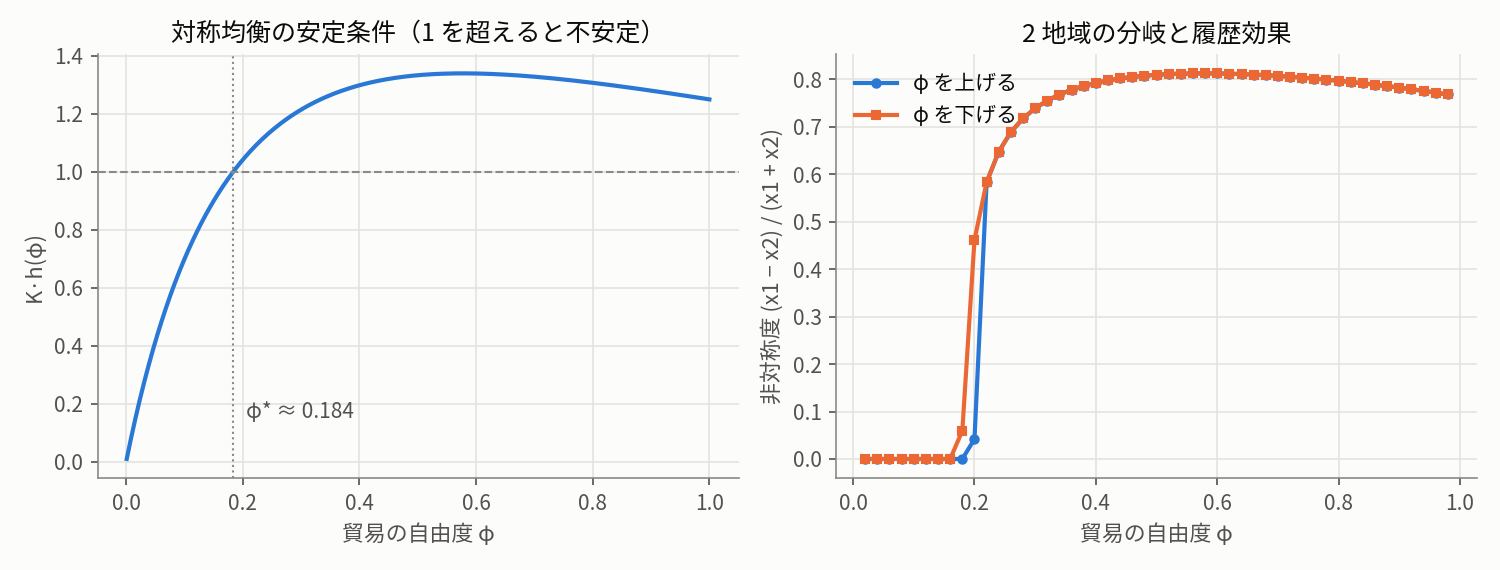

In [22]:
!cd sims && python3 sim1_core_periphery.py > /dev/null && echo done
s1 = json.load(open('sims/out/sim1.json', encoding='utf-8'))
t = s1['two_region']
print(f"K = {t['K']:.3f}, 閾値 φ* = {t['phi_critical']}, h の最大点 = {t['phi_hmax']:.3f}")
display(Image('sims/fig/sim1_bifurcation.png'))

- 解析的な閾値 φ\* ≈ 0.184 で対称性が破れる。数値計算の分岐図（φ を上げる掃引と下げる掃引）もこれと一致する。
- 履歴効果は φ ≈ 0.18〜0.20 のわずかな幅にしかない。これはこのモデルの性質として、そのまま報告する。

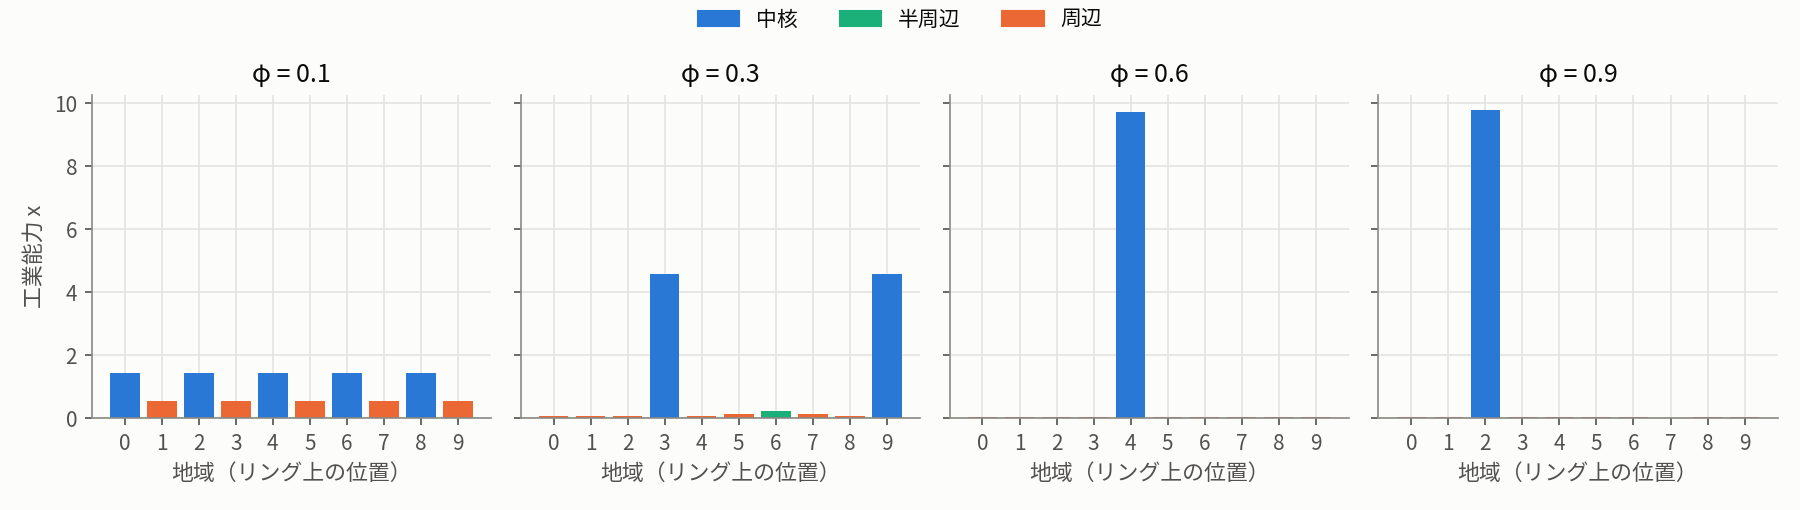

φ=0.1: 階層 = ['中核', '周辺', '中核', '周辺', '中核', '周辺', '中核', '周辺', '中核', '周辺']
        体化労働の交換比率（輸出/輸入）: 最小 0.69, 最大 1.47
φ=0.3: 階層 = ['周辺', '周辺', '周辺', '中核', '周辺', '周辺', '半周辺', '周辺', '周辺', '中核']
        体化労働の交換比率（輸出/輸入）: 最小 0.43, 最大 2.28
φ=0.6: 階層 = ['周辺', '周辺', '周辺', '周辺', '中核', '周辺', '周辺', '周辺', '周辺', '周辺']
        体化労働の交換比率（輸出/輸入）: 最小 0.31, 最大 3.21
φ=0.9: 階層 = ['周辺', '周辺', '中核', '周辺', '周辺', '周辺', '周辺', '周辺', '周辺', '周辺']
        体化労働の交換比率（輸出/輸入）: 最小 0.30, 最大 3.16


In [23]:
display(Image('sims/fig/sim1_ring10.png'))
for p, d in s1['ring10'].items():
    ux = d['unequal_exchange']
    print(f"φ={p}: 階層 = {d['tiers']}\n        体化労働の交換比率（輸出/輸入）: 最小 {min(ux):.2f}, 最大 {max(ux):.2f}")

- 10 地域では、φ = 0.3 で中核が二つでき、その間にある地域が半周辺になる（二つの市場への近さ。IROWS の interstitial の論点）。φ ≥ 0.6 では中核が一つになる。
- **不等価交換**: 周辺の体化労働の交換比率は 1.5〜3.2 である。周辺は、受け取る労働の数倍の労働を渡している。

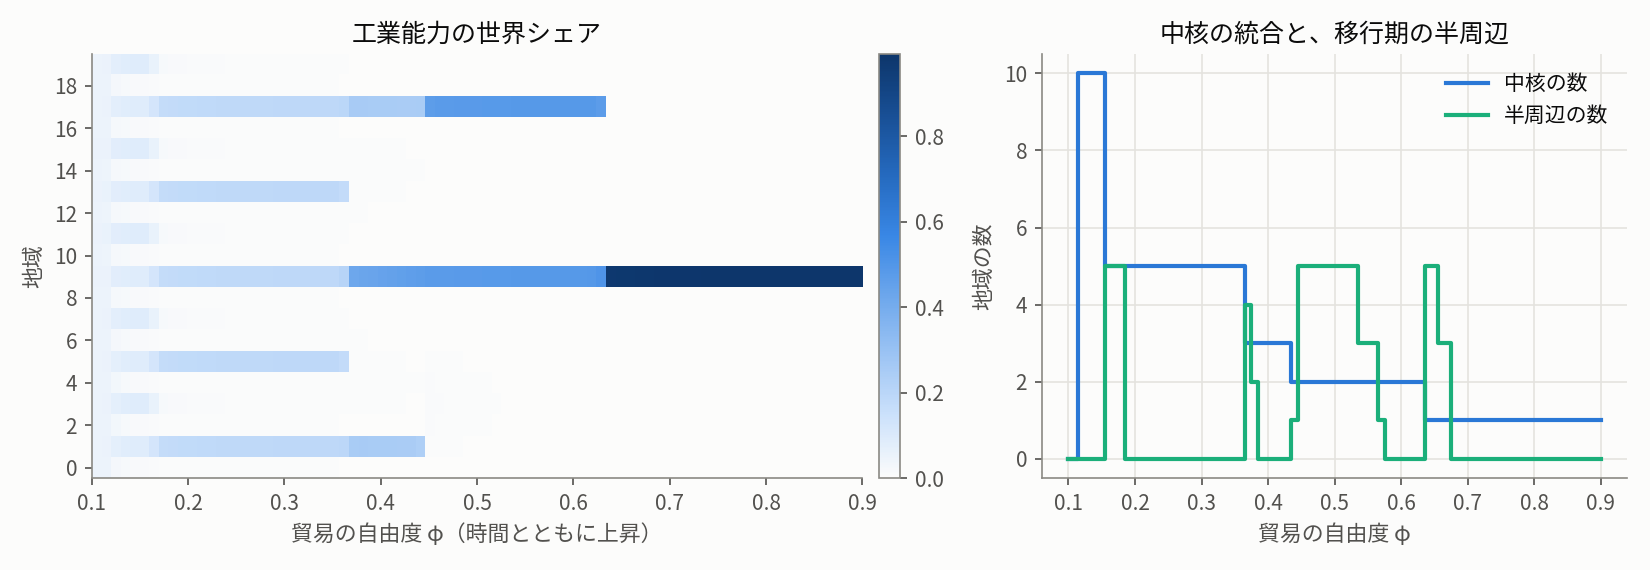

φ と中核・半周辺の数: [(0.1, 0, 0), (0.18, 5, 5), (0.26, 5, 0), (0.34, 5, 0), (0.42, 3, 0), (0.5, 2, 5), (0.58, 2, 0), (0.66, 1, 3), (0.74, 1, 0), (0.82, 1, 0), (0.9, 1, 0)]
周辺の一次産業所得を 20% 下げたときの所得の変化（%）: {'periphery': -19.98352758906935, 'core': -16.288828388050923} {'periphery': -18.580637509680244, 'core': -17.499089183899976}


In [24]:
display(Image('sims/fig/sim1_globalization.png'))
g = s1['globalization']
print('φ と中核・半周辺の数:', [(round(p, 2), c, s) for p, c, s in zip(g['phi'][::8], g['n_core'][::8], g['n_semi'][::8])])
ins = s1['insulation']
print('周辺の一次産業所得を 20% 下げたときの所得の変化（%）:', ins['short_run_pct'], ins['long_run_pct'])

- **グローバル化の経路**（20 地域、φ を時間とともに 0.1 から 0.9 へ）: 中核は 10 → 5 → 3 → 2 → 1 と統合されていく（ヘゲモニーへの集中）。
- 半周辺は**統合の移行期にだけ**現れる（没落しつつある中核と、上昇しつつある周辺）。ウォーラーステインの半周辺の理解と合う。
- **正直に記録する結果**: 周辺の一次産業所得の総額を 20% 下げると、中核の所得も 16〜17% 下がる（需要を通じた波及）。
  - したがって「周辺の不平等が中核に及ばない」という命題は、周辺の所得の**総額**については、このモデルでは成り立たない。
  - この命題は、周辺の**内部での分配**について Sim 2 で検証する。

## 7. Sim 2: 周辺における非正規雇用

### 7.1 モデル（外資の退出オプションと二重労働市場）

- 地域には、労働者 L 人と、異質な企業が多数ある。職の総数は λL で、λ < 1 なら労働余剰がある（Lewis 1954）。
- **企業**は、安定した職ごとに、正規の価値 $V_R$ と非正規の価値 $V_N$ を比べて正規か非正規かを選ぶ。
  - $V_R = (1+s)p - w_R(s) - (h+\rho)Fp$: 技能による生産性の上乗せ s がつく一方、撤退・離職のとき解雇費用 Fp がかかる。h は撤退ハザードで、外資は $h_F$、国内資本は $h_D$。
  - $V_N = p - w_N - cp$: 非正規は入れ替えの費用 cp だけがかかる。
  - 需要の変動にさらされる職は非正規とする。
- **正規の賃金**はナッシュ交渉で決まる: $w_R(s) = b + \beta((1+s)p - b)$。
- **非正規の賃金**（Harris & Todaro 1970 型）:
  - 非正規の層は、契約の切れ目のため固有の割合 $e_0$ で職がない。
  - それ以外の労働者は正規職の列に並ぶので、正規職に就ける確率は $q = \min(1, J_R/(L - J_N/(1-e_0)))$。
  - 列に並ぶことと非正規で働くことの期待所得が等しいことから、$w_N = b + q(\bar w_R - b)/(1-e_0)$。

ここから次のことが従う（第 11 章で Lean により示す）。

$$w_N < \bar w_R \iff q < 1-e_0 \iff \lambda < 1-e_0$$

非正規の割合 ν は式から消える。**賃金の序列が反転する（補償賃金 → 身分賃金）かは労働余剰だけで決まり、資本の移動性は非正規の「量」と反転の「深さ」を決める**。

中核は λ = 0.97・外資 10%、周辺は λ = 0.70・外資 60% とする。生産性の比は Sim 1 から取る（3.23）。

In [25]:
%%writefile sims/sim2_labor_market.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Sim 2: 周辺における非正規雇用 ―― 外資の退出オプションと二重労働市場

地域 r（中核 C / 周辺 P）に、労働者 L 人と、異質な企業（職のまとまり）が多数ある。
  職の総数 J = λ L（λ < 1 なら労働余剰。Lewis 1954）
  企業 i: 技能の上乗せ s_i（正規で長く働くと生産性が (1+s_i) 倍）、需要の変動にさらされる職の割合 σ_i、
          外資か国内資本か（外資の撤退ハザード h_F、国内資本 h_D）
  変動する職は非正規。安定した職は、正規の価値 V_R が非正規の価値 V_N を上回るときに正規にする:
    V_R = (1+s) p − w_R(s) − (h + ρ) F p        （撤退・離職のとき解雇費用 F p がかかる）
    V_N = p − w_N − c p                         （非正規は入れ替えの費用 c p だけ）
  正規の賃金（ナッシュ交渉）: w_R(s) = b + β((1+s) p − b)
  非正規の賃金（Harris & Todaro 1970 型の無差別条件。企業は非正規の職を埋められる最低の賃金を提示する）:
    非正規の層は契約の切れ目のため、固有の割合 e0 で職がない。非正規の職 J_N を埋めるには J_N/(1−e0) 人が要る。
    それ以外の労働者は正規職の列に並ぶので、正規職に就ける確率は
      q = min(1, J_R / (L − J_N/(1−e0)))
    列に並ぶ期待所得  q w̄_R + (1−q) b  =  非正規の期待所得  (1−e0) w_N + e0 b
    → w_N = b + q (w̄_R − b) / (1 − e0)
  したがって  w_N < w̄_R  ⟺  q < 1 − e0  （補償賃金の原則が「身分賃金」に反転する条件。Lean で示す）
  労働余剰がなければ q = 1 で w_N > w̄_R（補償賃金、Rosen 1986）。余剰が大きいほど q は小さくなる。
  さらに、J_R = (1−ν)λL、J_N = νλL（ν: 非正規の職の割合）を代入すると、q < 1 − e₀ ⟺ λ < 1 − e₀ となり、ν が消える。
  つまり賃金の序列が反転するかは労働余剰（職の充足率 λ）だけで決まり、資本の移動性は非正規の「量」と反転の「深さ」を決める。
外資の利潤は中核へ送金される（周辺から中核への余剰移転）。
"""
import json
import os
import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))


class Region:
    def __init__(self, name, p=1.0, b=0.3, lam=0.7, foreign=0.6, hF=0.15, hD=0.02, L=1.0,
                 F=1.0, beta=0.4, rho=0.02, c=0.05, s_max=0.6, sigma_max=0.6, e0=0.2, n_firms=4000, seed=1):
        self.name, self.p, self.b, self.lam, self.foreign = name, p, b, lam, foreign
        self.hF, self.hD, self.L, self.F, self.beta, self.rho, self.c = hF, hD, L, F, beta, rho, c
        self.e0 = e0
        rng = np.random.default_rng(seed)
        self.s = rng.uniform(0, s_max, n_firms)
        self.sigma = rng.uniform(0, sigma_max, n_firms)
        self.is_foreign = rng.uniform(0, 1, n_firms) < foreign
        self.size = lam * L / n_firms          # 各企業の職の数

    def h(self):
        return np.where(self.is_foreign, self.hF, self.hD)

    def firm_choice(self, wN):
        p, b = self.p, self.b
        wR = b + self.beta * ((1 + self.s) * p - b)
        VR = (1 + self.s) * p - wR - (self.h() + self.rho) * self.F * p
        VN = p - wN - self.c * p
        reg = VR > VN
        stable = (1 - self.sigma) * self.size
        J_R = np.where(reg, stable, 0.0)
        J_N = self.size - J_R
        return reg, wR, J_R, J_N, VR, VN

    def queue_prob(self, JR, JN):
        rest = self.L - JN / (1 - self.e0)
        return 1.0 if rest <= JR else JR / rest

    def equilibrium(self, iters=600, damp=0.3, start='high'):
        """start='high': 補償賃金の水準から、start='low': 生存水準 b から反復を始める。
        両者が違う点に収束すれば、補償賃金の均衡と身分賃金の均衡が両方とも存在する（複数均衡）。"""
        wN = self.b if start == 'low' else self.b + (self.b + self.beta * (self.p - self.b) - self.b) / (1 - self.e0) * 1.2
        for _ in range(iters):
            reg, wR, J_R, J_N, VR, VN = self.firm_choice(wN)
            JR, JN = J_R.sum(), J_N.sum()
            q = self.queue_prob(JR, JN)
            wRbar = (wR * J_R).sum() / JR if JR > 0 else self.b + self.beta * (self.p - self.b)
            target = self.b + q * (wRbar - self.b) / (1 - self.e0)
            wN_new = (1 - damp) * wN + damp * target
            if abs(wN_new - wN) < 1e-10:
                wN = wN_new
                break
            wN = wN_new
        reg, wR, J_R, J_N, VR, VN = self.firm_choice(wN)
        JR, JN = J_R.sum(), J_N.sum()
        q = self.queue_prob(JR, JN)
        e = self.e0
        wRbar = (wR * J_R).sum() / JR if JR > 0 else self.b + self.beta * (self.p - self.b)
        # 外資の利潤（中核への送金）: 正規・非正規それぞれの職の価値の合計
        profit = np.where(reg, (1 - self.sigma) * self.size * VR, 0.0) + J_N * VN
        foreign_profit = float(profit[self.is_foreign].sum())
        # 身分賃金による移転: 補償賃金（q = 1 のときの水準）と実際の非正規賃金の差 × 外資の非正規の職
        wN_comp = self.b + (wRbar - self.b) / (1 - self.e0)
        status_rent = float(max(wN_comp - wN, 0.0) * J_N[self.is_foreign].sum())
        stable = (1 - self.sigma) * self.size
        def stable_nonreg(mask):
            st = stable[mask].sum()
            return float(stable[mask][~reg[mask]].sum() / st) if st > 0 else float('nan')
        wage_bill = float((wR * J_R).sum() + wN * JN)
        output = float((np.where(reg, (1 + self.s), 1.0) * (1 - self.sigma) * self.size).sum() * self.p
                       + (self.sigma * self.size).sum() * self.p)
        return {'region': self.name, 'start': start, 'w_N': float(wN), 'w_R_bar': float(wRbar), 'q': float(q), 'e': float(e),
                'one_minus_e': float(1 - e), 'nonregular_share': float(JN / (JR + JN)),
                'inverted': bool(wN < wRbar), 'foreign_profit': foreign_profit,
                'w_N_compensating': float(wN_comp), 'status_rent_to_core': status_rent,
                'stable_nonregular_foreign': stable_nonreg(self.is_foreign),
                'stable_nonregular_domestic': stable_nonreg(~self.is_foreign),
                'labor_share': wage_bill / output, 'output': output}


def both(region):
    """高い出発点と低い出発点からの均衡。regime: 'compensating'（補償のみ）/'status'（身分のみ）/'both'（両方）"""
    hi, lo = region.equilibrium(start='high'), region.equilibrium(start='low')
    kinds = {('status' if r['inverted'] else 'compensating') for r in (hi, lo)}
    distinct = abs(hi['w_N'] - lo['w_N']) > 1e-4 or abs(hi['q'] - lo['q']) > 1e-4
    regime = 'both' if (distinct and len(kinds) == 2) else kinds.pop()
    return hi, lo, regime


def sweep_mobility(hF_values, **kw):
    return [Region(hF=h, **kw).equilibrium() for h in hF_values]


def main(make_figs=True):
    out = {}
    s1 = json.load(open(os.path.join(HERE, 'out', 'sim1.json'), encoding='utf-8'))['handoff']
    # Sim 1 から: 中核と周辺の工業生産性の比
    pC, pP = s1['A_core'] / s1['A_periphery'], 1.0
    out['params'] = {'p_core': pC, 'p_periphery': pP}
    core_kw = dict(name='中核', p=pC, b=0.45 * pC, lam=0.97, foreign=0.1, hD=0.02)
    per_kw = dict(name='周辺', p=pP, b=0.30 * pP, lam=0.70, foreign=0.6, hD=0.02)
    # (i) 外資の撤退ハザード（資本の移動性）を上げていく
    hs = np.linspace(0.0, 0.4, 41)
    out['mobility'] = {'hF': hs.tolist(),
                       'core': sweep_mobility(hs, **core_kw),
                       'periphery': sweep_mobility(hs, **per_kw)}
    # (ii) 相図: 職の充足率 λ × 外資の撤退ハザード h_F（周辺の他のパラメータで）
    lams = np.linspace(0.5, 1.0, 26)
    hs2 = np.linspace(0.0, 0.4, 21)
    gap = np.zeros((len(lams), len(hs2)))
    nonreg = np.zeros_like(gap)
    regime = np.zeros_like(gap)            # 0 = 補償のみ, 1 = 両方（複数均衡）, 2 = 身分のみ
    code = {'compensating': 0, 'both': 1, 'status': 2}
    for i, lam in enumerate(lams):
        for j, h in enumerate(hs2):
            kw = dict(per_kw)
            kw['lam'] = lam
            hi, lo, rg = both(Region(hF=h, n_firms=1500, **kw))
            gap[i, j] = hi['w_N'] / hi['w_R_bar'] - 1
            nonreg[i, j] = hi['nonregular_share']
            regime[i, j] = code[rg]
    out['phase'] = {'lam': lams.tolist(), 'hF': hs2.tolist(), 'wage_gap': gap.tolist(), 'nonregular': nonreg.tolist(),
                    'regime': regime.tolist(), 'regime_code': code}
    # (iii) 内なる周辺化: 中核の国内資本も移動しやすくなり（h_D↑）、職の充足率も下がる（λ↓）経路
    path = []
    for k in range(81):
        t = k / 80
        kw = dict(core_kw)
        kw['hD'] = 0.02 + 0.18 * t
        kw['lam'] = 0.97 - 0.22 * t
        hi, lo, rg = both(Region(hF=0.05 + 0.25 * t, **kw))
        hi['t'] = t
        hi['low'] = lo
        hi['regime'] = rg
        path.append(hi)
    out['inner_periphery'] = path
    # (iv) 周辺の非正規化と中核への余剰移転
    out['transfer'] = [{'hF': float(h), **{k: r[k] for k in ('status_rent_to_core', 'foreign_profit', 'labor_share', 'nonregular_share')}}
                       for r, h in zip(out['mobility']['periphery'], hs)]
    # 第 3 部への引き渡し: 代表的な周辺（h_F = 0.25）と中核（h_F = 0.05）の値
    hp, lp, rp = both(Region(hF=0.25, **per_kw))
    hc, lc, rc = both(Region(hF=0.05, **core_kw))
    out['handoff'] = {'periphery': {'high': hp, 'low': lp, 'regime': rp},
                      'core': {'high': hc, 'low': lc, 'regime': rc}, 'hF_periphery': 0.25, 'hF_core': 0.05}
    with open(os.path.join(HERE, 'out', 'sim2.json'), 'w', encoding='utf-8') as f:
        json.dump(out, f, ensure_ascii=False, indent=1)
    if make_figs:
        figures(out)
    return out


def figures(out):
    from vizstyle import setup, BLUE, ORANGE, AQUA, INK2, MUTED, DIV
    plt = setup()
    figdir = os.path.join(HERE, 'fig')
    mob = out['mobility']
    hs = mob['hF']
    # 図 2-1: 資本の移動性と非正規比率・賃金比
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    ax = axes[0]
    for key, col in (('core', BLUE), ('periphery', ORANGE)):
        ax.plot(hs, [r['nonregular_share'] for r in mob[key]], color=col, label=mob[key][0]['region'])
    ax.set_xlabel('外資の撤退ハザード h_F（資本の移動性）')
    ax.set_ylabel('非正規の職の割合')
    ax.set_title('資本の移動性と非正規化')
    ax.legend(loc='upper left')
    ax = axes[1]
    for key, col in (('core', BLUE), ('periphery', ORANGE)):
        ax.plot(hs, [r['w_N'] / r['w_R_bar'] for r in mob[key]], color=col, label=mob[key][0]['region'])
    ax.axhline(1, color=MUTED, lw=1, ls='--')
    ax.annotate('補償賃金（非正規が高い）', (0.25, 1.0), xytext=(0, 6), textcoords='offset points', color=INK2)
    ax.annotate('身分賃金（非正規が低い）', (0.25, 1.0), xytext=(0, -14), textcoords='offset points', color=INK2)
    ax.set_xlabel('外資の撤退ハザード h_F（資本の移動性）')
    ax.set_ylabel('非正規の賃金 / 正規の平均賃金')
    ax.set_title('賃金の序列の反転')
    ax.legend(loc='lower left')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim2_mobility.png'))
    plt.close(fig)
    # 図 2-2: 相図（周辺のパラメータ。色は w_N/w̄_R − 1、0 で反転）
    ph = out['phase']
    G = np.array(ph['wage_gap'])
    from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
    cmap = LinearSegmentedColormap.from_list('div', DIV[::-1])
    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    lim = np.nanmax(np.abs(G))
    im = ax.imshow(G, origin='lower', aspect='auto', cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim),
                   extent=(ph['hF'][0], ph['hF'][-1], ph['lam'][0], ph['lam'][-1]))
    ax.contour(ph['hF'], ph['lam'], G, levels=[0], colors=[INK2], linewidths=1.5)
    ax.grid(False)
    ax.set_xlabel('外資の撤退ハザード h_F')
    ax.set_ylabel('職の充足率 λ（労働者 1 人あたりの職）')
    ax.set_title('非正規の賃金プレミアム w_N / w̄_R − 1（実線は 0）')
    fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim2_phase.png'))
    plt.close(fig)
    # 図 2-3: 内なる周辺化と、q と 1−e の交差
    ip = out['inner_periphery']
    t = [r['t'] for r in ip]
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    ax = axes[0]
    ax.plot(t, [r['q'] for r in ip], color=BLUE, label='q（正規職に就ける確率）')
    ax.plot(t, [r['one_minus_e'] for r in ip], color=ORANGE, label='1 − e0（非正規の就業率）')
    ax.set_xlabel('中核のグローバル化の進行（0 → 1）')
    ax.set_ylabel('確率')
    ax.set_title('中核での反転条件 q < 1 − e0')
    ax.legend(loc='center left')
    ax = axes[1]
    ax.plot(t, [r['nonregular_share'] for r in ip], color=BLUE, label='非正規の職の割合')
    ax.plot(t, [r['w_N'] / r['w_R_bar'] for r in ip], color=AQUA, label='非正規の賃金 / 正規の平均賃金')
    ax.axhline(1, color=MUTED, lw=1, ls='--')
    ax.set_xlabel('中核のグローバル化の進行（0 → 1）')
    ax.set_title('内なる周辺化（仮説の例示）')
    ax.legend(loc='center left')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim2_inner_periphery.png'))
    plt.close(fig)
    # 図 2-4: 身分賃金による周辺から中核への移転
    tr = out['transfer']
    fig, ax = plt.subplots(figsize=(5.6, 3.6))
    ax.plot([r['hF'] for r in tr], [r['status_rent_to_core'] for r in tr], color=ORANGE)
    ax.set_xlabel('外資の撤退ハザード h_F')
    ax.set_ylabel('移転額（周辺の労働者 1 人あたり）')
    ax.set_title('身分賃金による周辺から中核への移転')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim2_transfer.png'))
    plt.close(fig)


if __name__ == '__main__':
    import sys
    sys.path.insert(0, HERE)
    o = main()
    for key in ('core', 'periphery'):
        for r in o['mobility'][key][::10]:
            print(key, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})
    print('handoff', json.dumps(o['handoff'], ensure_ascii=False)[:800])
    for r in o['inner_periphery'][::5]:
        print('inner', round(r['t'], 2), round(r['q'], 3), round(r['one_minus_e'], 3), round(r['nonregular_share'], 3), round(r['w_N'] / r['w_R_bar'], 3))

Overwriting sims/sim2_labor_market.py


done


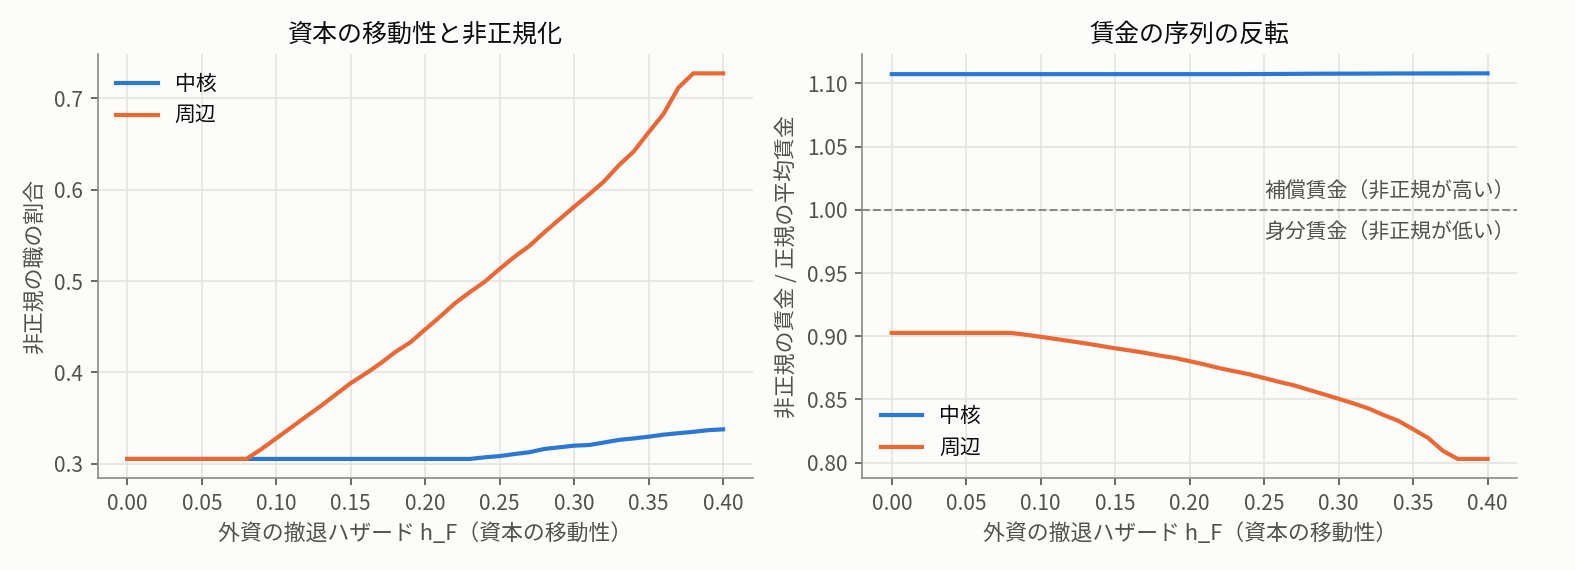

中核 非正規の職の割合 h_F=0 → 0.4: 0.305 → 0.338 ／ 非正規の賃金 / 正規の平均賃金: 1.107 → 1.108
周辺 非正規の職の割合 h_F=0 → 0.4: 0.305 → 0.727 ／ 非正規の賃金 / 正規の平均賃金: 0.903 → 0.803


In [26]:
!cd sims && python3 sim2_labor_market.py > /dev/null && echo done
s2 = json.load(open('sims/out/sim2.json', encoding='utf-8'))
display(Image('sims/fig/sim2_mobility.png'))
for key in ('core', 'periphery'):
    rs = s2['mobility'][key]
    print(rs[0]['region'], '非正規の職の割合 h_F=0 → 0.4:', round(rs[0]['nonregular_share'], 3), '→', round(rs[-1]['nonregular_share'], 3),
          '／ 非正規の賃金 / 正規の平均賃金:', round(rs[0]['w_N'] / rs[0]['w_R_bar'], 3), '→', round(rs[-1]['w_N'] / rs[-1]['w_R_bar'], 3))

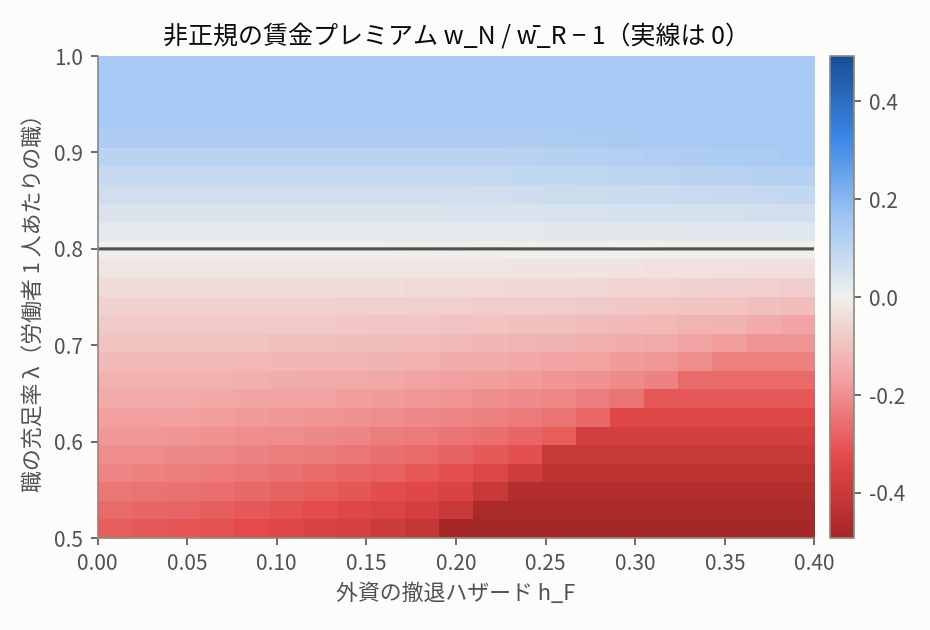

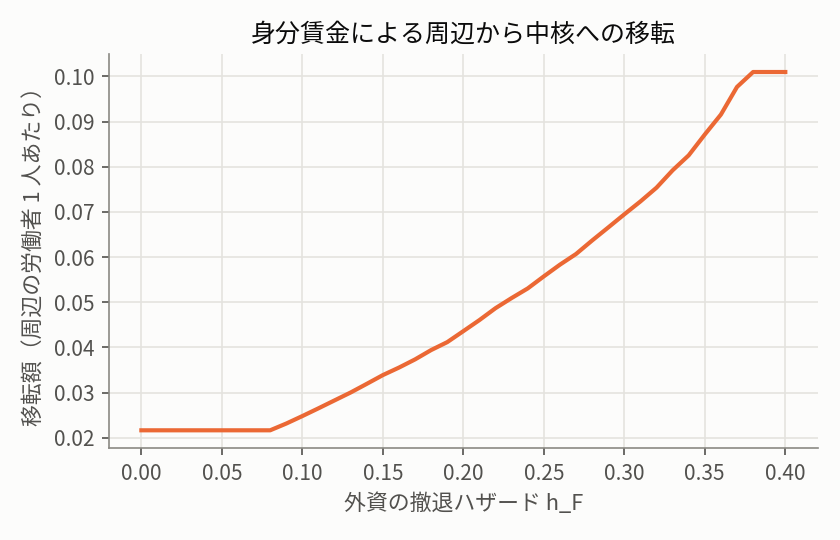

身分賃金による中核への移転（h_F = 0 → 0.4）: 0.022 → 0.101


In [27]:
display(Image('sims/fig/sim2_phase.png'))
display(Image('sims/fig/sim2_transfer.png'))
tr = s2['transfer']
print('身分賃金による中核への移転（h_F = 0 → 0.4）:', round(tr[0]['status_rent_to_core'], 3), '→', round(tr[-1]['status_rent_to_core'], 3))

- **相図**の境界（実線）は、λ = 0.8 = 1 − e₀ の水平線になる。撤退ハザードは境界を動かさず、反転の深さを変える。
- **中核への移転**: 外資が身分賃金によって得る差額（補償賃金の水準 − 実際の賃金）× 非正規の職の数は、撤退ハザードとともに増える。その間、中核の賃金は変わらない。これが、このモデルにおける「周辺の不平等の効果は中核に及ばない（むしろ中核に移転される）」の意味である。

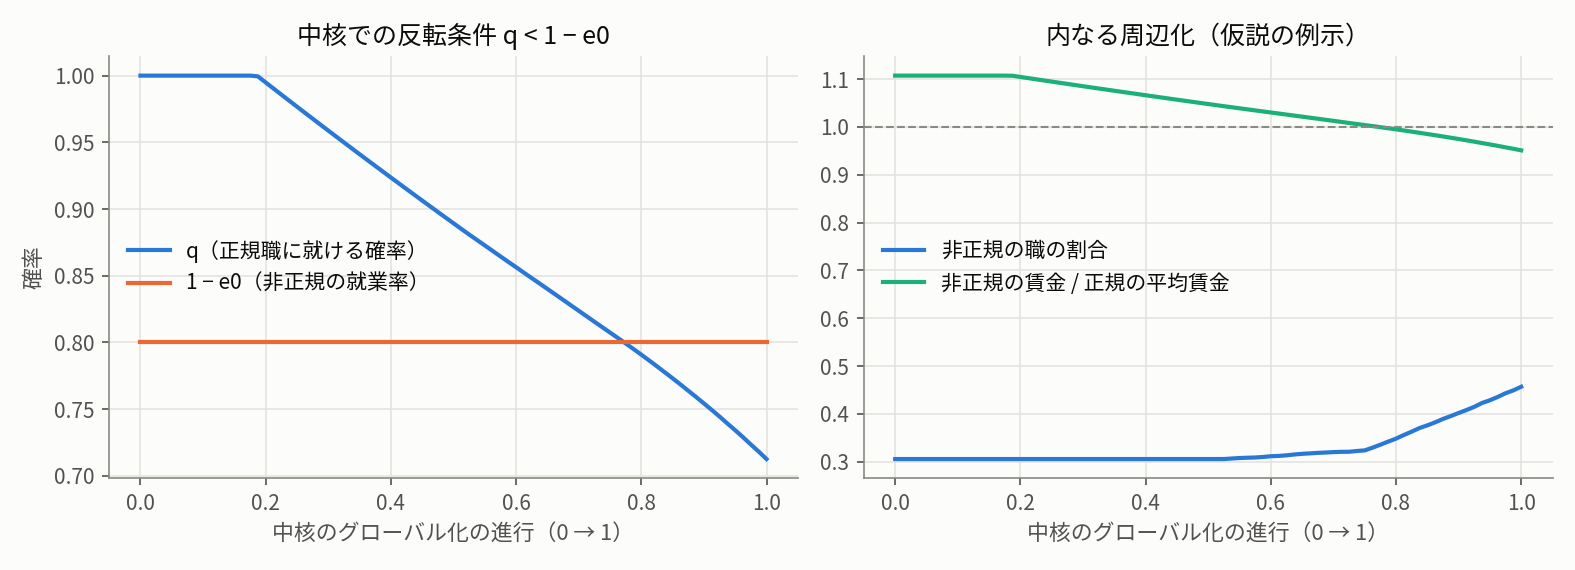

中核のグローバル化の進行 t で、身分賃金が現れる点: t ≈ 0.775


In [28]:
display(Image('sims/fig/sim2_inner_periphery.png'))
ip = s2['inner_periphery']
cross = next(r['t'] for r in ip if r['w_N'] < r['w_R_bar'])
print('中核のグローバル化の進行 t で、身分賃金が現れる点: t ≈', cross)

**内なる周辺化（仮説の例示）**: 中核でも、国内資本が移動しやすくなり（$h_D$ が上がる）、職の充足率が下がる経路では、ある点（t ≈ 0.78）で q が 1 − e₀ を下回り、中核にも身分賃金が現れる。

これは JRF の問題意識（日本の「失われたウン十年」と非正規雇用の拡大）に対応する仮説の**例示**にとどまる。実証ではない。

そのほか、正直に記録しておくことが二つある。

- 低い賃金から反復を始めると、臨界点を越えたところで「全面的な非正規化」（q = 0）の均衡に落ちることがある。
- 補償賃金と身分賃金が両方とも均衡になる双安定の領域は、このモデルにはなかった。慣行の選択は Sim 3 で扱う。

## 8. Sim 3: 事実から慣習規範へ

### 8.1 モデル（慣行の進化）

企業と労働者の二つの母集団が、非正規の契約をどちらの慣行で結ぶかを、Young (1993) の適応的プレイで選ぶ。

- 慣行は二つ: **A = 補償原則**（賃金 $w_A$ = Sim 2 の補償賃金の水準）と、**B = 身分秩序**（賃金 $w_B$ = 周辺の非正規・正規の賃金比を当てはめた水準）。
- 慣行が一致すれば契約が成立し、労働者は $w_X$、企業は $\pi_X = p - w_X - cp$ を得る。
- 食い違えば契約は成立せず、労働者は外部オプション $u_W = q\bar w_R + (1-q)b$（正規職の列に並ぶ価値）を、企業は**退出オプション** $o_F$ を得る。

B が A よりリスク支配的である条件（Harsanyi & Selten 1988）は次のとおりである。

$$(w_B - u_W)(\pi_B - o_F) > (w_A - u_W)(\pi_A - o_F)$$

左辺から右辺を引いたもの（リスク支配度）は、$o_F$ について狭義増加する（Lean で示す）。Young (1993) によれば、2×2 の協調ゲームの適応的プレイで確率的に安定な慣行は、リスク支配的な均衡である。

In [29]:
%%writefile sims/sim3_convention.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Sim 3: 事実から慣習規範へ ―― 非正規の賃金をめぐる慣行の進化（Young 1993 の適応的プレイ）

企業と労働者の二つの母集団が、非正規の契約をどちらの慣行で結ぶかを選ぶ協調ゲーム:
  A = 補償原則（非正規はリスクの分だけ高く払う。賃金 w_A = Sim 2 の補償賃金の水準）
  B = 身分秩序（非正規は身分が低いので安くてよい。賃金 w_B = Sim 2 の周辺の非正規賃金の比率）
慣行が一致すれば契約が成立し、労働者は w_X、企業は π_X = p − w_X − c p を得る。
食い違えば契約は成立せず、労働者は外部オプション u_W = q w̄_R + (1−q) b（Harris–Todaro の列に並ぶ価値）を、
企業は退出オプション o_F（資本の移動性による、移転先での価値）を得る。

B が A よりリスク支配的（Harsanyi & Selten 1988）である条件:
  (w_B − u_W)(π_B − o_F) > (w_A − u_W)(π_A − o_F)
Young (1993) によれば、2×2 の協調ゲームの適応的プレイで確率的に安定な慣行は、リスク支配的な均衡である。
企業の退出オプション o_F が大きいほど B が有利になる（π_A < π_B のとき。Lean で示す）。
"""
import json
import os
import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))


def payoffs(region):
    """Sim 2 の結果から、慣行 A / B の賃金と利潤、労働者の外部オプションを作る"""
    return region


def risk_dominance_B(g, oF):
    """B のリスク支配度: (w_B−u)(π_B−o) − (w_A−u)(π_A−o)。B が均衡でなければ −inf"""
    wA, wB, piA, piB, u = g['wA'], g['wB'], g['piA'], g['piB'], g['uW']
    if wB <= u or piB <= oF:
        return -np.inf
    if wA <= u or piA <= oF:
        return np.inf
    return (wB - u) * (piB - oF) - (wA - u) * (piA - oF)


def penalty_needed(g, oF):
    """B を罰する法（同一労働同一賃金の執行）が、企業の B の利潤を P だけ下げるとき、A をリスク支配的にする最小の P"""
    wA, wB, piA, piB, u = g['wA'], g['wB'], g['piA'], g['piB'], g['uW']
    if wB <= u:
        return 0.0                     # B はもともと均衡でない
    return max(0.0, piB - oF - (wA - u) * (piA - oF) / (wB - u))


def adaptive_play(g, oF, T=40000, m=20, k=6, eps=0.03, penalty=0.0, seed=1, start='A'):
    """Young (1993) の適応的プレイ。毎期 1 組の企業と労働者が出会い、それぞれ相手の母集団の直近 m 回の
    行動から k 個を見本として取り、その頻度に対する最適反応を選ぶ（確率 eps で無作為に選ぶ）。
    戻り値: 各期に結ばれた契約が B だったかどうか（食い違いは None）"""
    rng = np.random.default_rng(seed)
    wA, wB, piA, piB, u = g['wA'], g['wB'], g['piA'], g['piB'] - penalty, g['uW']
    hist_F = [start] * m
    hist_W = [start] * m
    outcome = np.zeros(T, dtype=np.int8)       # 1 = B で成立, 0 = A で成立, -1 = 不成立
    for t in range(T):
        sW = rng.choice(hist_W, size=k, replace=False)   # 企業が見る労働者の行動
        sF = rng.choice(hist_F, size=k, replace=False)   # 労働者が見る企業の行動
        fA = np.mean(sW == 'A')
        gA = np.mean(sF == 'A')
        # 企業の期待利得
        eFA = fA * piA + (1 - fA) * oF
        eFB = (1 - fA) * piB + fA * oF
        aF = 'A' if eFA > eFB else ('B' if eFB > eFA else rng.choice(['A', 'B']))
        # 労働者の期待利得
        eWA = gA * wA + (1 - gA) * u
        eWB = (1 - gA) * wB + gA * u
        aW = 'A' if eWA > eWB else ('B' if eWB > eWA else rng.choice(['A', 'B']))
        if rng.random() < eps:
            aF = rng.choice(['A', 'B'])
        if rng.random() < eps:
            aW = rng.choice(['A', 'B'])
        outcome[t] = (1 if aF == 'B' else 0) if aF == aW else -1
        hist_F = hist_F[1:] + [aF]
        hist_W = hist_W[1:] + [aW]
    return outcome


def custom_time(outcome, window=500, thr=0.9):
    """慣習の成立（opinio juris の代理指標）: 直近 window 期の成立した契約のうち B の割合が thr 以上になった最初の時点"""
    b = (outcome == 1).astype(float)
    ok = (outcome >= 0).astype(float)
    cb, co = np.cumsum(b), np.cumsum(ok)
    for t in range(window, len(outcome)):
        nb = cb[t] - cb[t - window]
        no = co[t] - co[t - window]
        if no > 0 and nb / no >= thr:
            return t
    return None


def build_games():
    s2 = json.load(open(os.path.join(HERE, 'out', 'sim2.json'), encoding='utf-8'))
    pc = s2['params']['p_core']
    out = {}
    per = s2['handoff']['periphery']['high']
    core = s2['handoff']['core']['high']
    ratio_B = per['w_N'] / per['w_R_bar']           # 身分秩序のもとでの非正規 / 正規 の賃金比（周辺の実績値）
    for name, r, p, b in (('周辺', per, 1.0, 0.30), ('中核', core, pc, 0.45 * pc)):
        c = 0.05 * p
        wA = r['w_N_compensating']
        wB = ratio_B * r['w_R_bar']
        uW = r['q'] * r['w_R_bar'] + (1 - r['q']) * b
        out[name] = {'p': p, 'b': b, 'q': r['q'], 'wA': wA, 'wB': wB, 'piA': p - wA - c, 'piB': p - wB - c,
                     'uW': uW, 'w_R_bar': r['w_R_bar']}
    return out


def main(make_figs=True):
    games = build_games()
    out = {'games': games}
    # (i) 退出オプション o_F に対するリスク支配度（解析）と、確率的に安定な慣行の頻度（シミュレーション）
    res = {}
    for name, g in games.items():
        oFs = np.linspace(0, 0.9 * g['piA'], 13)
        rd = [risk_dominance_B(g, o) for o in oFs]
        freqB = []
        for j, o in enumerate(oFs):
            fs = []
            for sd in range(3):                       # 乱数の種を変えて 3 回の平均
                oc = adaptive_play(g, o, T=30000, seed=100 + 10 * j + sd)
                done = oc[oc >= 0]
                fs.append(np.mean(done == 1))
            freqB.append(float(np.mean(fs)))
        res[name] = {'oF': oFs.tolist(), 'risk_dom_B': [float(x) if np.isfinite(x) else (1e9 if x > 0 else -1e9) for x in rd],
                     'freq_B': freqB, 'penalty_needed': [penalty_needed(g, o) for o in oFs]}
    # 解析的な閾値: リスク支配度が 0 になる o_F（周辺）
    g = games['周辺']
    wA, wB, piA, piB, u = g['wA'], g['wB'], g['piA'], g['piB'], g['uW']
    # (wB−u)(πB−o) = (wA−u)(πA−o)  →  o* = ((wB−u)πB − (wA−u)πA) / ((wB−u) − (wA−u))
    res['周辺']['oF_threshold'] = ((wB - u) * piB - (wA - u) * piA) / ((wB - u) - (wA - u))
    out['sweep'] = res
    # (ii) 周辺の時系列（はじめは補償原則 A の慣行から出発）と、慣習の成立時点
    g = games['周辺']
    oF = 0.08                                  # リスク支配の閾値（約 0.053）を超える退出オプション
    oc = adaptive_play(g, oF, T=40000, seed=7, start='A')
    ct = custom_time(oc)
    # (iii) 法的介入（同一労働同一賃金の執行で、企業の B の利潤を P 下げる）を 20000 期目から
    #   弱い介入: A をリスク支配的にするのに必要な量の 1.2 倍（B はまだ均衡）
    #   強い介入: B が企業にとって均衡でなくなる量（P > π_B − o_F）の 1.1 倍
    P_weak = 1.2 * penalty_needed(g, oF)
    P_strong = 1.1 * (g['piB'] - oF)
    oc_w = np.concatenate([oc[:20000], adaptive_play(g, oF, T=20000, seed=8, start='B', penalty=P_weak)])
    oc_s = np.concatenate([oc[:20000], adaptive_play(g, oF, T=20000, seed=9, start='B', penalty=P_strong)])
    out['timeseries'] = {'oF': oF, 'custom_time': ct, 'penalty_weak': P_weak, 'penalty_strong': P_strong,
                         'rolling_B': rolling(oc).tolist(), 'rolling_B_weak_law': rolling(oc_w).tolist(),
                         'rolling_B_strong_law': rolling(oc_s).tolist()}
    with open(os.path.join(HERE, 'out', 'sim3.json'), 'w', encoding='utf-8') as f:
        json.dump(out, f, ensure_ascii=False, indent=1)
    if make_figs:
        figures(out)
    return out


def rolling(oc, window=500, step=100):
    b = (oc == 1).astype(float)
    ok = (oc >= 0).astype(float)
    cb, co = np.concatenate([[0], np.cumsum(b)]), np.concatenate([[0], np.cumsum(ok)])
    xs = []
    for t in range(window, len(oc) + 1, step):
        no = co[t] - co[t - window]
        xs.append((cb[t] - cb[t - window]) / no if no else np.nan)
    return np.array(xs)


def figures(out):
    from vizstyle import setup, BLUE, ORANGE, AQUA, INK2, MUTED
    plt = setup()
    figdir = os.path.join(HERE, 'fig')
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    ax = axes[0]
    for name, col in (('中核', BLUE), ('周辺', ORANGE)):
        r = out['sweep'][name]
        g = out['games'][name]
        x = np.array(r['oF']) / g['piB']
        ax.plot(x, r['freq_B'], color=col, marker='o', ms=5, label=name)
        if 'oF_threshold' in r:
            th = r['oF_threshold'] / g['piB']
            ax.axvline(th, color=col, lw=1, ls=':')
            ax.annotate('リスク支配の閾値\n（解析）', (th, 0.55), xytext=(-6, 0), textcoords='offset points',
                        color=INK2, ha='right')
    ax.set_xlabel('企業の退出オプション o_F / 身分秩序での利潤 π_B')
    ax.set_ylabel('成立した契約のうち身分秩序 B の割合')
    ax.set_ylim(-0.03, 1.03)
    ax.set_title('慣行の選択（適応的プレイ）')
    ax.legend(loc='center right')
    ax = axes[1]
    ts = out['timeseries']
    t = np.arange(len(ts['rolling_B'])) * 100 + 500
    ax.plot(t, ts['rolling_B'], color=ORANGE, label='介入なし')
    ax.plot(t, ts['rolling_B_weak_law'], color=BLUE, ls='--', lw=2.4, label='弱い介入（リスク支配だけを逆転）')
    ax.annotate('弱い介入では B が続く（線が重なる）', (30000, 1.0), xytext=(0, -16), textcoords='offset points',
                color=INK2, ha='center')
    ax.plot(t, ts['rolling_B_strong_law'], color=AQUA, label='強い介入（B を維持できなくする）')
    ax.axvline(20000, color=MUTED, lw=1, ls=':')
    if ts['custom_time'] is not None:
        ax.axvline(ts['custom_time'], color=INK2, lw=1, ls='--')
        ax.annotate('慣習の成立', (ts['custom_time'], 0.5), xytext=(4, 0), textcoords='offset points', color=INK2)
    ax.set_xlabel('期')
    ax.set_ylabel('直近 500 期の B の割合')
    ax.set_ylim(-0.03, 1.03)
    ax.set_title('周辺: 補償原則から身分秩序へ、そして法的介入')
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(os.path.join(figdir, 'sim3_convention.png'))
    plt.close(fig)


if __name__ == '__main__':
    import sys
    sys.path.insert(0, HERE)
    o = main()
    print(json.dumps(o['games'], ensure_ascii=False, indent=1))
    for name, r in o['sweep'].items():
        print(name, [round(x, 3) for x in r['oF']], [round(x, 3) if abs(x) < 1e8 else x for x in r['risk_dom_B']], r['freq_B'], [round(x, 3) for x in r['penalty_needed']])
    ts = o['timeseries']
    print('custom_time', ts['custom_time'], 'P_weak', ts['penalty_weak'], 'P_strong', ts['penalty_strong'])

Overwriting sims/sim3_convention.py


done


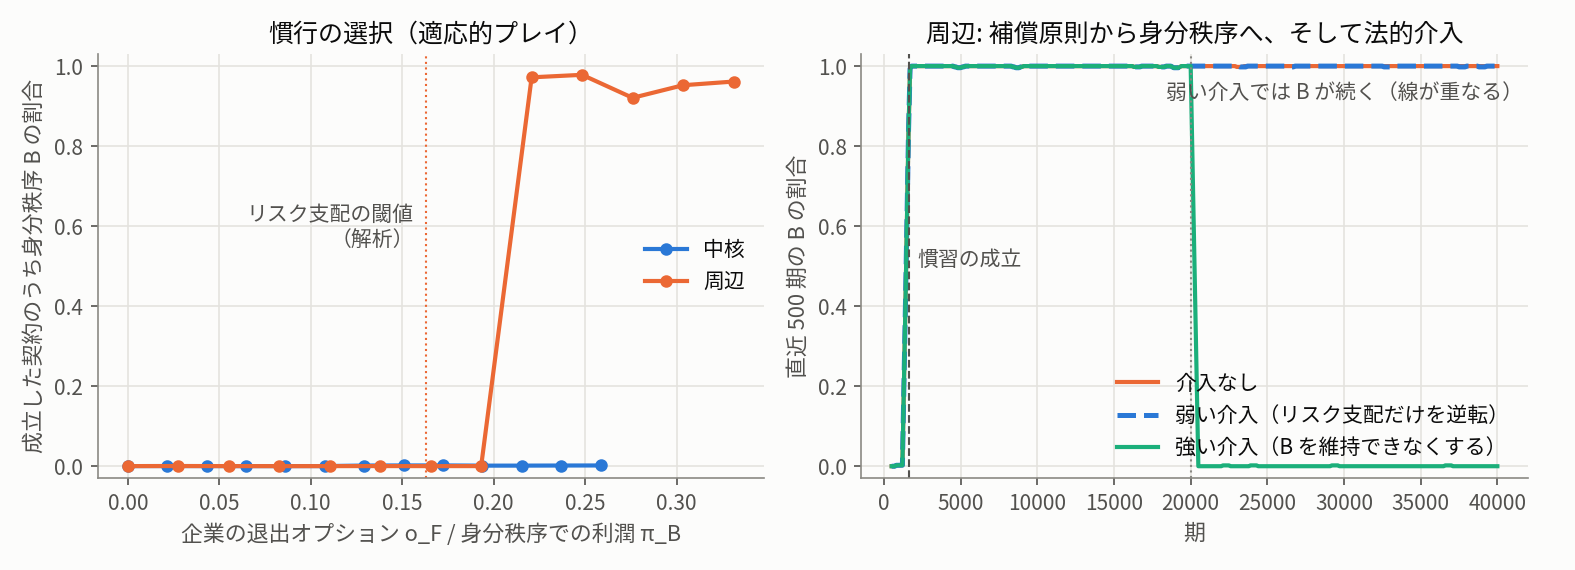

中核: w_A=2.822, w_B=2.209, u_W=2.548（q=1.000）, π_A=0.247, π_B=0.860
周辺: w_A=0.832, w_B=0.629, u_W=0.563（q=0.618）, π_A=0.118, π_B=0.321
周辺のリスク支配の閾値 o_F* = 0.052 ／ 慣習の成立: 1640 期 ／ 弱い介入 P = 0.102 ／ 強い介入 P = 0.265


In [30]:
!cd sims && python3 sim3_convention.py > /dev/null && echo done
s3 = json.load(open('sims/out/sim3.json', encoding='utf-8'))
display(Image('sims/fig/sim3_convention.png'))
g = s3['games']
for R in ('中核', '周辺'):
    x = g[R]
    print(f"{R}: w_A={x['wA']:.3f}, w_B={x['wB']:.3f}, u_W={x['uW']:.3f}（q={x['q']:.3f}）, π_A={x['piA']:.3f}, π_B={x['piB']:.3f}")
ts = s3['timeseries']
print('周辺のリスク支配の閾値 o_F* =', round(s3['sweep']['周辺']['oF_threshold'], 3),
      '／ 慣習の成立:', ts['custom_time'], '期 ／ 弱い介入 P =', round(ts['penalty_weak'], 3), '／ 強い介入 P =', round(ts['penalty_strong'], 3))

- **中核では身分秩序は均衡にならない**: q = 1 なので、身分賃金 $w_B$ は正規職の列に並ぶ価値 $u_W$（= 正規の賃金）を下回る。労働者は身分賃金を断れる。
- **周辺では両方の慣行が均衡になり**、どちらが確率的に安定かは企業の退出オプションで決まる。
  - リスク支配の閾値（解析）は $o_F$ ≈ 0.052。
  - シミュレーションでも、その少し右で、B の割合が 0 から 0.97 に跳ねる。
- **市場（労働余剰）が賃金の序列を決め、力（退出オプション）が慣行を決める**、という二層の構造になる。
- **慣習の成立**: 補償原則から出発しても、約 1,600 期で身分秩序の慣習が成立する（直近 500 期の 90% 以上が B）。
- **法的介入**（同一労働同一賃金の執行で、B の利潤を P だけ下げる）:
  - リスク支配性だけを逆転させる**弱い介入**では、慣習の慣性で B が続く。
  - B を企業にとって均衡でなくす**強い介入**では、B はすぐに崩れる。

## 9. シミュレーションから Matcha-D へ

### 9.1 機械的な変換と、その出典

`argument/build_argument.py` は、シミュレーションの結果（`sims/out/*.json`）を読み、第 3 部の論証の `.matcha` を生成する。

この生成器は汎用の道具ではなく、本レポートの論証のためだけに書いた使い捨てのコードである。それでも、`.matcha` を手で（あるいは AI に直接）書かせずに、わざわざ生成器を介した理由がある。

> AI を使うけれども、システムにはできる限り **AI が生成した決定論的コード**を使い、後から検証（注意労働）できるようにしておく。

これがこれからのセオリーだと本レポートは考える。AI に `.matcha` を直接書かせると、数値の転記や閾値との比較の誤りが、どこで入ったかを後から追えない。生成器にしておけば、どの数値がどの JSON から来て、どの比較で `+`／`!` が決まったかを、コードを読めば誰でも確かめられる。シミュレーションのパラメータを変えれば、論証も同じ手続きで作り直せる。AI の判断が本当に必要なところ（事実から評価へのあてはめ）だけが `[ai]` に残る。

- 各事実（`<=` の後）には数値をそのまま書き、直前の `//` コメントに出典（JSON のどの値か）を示す。
- 数値から法的概念への橋渡しは `@評価` として書く（例: 「撤退ハザード 0.25 は閾値 0.09 を上回る@いつでも引き上げられる」）。これが AI の審査の対象になる **neuro の部分**である。
- 閾値との比較で要件の成否（`+`／`!`）を決める。これは生成器（著者）の主張で、mext が Extension と照合する。
- Matcha の約束に従い、不成立の主張の `>>` には不成立からの帰結を書く。
- Matcha には変数がないので、規範は地域（中核・周辺・事実の分からない地域U）ごとの事件として具体化する。
- 賃金の論証は二層に分ける。**当為**（法的評価: 「非正規の賃金は正規より低くてよい」）と、**存在**（事実: 「非正規の賃金は実際に正規より低い」）である。

In [31]:
%%writefile argument/build_argument.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
build_argument.py -- シミュレーションの結果（sims/out/*.json）から、第 3 部の Matcha-D の論証ファイルを機械的に作る

方針:
  * 事実（<= の後）には数値をそのまま書き、直前の // コメントに出典（JSON のどの値か）を示す。
  * 数値から法的概念への橋渡しは @評価 として書く。評価は争いうるあてはめで、スキルが審査する（neuro の部分）。
  * 閾値との比較で要件の成否（+ / !）を決める。これは著者（このスクリプト）の主張で、mext.py が照合する。
  * Matcha には変数がないので、規範は地域（中核・周辺）ごとの事件として具体化する。

使い方: python3 argument/build_argument.py   （argument/*.matcha を書き出す）
"""
import json
import os

HERE = os.path.dirname(os.path.abspath(__file__))
SIMS = os.path.join(HERE, '..', 'sims', 'out')


def load():
    s1 = json.load(open(os.path.join(SIMS, 'sim1.json'), encoding='utf-8'))
    s2 = json.load(open(os.path.join(SIMS, 'sim2.json'), encoding='utf-8'))
    s3 = json.load(open(os.path.join(SIMS, 'sim3.json'), encoding='utf-8'))
    return s1, s2, s3


def f3(x):
    return f'{x:.3f}'.rstrip('0').rstrip('.') if isinstance(x, float) else str(x)


def facts(s1, s2, s3):
    """地域ごとの事実（数値と出典）"""
    ring = s1['ring10']['0.6']
    x = ring['x']
    tot = sum(x)
    core_i = ring['tiers'].index('中核')
    per_i = ring['tiers'].index('周辺')
    h2 = s2['handoff']
    g3 = s3['games']
    sw = s3['sweep']['周辺']
    ts = s3['timeseries']
    # 周辺の慣行: 退出オプションが閾値を超えるとき（o_F = 0.08）の B の割合。中核は同じ o_F 付近の値
    def freq_at(region, oF):
        r = s3['sweep'][region]
        k = min(range(len(r['oF'])), key=lambda i: abs(r['oF'][i] - oF))
        return r['freq_B'][k], r['oF'][k]
    fbP, oP = freq_at('周辺', ts['oF'])
    fbC, oC = freq_at('中核', ts['oF'])
    # 撤退ハザードの閾値: 周辺で非正規の割合が基準（変動する職の割合）を超え始める h_F
    mob = s2['mobility']
    base = mob['periphery'][0]['nonregular_share']
    hth = next(h for h, r in zip(mob['hF'], mob['periphery']) if r['nonregular_share'] > base + 1e-3)
    out = {}
    for R, key, idx, hF, fb, oF in (('中核', 'core', core_i, h2['hF_core'], fbC, oC),
                                     ('周辺', 'periphery', per_i, h2['hF_periphery'], fbP, oP)):
        hi = h2[key]['high']
        g = g3[R]
        out[R] = {
            'share': x[idx] / tot, 'share_src': f'sim1.json ring10["0.6"] 地域{idx} の工業能力 / 合計',
            'hF': hF, 'hF_src': f'sim2.json handoff.hF_{key}', 'h_threshold': hth,
            'h_threshold_src': 'sim2.json mobility: 周辺の非正規の割合が基準を超え始める h_F',
            'e0': 1 - hi['one_minus_e'], 'q': hi['q'], 'q_src': f'sim2.json handoff.{key}.high.q',
            'wN': hi['w_N'], 'wR': hi['w_R_bar'], 'w_src': f'sim2.json handoff.{key}.high',
            'wB': g['wB'], 'uW': g['uW'], 'g_src': f'sim3.json games.{R}',
            'freqB': fb, 'oF': oF, 'freq_src': f'sim3.json sweep.{R}.freq_B（o_F ≈ {f3(oF)}）',
            'oF_threshold': sw['oF_threshold'], 'piB': g3['周辺']['piB'],
            'P_weak': ts['penalty_weak'], 'P_strong': ts['penalty_strong'],
            'P_need': g3['周辺']['piB'] - ts['oF'],
            'nonreg': hi['nonregular_share'],
            'stable_nr_foreign': hi['stable_nonregular_foreign'],
            'stable_nr_domestic': hi['stable_nonregular_domestic'],
            'stable_src': f'sim2.json handoff.{key}.high.stable_nonregular_foreign / _domestic',
        }
    return out


def mark(cond):
    return '+' if cond else '!'


def concl(ok, effect, fail):
    """Matcha の約束: 成立（+）した主張の >> には効果を、不成立（!）の主張の >> には不成立からの帰結を書く"""
    return effect if ok else fail


NORMAL = '期間の定めのない雇用が通常である'          # 雇用形態: 事実上の規範秩序（何が「通常」とされるか）
OUGHT = '非正規の賃金は正規より低くてよい'           # 賃金: 法的評価（当為）
IS = '非正規の賃金は実際に正規より低い'              # 賃金: 事実（存在）


def employment(R, F, unknown=False):
    """雇用形態（事実上の規範秩序）: 中核の雇用慣行を原則とし、周辺を例外とする書き方（Grok 会話の「中央＝デフォルト」）。
    退出オプションを持つのは外資なので、対象は「外資の安定した職」とする。"""
    t = f'{R}の外資の安定した職'
    L = [f':: 雇用形態（{R}）―― 事実上の規範秩序として']
    L.append(f'#雇用安定の原則^中核の雇用慣行（労働契約法18条・労働者派遣法25条の趣旨を反映） <= {t}: (')
    L.append(f'    「業務が恒常的」 <= {R}の外資のこの職は需要の変動にさらされない')
    L.append(f') >> {NORMAL} as 雇用安定_{R}')
    L.append('')
    if unknown:
        L.append('// 地域の位置と外資の撤退ハザードが分からない場合（事実を書かない）')
        L.append(f'#周辺例外^世界システム上の位置（事実上の規範） <= {t}: (')
        L.append('    %周辺に位置する')
        L.append('    %外資の退出オプションがある')
        L.append(f') >> !{NORMAL} as 周辺例外_{R} !> $雇用安定_{R}')
        return '\n'.join(L) + '\n'
    per = F['share'] < 0.05
    exitopt = F['hF'] > F['h_threshold']
    ok = per and exitopt
    L.append(f'{mark(ok)}#周辺例外^世界システム上の位置（事実上の規範） <= {t}: (')
    L.append(f'    // 出典: {F["share_src"]} = {f3(F["share"])}')
    L.append(f'    {mark(per)}%周辺に位置する <= {R}の工業能力の世界シェアは{f3(F["share"])}である@'
             + ('周辺である' if per else '周辺ではない'))
    L.append(f'    // 出典: {F["hF_src"]} = {f3(F["hF"])}、閾値は {F["h_threshold_src"]} = {f3(F["h_threshold"])}')
    L.append(f'    {mark(exitopt)}%外資の退出オプションがある <= {R}の外資の撤退ハザード{f3(F["hF"])}は閾値{f3(F["h_threshold"])}を'
             + ('上回る@いつでも引き上げられる' if exitopt else '下回る@退出の脅しは雇用形態を左右しない'))
    if ok:
        L.append(f'    // 出典: {F["stable_src"]} = {f3(F["stable_nr_foreign"])} / {f3(F["stable_nr_domestic"])}')
        L.append(f'    +%正規が通常でなくなっている <= {R}の外資の安定した職の{f3(F["stable_nr_foreign"])}が非正規で、'
                 f'国内資本の{f3(F["stable_nr_domestic"])}と際立って異なる@外資の職では正規は通常ではない')
    L.append(f') >> {concl(ok, "!" + NORMAL, f"{R}では周辺例外は認められない")}'
             f' as 周辺例外_{R} !> $雇用安定_{R}')
    return '\n'.join(L) + '\n'


def inverted(R, F, unknown=False):
    """デフォルトを反転した理論: 非正規が通常で、正規は中核の特権という例外"""
    t = f'{R}の外資の安定した職'
    L = [f':: 雇用形態（{R}）―― デフォルトを反転した理論']
    L.append(f'#非正規原則^世界経済の慣行（事実上の規範） <= {t}')
    L.append(f'    >> !{NORMAL} as 非正規原則_{R}')
    L.append('')
    if unknown:
        L.append(f'#中核特権^世界システム上の位置 <= {t}: (')
        L.append('    %中核に位置する')
        L.append('    %外資の退出オプションがない')
        L.append(f') >> {NORMAL} as 中核特権_{R} !> $非正規原則_{R}')
        return '\n'.join(L) + '\n'
    core = F['share'] >= 0.5
    noexit = F['hF'] <= F['h_threshold']
    L.append(f'{mark(core and noexit)}#中核特権^世界システム上の位置 <= {t}: (')
    L.append(f'    // 出典: {F["share_src"]} = {f3(F["share"])}')
    L.append(f'    {mark(core)}%中核に位置する <= {R}の工業能力の世界シェアは{f3(F["share"])}である@'
             + ('中核である' if core else '中核ではない'))
    L.append(f'    // 出典: {F["hF_src"]} = {f3(F["hF"])}')
    L.append(f'    {mark(noexit)}%外資の退出オプションがない <= {R}の外資の撤退ハザード{f3(F["hF"])}は閾値{f3(F["h_threshold"])}を'
             + ('下回る@退出の脅しは雇用形態を左右しない' if noexit else '上回る@いつでも引き上げられる'))
    L.append(f') >> {concl(core and noexit, NORMAL, f"{R}では中核特権は認められない")}'
             f' as 中核特権_{R} !> $非正規原則_{R}')
    return '\n'.join(L) + '\n'


def wage(R, F, which=('補償', '身分')):
    """賃金: 当為（法的評価）の層で補償原則と身分秩序（民法92条）が対立し、存在（事実）の層で慣行が続く"""
    t = f'{R}の非正規の労働契約'
    L = [f':: 非正規の賃金（{R}）']
    if '補償' in which:
        L.append(f'#補償原則^補償賃金差の原則（Smith『国富論』第1編第10章、Rosen 1986） <= {t}: (')
        L.append(f'    // 出典: sim2.json の e0（非正規の層の固有の不就業率） = {f3(F["e0"])}')
        L.append(f'    %雇用が不安定 <= {R}の非正規の層は契約の切れ目で{f3(F["e0"])}の割合で職がない@危険を負っている')
        L.append(f') >> !{OUGHT} as 補償原則_{R}')
        L.append('')
    if '身分' in which:
        custom = F['freqB'] >= 0.9
        accept = F['wB'] > F['uW']
        ok = custom and accept
        L.append('// 当為の層: 任意法の領域で、慣習による意思があれば慣習に従う（民法92条）')
        L.append(f'{mark(ok)}#身分秩序^民法92条（事実たる慣習） <= {t}: (')
        L.append(f'    // 出典: {F["freq_src"]} = {f3(F["freqB"])}')
        L.append(f'    {mark(custom)}%慣習が成立している <= {R}で成立した契約のうち身分秩序によるものの割合は{f3(F["freqB"])}である@'
                 + ('慣習が成立している' if custom else '慣習は成立していない'))
        L.append(f'    // 出典: {F["g_src"]}.wB = {f3(F["wB"])}、uW = {f3(F["uW"])}（正規職の列に並ぶ価値）')
        L.append(f'    {mark(accept)}%慣習による意思がある <= {R}の身分賃金{f3(F["wB"])}は正規職の列に並ぶ価値{f3(F["uW"])}を'
                 + ('上回る@労働者は身分賃金を受け入れる' if accept else '下回る@労働者は身分賃金を受け入れない'))
        L.append(f') >> {concl(ok, OUGHT, f"{R}では身分秩序による賃金の切り下げは認められない")} as 身分秩序_{R}')
        L.append('')
        L.append('// 存在の層: 慣行が事実として続いているか')
        L.append(f'{mark(custom)}#身分秩序の実態^Sim3の観測 <= {t}: (')
        L.append(f'    {mark(custom)}%慣行が続いている <= {R}で成立した契約のうち身分秩序によるものの割合は{f3(F["freqB"])}である@'
                 + ('身分秩序の慣行が続いている' if custom else '身分秩序の慣行はない'))
        L.append(f') >> {concl(custom, IS, f"{R}では非正規の賃金が実際に低いとはいえない")} as 実態_{R}')
    return '\n'.join(L) + '\n'


def cand_status(R):
    """アブダクションの候補: 身分秩序を、要件なしの普遍的な規範として立てる"""
    t = f'{R}の非正規の労働契約'
    return '\n'.join([f':: 非正規の賃金（{R}）―― 候補: 身分秩序のみ（普遍的な規範）',
                       f'#身分秩序^身分による賃金の序列（普遍的な規範として） <= {t}',
                       f'    >> {OUGHT} as 身分秩序_{R}']) + '\n'


def power(F):
    """力による優先順位（Sim 3: 企業の退出オプションが閾値を超えると、身分秩序がリスク支配的になる）"""
    L = [':: 力による優先順位（周辺）',
         f'// 出典: sim3.json timeseries.oF = {f3(F["oF"])} は sweep.周辺.oF_threshold = {f3(F["oF_threshold"])} を上回る。',
         '// このとき適応的プレイで確率的に安定なのは身分秩序であり、論理の外（力関係）から優先順位が与えられる。',
         ':: 優先 $身分秩序_周辺 > $補償原則_周辺']
    return '\n'.join(L) + '\n'


def law(R, F, strong):
    """法的介入: パート有期法9条（差別的取扱いの禁止＝均等待遇）。
    当為の層: 強行規定なので、民法92条の慣習（身分秩序）に常に優る（効力、de jure）。
    存在の層: 執行が身分秩序を維持できなくする水準を超えるときにだけ、慣行が崩れる（実効性、de facto）。"""
    t = f'{R}の非正規の労働契約'
    P = F['P_strong'] if strong else F['P_weak']
    ok = P > F['P_need']
    L = [f':: 法的介入（{R}、{"強い" if strong else "弱い"}執行）']
    L.append('// 当為の層（効力）: 強行規定は事実たる慣習に優る')
    L.append(f'+#均等待遇^パート有期法9条（強行規定） <= {t}: (')
    L.append(f'    +「通常の労働者と同視すべき短時間・有期雇用労働者」: (')
    L.append(f'        // 出典: {F["stable_src"]} = {f3(F["stable_nr_foreign"])}（安定した職、つまり正規と同じ職務を非正規が担っている）')
    L.append(f'        +「職務の内容が通常の労働者と同一」 <= {R}の外資の安定した職の{f3(F["stable_nr_foreign"])}を非正規が担っている@正規と同じ職務を担っている')
    L.append('        // 仮定: Sim 2 の安定した職は、正規・非正規を問わず同じ職に継続して配置される（モデルの設定）')
    L.append(f'        +「職務の内容及び配置の変更の範囲が通常の労働者と同一の範囲で変更されると見込まれる」 <= {R}の非正規も同じ安定した職に継続して配置される@配置の変更の範囲が同一')
    L.append('    )')
    L.append(f') >> !{OUGHT} as 均等待遇_{R} !> $身分秩序_{R}')
    L.append('')
    L.append('// 存在の層（実効性）: 執行の強さが慣行を崩すか')
    L.append(f'{mark(ok)}#均等待遇の実効^パート有期法9条の執行 <= {t}: (')
    L.append(f'    // 出典: sim3.json timeseries.penalty_{"strong" if strong else "weak"} = {f3(P)}、'
             f'身分秩序を維持できなくする水準 π_B − o_F = {f3(F["P_need"])}')
    L.append(f'    {mark(ok)}%実効的な執行 <= {R}での執行による身分秩序の利潤の減少{f3(P)}は維持できなくする水準{f3(F["P_need"])}を'
             + ('上回る@身分秩序を維持できない' if ok else '下回る@身分秩序は慣性で続く'))
    L.append(f') >> {concl(ok, "!" + IS, f"{R}では均等待遇は実効を欠く")} as 均等待遇の実効_{R} !> $実態_{R}')
    return '\n'.join(L) + '\n'


HEADER = ('// このファイルは argument/build_argument.py が sims/out/*.json から生成した。手で直さない。\n'
          '// Matcha-D（非公式の拡張: as / !> / >> not・>> !）で書いている。\n')


def main():
    s1, s2, s3 = load()
    F = facts(s1, s2, s3)
    files = {
        'employment_core.matcha': employment('中核', F['中核']),
        'employment_periphery.matcha': employment('周辺', F['周辺']),
        'employment_unknown.matcha': employment('地域U', None, unknown=True),
        'inverted_core.matcha': inverted('中核', F['中核']),
        'inverted_periphery.matcha': inverted('周辺', F['周辺']),
        'inverted_unknown.matcha': inverted('地域U', None, unknown=True),
        'wage_core.matcha': wage('中核', F['中核']),
        'wage_periphery.matcha': wage('周辺', F['周辺']),
        'power_periphery.matcha': power(F['周辺']),
        'law_periphery_weak.matcha': law('周辺', F['周辺'], strong=False),
        'law_periphery_strong.matcha': law('周辺', F['周辺'], strong=True),
        # アブダクションの候補（規範の組）
        'cand_compensation_core.matcha': wage('中核', F['中核'], which=('補償',)),
        'cand_compensation_periphery.matcha': wage('周辺', F['周辺'], which=('補償',)),
        'cand_status_core.matcha': cand_status('中核'),
        'cand_status_periphery.matcha': cand_status('周辺'),
    }
    for name, text in files.items():
        with open(os.path.join(HERE, name), 'w', encoding='utf-8') as f:
            f.write(HEADER + text)
    with open(os.path.join(HERE, 'facts.json'), 'w', encoding='utf-8') as f:
        json.dump(F, f, ensure_ascii=False, indent=1)
    print('\n'.join(files))


if __name__ == '__main__':
    main()

Overwriting argument/build_argument.py


In [32]:
!python3 argument/build_argument.py

employment_core.matcha
employment_periphery.matcha
employment_unknown.matcha
inverted_core.matcha
inverted_periphery.matcha
inverted_unknown.matcha
wage_core.matcha
wage_periphery.matcha
power_periphery.matcha
law_periphery_weak.matcha
law_periphery_strong.matcha
cand_compensation_core.matcha
cand_compensation_periphery.matcha
cand_status_core.matcha
cand_status_periphery.matcha


生成されたファイルの例（周辺の雇用形態、周辺の賃金、弱い執行の法的介入）:

In [33]:
!cat argument/employment_periphery.matcha
!cat argument/wage_periphery.matcha
!cat argument/law_periphery_weak.matcha

// このファイルは argument/build_argument.py が sims/out/*.json から生成した。手で直さない。
// Matcha-D（非公式の拡張: as / !> / >> not・>> !）で書いている。
:: 雇用形態（周辺）―― 事実上の規範秩序として
#雇用安定の原則^中核の雇用慣行（労働契約法18条・労働者派遣法25条の趣旨を反映） <= 周辺の外資の安定した職: (
    「業務が恒常的」 <= 周辺の外資のこの職は需要の変動にさらされない
) >> 期間の定めのない雇用が通常である as 雇用安定_周辺

+#周辺例外^世界システム上の位置（事実上の規範） <= 周辺の外資の安定した職: (
    // 出典: sim1.json ring10["0.6"] 地域0 の工業能力 / 合計 = 0.003
    +%周辺に位置する <= 周辺の工業能力の世界シェアは0.003である@周辺である
    // 出典: sim2.json handoff.hF_periphery = 0.25、閾値は sim2.json mobility: 周辺の非正規の割合が基準を超え始める h_F = 0.09
    +%外資の退出オプションがある <= 周辺の外資の撤退ハザード0.25は閾値0.09を上回る@いつでも引き上げられる
    // 出典: sim2.json handoff.periphery.high.stable_nonregular_foreign / _domestic = 0.497 / 0
    +%正規が通常でなくなっている <= 周辺の外資の安定した職の0.497が非正規で、国内資本の0と際立って異なる@外資の職では正規は通常ではない
) >> !期間の定めのない雇用が通常である as 周辺例外_周辺 !> $雇用安定_周辺


// このファイルは argument/build_argument.py が sims/out/*.json から生成した。手で直さない。
// Matcha-D（非公式の拡張: as / !> / >> not・>> !）で書いている。
:: 非正規の賃金（周辺）
#補償原則^補償賃金差の原則（Smith『国富論』第1編第10章、Rosen 1986） <= 周辺の非正規の労働契約: (
    // 出典: sim2.json の e0（非正規の層の固有の不就業率） = 0.2
    %雇用が不安定 <= 周辺の非正規の層は契約の切れ目で0.2の割合で職がない@危険を負っている
) >> !非正規の賃金は正規より低くてよい as 補償原則_周辺

// 当為の層: 任意法の領域で、慣習による意思があれば慣習に従う（民法92条）
+#身分秩序^民法92条（事実たる慣習） <= 周辺の非正規の労働契約: (
    // 出典: sim3.json sweep.周辺.freq_B（o_F ≈ 0.08） = 0.978
    +%慣習が成立している <= 周辺で成立した契約のうち身分秩序によるものの割合は0.978である@慣習が成立している
    // 出典: sim3.json games.周辺.wB = 0.629、uW = 0.563（正規職の列に並ぶ価値）
    +%慣習による意思がある <= 周辺の身分賃金0.629は正規職の列に並ぶ価値0.563を上回る@労働者は身分賃金を受け入れる
) >> 非正規の賃金は正規より低くてよい as 身分秩序_周辺

// 存在の層: 慣行が事実として続いているか
+#身分秩序の実態^Sim3の観測 <= 周辺の非正規の労働契約: (
    +%慣行が続いている <= 周辺で成立した契約のうち身分秩序によるものの割合は0.978である@身分秩序の慣行が続いている
) >> 非正規の賃金は実際に正規より低い as 実態_周辺


// このファイルは argument/build_argument.py が sims/out/*.json から生成した。手で直さない。
// Matcha-D（非公式の拡張: as / !> / >> not・>> !）で書いている。
:: 法的介入（周辺、弱い執行）
// 当為の層（効力）: 強行規定は事実たる慣習に優る
+#均等待遇^パート有期法9条（強行規定） <= 周辺の非正規の労働契約: (
    +「通常の労働者と同視すべき短時間・有期雇用労働者」: (
        // 出典: sim2.json handoff.periphery.high.stable_nonregular_foreign / _domestic = 0.497（安定した職、つまり正規と同じ職務を非正規が担っている）
        +「職務の内容が通常の労働者と同一」 <= 周辺の外資の安定した職の0.497を非正規が担っている@正規と同じ職務を担っている
        // 仮定: Sim 2 の安定した職は、正規・非正規を問わず同じ職に継続して配置される（モデルの設定）
        +「職務の内容及び配置の変更の範囲が通常の労働者と同一の範囲で変更されると見込まれる」 <= 周辺の非正規も同じ安定した職に継続して配置される@配置の変更の範囲が同一
    )
) >> !非正規の賃金は正規より低くてよい as 均等待遇_周辺 !> $身分秩序_周辺

// 存在の層（実効性）: 執行の強さが慣行を崩すか
!#均等待遇の実効^パート有期法9条の執行 <= 周辺の非正規の労働契約: (
    // 出典: sim3.json timeseries.penalty_weak = 0.102、身分秩序を維持できなくする水準 π_B − o_F = 0.241
    !%実効的な執行 <= 周辺での執行による身分秩序の利潤の減少0.102は維持できなくする水準0.241を下回る@身分秩序は慣性で続く
) >> 周辺では均等待遇は実効を欠く as 均等待遇の実効_周辺 !> $実態_周辺


### 9.2 理論の組み立て

Matcha には import がないので、一つの理論を複数のファイルで書く場合は、MEXT のヘッダに `theory:` を複数行書く（`mext init A.matcha B.matcha -o X.mext`）。ラベルの名前空間は共有され、別ファイルの主張を `!> $ラベル` や `:: 優先` で指せる。

| 理論 | 内容 |
|---|---|
| T1 | 雇用形態（中核の雇用慣行を原則、周辺を例外とする） |
| T1i | デフォルトを反転した理論（非正規を原則、正規を中核の特権とする） |
| T2 | 賃金（補償原則と身分秩序の対立） |
| T3 | T2 ＋ 力による優先順位（Sim 3） |
| T4w / T4s | T3 ＋ 均等待遇（パート有期法 9 条）。弱い執行／強い執行 |
| T5 / T6 | アブダクションの対抗候補（補償原則のみ／身分秩序のみ） |

In [34]:
THEORIES = [
    ('T1_employment', 'employment_core employment_periphery employment_unknown'),
    ('T1i_inverted', 'inverted_core inverted_periphery inverted_unknown'),
    ('T2_wage', 'wage_core wage_periphery'),
    ('T3_power', 'wage_core wage_periphery power_periphery'),
    ('T4w_law_weak', 'wage_core wage_periphery power_periphery law_periphery_weak'),
    ('T4s_law_strong', 'wage_core wage_periphery power_periphery law_periphery_strong'),
    ('T5_cand_compensation', 'cand_compensation_core cand_compensation_periphery'),
    ('T6_cand_status', 'cand_status_core cand_status_periphery'),
]
OBS = ('観測*: -"非正規の賃金は正規より低くてよい〔中核の非正規の労働契約〕", '
       '"非正規の賃金は正規より低くてよい〔周辺の非正規の労働契約〕"  ; Sim 3 で観測された、当事者に受け入れられている規範')
!python3 -m mext.matcha_check --shared-labels --quiet argument/wage_core.matcha argument/wage_periphery.matcha argument/power_periphery.matcha argument/law_periphery_weak.matcha
for t, fs in THEORIES:
    files = ' '.join(f + '.matcha' for f in fs.split())
    !cd argument && python3 -m mext init {files} -o {t}.mext > /dev/null
    if t in ('T2_wage', 'T3_power', 'T5_cand_compensation', 'T6_cand_status'):
        p = f'argument/{t}.mext'
        s = open(p, encoding='utf-8').read()
        s = re.sub(r'\[claimed\]\n(;[^\n]*\n)*', '[claimed]\n' + OBS + '\n', s, count=1)
        open(p, 'w', encoding='utf-8').write(s)
    !cd argument && python3 -m mext solve {t}.mext

== 4 ファイル（ラベル共有）: エラー 0 件, 警告 0 件


T1_employment.mext: Extension 2 個（preferred 1 個）


T1i_inverted.mext: Extension 2 個（preferred 1 個）


T2_wage.mext: Extension 2 個（preferred 2 個）


T3_power.mext: Extension 2 個（preferred 1 個）


T4w_law_weak.mext: Extension 2 個（preferred 1 個）


T4s_law_strong.mext: Extension 4 個（preferred 1 個）


T5_cand_compensation.mext: Extension 1 個


T6_cand_status.mext: Extension 1 個


### 9.3 各理論の結論

各理論の preferred Extension の懐疑的帰結（すべてで成り立つ結論）と、信憑的にしか成り立たない結論を、事件（地域）ごとにまとめる。

In [35]:
from mext import core as mx
targets = ['中核の外資の安定した職', '周辺の外資の安定した職', '地域Uの外資の安定した職',
           '中核の非正規の労働契約', '周辺の非正規の労働契約']
rows = []
for t, _ in THEORIES:
    mf = mx.MextFile(f'argument/{t}.mext').load()
    th, _ = mx.build(mf)
    ex, pr, _ = mx.solve(th)
    sk, cr = mx.summarize(th, ex, pr)
    for tg in targets:
        lits = lambda S: [l for l in (S or []) if th.by_id[abs(l)].kind == 'concl' and th.by_id[abs(l)].text.endswith(f'〔{tg}〕')]
        ks = lits(sk)
        cs = [l for l in lits(cr) if l not in (sk or [])]
        if ks or cs:
            rows.append(f"| {t} | {tg} | {'；'.join(th.lit_text(l).split('〔')[0] for l in ks) or '―'} | "
                        f"{'；'.join(th.lit_text(l).split('〔')[0] for l in cs) or '―'} |")
    print(f'{t}: Extension {len(ex)} 個、preferred {sum(pr)} 個')
display(Markdown('| 理論 | 事件 | 懐疑的帰結 | 信憑的にのみ |\n|---|---|---|---|\n' + '\n'.join(rows)))

T1_employment: Extension 2 個、preferred 1 個
T1i_inverted: Extension 2 個、preferred 1 個
T2_wage: Extension 2 個、preferred 2 個
T3_power: Extension 2 個、preferred 1 個


T4w_law_weak: Extension 2 個、preferred 1 個


T4s_law_strong: Extension 4 個、preferred 1 個
T5_cand_compensation: Extension 1 個、preferred 1 個
T6_cand_status: Extension 1 個、preferred 1 個


| 理論 | 事件 | 懐疑的帰結 | 信憑的にのみ |
|---|---|---|---|
| T1_employment | 中核の外資の安定した職 | 期間の定めのない雇用が通常である；中核では周辺例外は認められない | ― |
| T1_employment | 周辺の外資の安定した職 | ¬期間の定めのない雇用が通常である | ― |
| T1_employment | 地域Uの外資の安定した職 | 期間の定めのない雇用が通常である | ― |
| T1i_inverted | 中核の外資の安定した職 | 期間の定めのない雇用が通常である | ― |
| T1i_inverted | 周辺の外資の安定した職 | 周辺では中核特権は認められない；¬期間の定めのない雇用が通常である | ― |
| T1i_inverted | 地域Uの外資の安定した職 | ¬期間の定めのない雇用が通常である | ― |
| T2_wage | 中核の非正規の労働契約 | 中核では身分秩序による賃金の切り下げは認められない；中核では非正規の賃金が実際に低いとはいえない；¬非正規の賃金は正規より低くてよい | ― |
| T2_wage | 周辺の非正規の労働契約 | 非正規の賃金は実際に正規より低い | 非正規の賃金は正規より低くてよい；¬非正規の賃金は正規より低くてよい |
| T3_power | 中核の非正規の労働契約 | 中核では身分秩序による賃金の切り下げは認められない；中核では非正規の賃金が実際に低いとはいえない；¬非正規の賃金は正規より低くてよい | ― |
| T3_power | 周辺の非正規の労働契約 | 非正規の賃金は正規より低くてよい；非正規の賃金は実際に正規より低い | ― |
| T4w_law_weak | 中核の非正規の労働契約 | 中核では身分秩序による賃金の切り下げは認められない；中核では非正規の賃金が実際に低いとはいえない；¬非正規の賃金は正規より低くてよい | ― |
| T4w_law_weak | 周辺の非正規の労働契約 | 非正規の賃金は実際に正規より低い；周辺では均等待遇は実効を欠く；¬非正規の賃金は正規より低くてよい | ― |
| T4s_law_strong | 中核の非正規の労働契約 | 中核では身分秩序による賃金の切り下げは認められない；中核では非正規の賃金が実際に低いとはいえない；¬非正規の賃金は正規より低くてよい | ― |
| T4s_law_strong | 周辺の非正規の労働契約 | ¬非正規の賃金は実際に正規より低い；¬非正規の賃金は正規より低くてよい | ― |
| T5_cand_compensation | 中核の非正規の労働契約 | ¬非正規の賃金は正規より低くてよい | ― |
| T5_cand_compensation | 周辺の非正規の労働契約 | ¬非正規の賃金は正規より低くてよい | ― |
| T6_cand_status | 中核の非正規の労働契約 | 非正規の賃金は正規より低くてよい | ― |
| T6_cand_status | 周辺の非正規の労働契約 | 非正規の賃金は正規より低くてよい | ― |

## 10. 分析

### 10.1 デフォルトとは「情報がないときに成り立つもの」であり、立証責任の配分である

T1（中核が原則）と T1i（非正規が原則）は、**事実の分かっている中核と周辺について、まったく同じ結論を出す**。違うのは、事実の分からない地域U についてだけである（T1 では正規、T1i では非正規）。

`explain` で見ると、その理由が分かる。T1 では、地域U の周辺例外は「あてはめる事実が書かれていない」ために働かない。

In [36]:
def pref_ext(path):
    mf = mx.MextFile(path).load(); th, _ = mx.build(mf); ex, pr, _ = mx.solve(th)
    return f'E{pr.index(True) + 1}'
E = pref_ext('argument/T1_employment.mext')
!python3 -m mext explain argument/T1_employment.mext {E} "#周辺例外^世界システム上の位置（事実上の規範） [周辺例外_地域U]" --depth 4
E = pref_ext('argument/T1i_inverted.mext')
!python3 -m mext explain argument/T1i_inverted.mext {E} "#中核特権^世界システム上の位置 [中核特権_地域U]" --depth 4

k6 「#周辺例外^世界システム上の位置（事実上の規範） [周辺例外_地域U]」 はこの Extension に含まれない
  デフォルト 周辺例外_地域U（employment_unknown:L9 主張 ^世界システム上の位置（事実上の規範））は前提 x3 を欠く
    x3 「（employment_unknown:L9 の AND・2項・1）」 はこの Extension に含まれない
      規則 r27（AND）は前提 r9, r10 を欠く
        r9 「周辺例外_地域U／%周辺に位置する」 はこの Extension に含まれない
          これを導く規則・デフォルトがない（あてはめる事実が書かれていない）
        r10 「周辺例外_地域U／%外資の退出オプションがある」 はこの Extension に含まれない
          これを導く規則・デフォルトがない（あてはめる事実が書かれていない）
  デフォルト 周辺例外_地域U（employment_unknown:L9 主張 ^世界システム上の位置（事実上の規範））はさらに正当化 -c4 が E と矛盾するため働かない
    c4 「期間の定めのない雇用が通常である〔地域Uの外資の安定した職〕」 ← デフォルト 雇用安定_地域U（employment_unknown:L4 主張 ^中核の雇用慣行（労働契約法18条・労働者派遣法25条の趣旨を反映）。正当化 k5, c4, -ab3 は E と無矛盾）
      f10 「地域Uの外資の安定した職」 ← 確定事実 W 
      r8 「雇用安定_地域U／「業務が恒常的」」 ← 規則 r24（employment_unknown:L5 「業務が恒常的」）
        f11 「地域Uの外資のこの職は需要の変動にさらされない」 ← 確定事実 W 


k6 「#中核特権^世界システム上の位置 [中核特権_地域U]」 はこの Extension に含まれない
  デフォルト 中核特権_地域U（inverted_unknown:L7 主張 ^世界システム上の位置）は前提 x3 を欠く
    x3 「（inverted_unknown:L7 の AND・2項・1）」 はこの Extension に含まれない
      規則 r15（AND）は前提 r5, r6 を欠く
        r5 「中核特権_地域U／%中核に位置する」 はこの Extension に含まれない
          これを導く規則・デフォルトがない（あてはめる事実が書かれていない）
        r6 「中核特権_地域U／%外資の退出オプションがない」 はこの Extension に含まれない
          これを導く規則・デフォルトがない（あてはめる事実が書かれていない）
  デフォルト 中核特権_地域U（inverted_unknown:L7 主張 ^世界システム上の位置）はさらに正当化 c4 が E と矛盾するため働かない
    -c4 「¬期間の定めのない雇用が通常である〔地域Uの外資の安定した職〕」 ← デフォルト 非正規原則_地域U（inverted_unknown:L4 主張 ^世界経済の慣行（事実上の規範）。正当化 k5, -c4, -ab3 は E と無矛盾）
      f7 「地域Uの外資の安定した職」 ← 確定事実 W 


- T1 では、例外を主張する側（使用者）が「周辺に位置する」と「外資の退出オプションがある」を立証しなければならない。
- T1i では、逆に正規雇用を主張する側（労働者）が「中核に位置する」と「退出オプションがない」を立証しなければならない。

「中核＝デフォルト、周辺＝例外」（Grok 会話）という書き方は、記述として正しいかどうかの問題ではない。**立証責任をどちらに負わせるか**という規範的な選択である。

ウォーラーステインの「周辺は例外ではなく、システムに構造的に必要な部分」という論点は、形式的には次のように読める。

- デフォルトと例外の割り当ては事実からは決まらない（T1 と T1i は既知の事実について同値）。
- その割り当ては中核の視点によって選ばれている。中核のイデオロギーとしての自由主義（川北編 p.76）は、「中核の慣行を通常とし、周辺の慣行を説明を要する例外とする」視点にあたる。

### 10.2 規範の対立と、論理の外から来る優先順位

- T2 では、周辺の非正規の賃金について、補償原則と身分秩序（民法 92 条の事実たる慣習）がどちらも適用されうる。結論は二つの preferred Extension に分かれる（Nixon diamond）。
- 優先順位はデフォルト論理の内部では決まらない。T3 は、Sim 3 の結果（企業の退出オプションが閾値を超えると、身分秩序がリスク支配的になる）を根拠に、`:: 優先` を外から与えている。
- 中核では、そもそも対立が生じない。身分秩序の要件「慣習による意思がある」が、事実（身分賃金 2.209 < 正規職の列に並ぶ価値 2.548）によって否定されるからである。

**市場（労働余剰）が規範の適用の前提（要件）を決め、力（退出オプション）が規範の間の優先順位を決める**。

スキルによる T3 の審査を示す（求解していない `.mext` を渡したので、AI の予測は結果を見ないで行われた）。

In [37]:
claude_skill('notebook_runs/T3_power/T3_power.mext', 'notebook_runs/T3_power')

$ claude -p /mext:matcha-default-extensions notebook_runs/T3_power/T3_power.mext …
`T3_power.mext` の検査とレポート作成が終わりました。論証は形式的には成り立ちます。ただし周辺の結論は二つの前提に依存しています。一つは力による優先順位、もう一つは「強いられた受諾」を「慣習による意思」と読むことです。

**形式的な結果**
- 構文エラーはありません。Extension は 2 個あり、そのうち preferred は 1 個（E2）です。Lean による検査も通りました。
- E2 には主張された結論がすべて含まれ、著者の `+` / `!` の印とも全部一致します。
  - 中核: 非正規の賃金が正規より低くてよいとはいえない。身分秩序による切り下げも、実際に低い事実もない。
  - 周辺: 低くてよい（民法92条の身分秩序による）。実際にも低い。
- 印と食い違うのは preferred でない E1 だけです。E1 では補償原則が先に働いて「低くてよい」が否定されています。これは誤記ではなく、理論の中に本物の衝突があり、`power_periphery.matcha` の優先順位がそれを解いているためです。
- `[claimed]` の観測と私の予測は、すべて当たりました。

**実質的な審査**
あてはめ 8 件のうち 7 件は ok、1 件は doubtful としました。doubtful にしたのは「周辺の身分賃金0.629 > 列に並ぶ価値0.563 @ 労働者は身分賃金を受け入れる」です。外部機会が乏しいから受け入れるのが最善だ、という事情から民法92条の「慣習による意思」まで導けるかは争いうる、と判断しました。reject はないので、審査を反映しない版は本体と同じになり、作っていません。

**試算（`T3_power.alt-*.mext`）**
周辺の「低くてよい」は、次のどれでも成り立たなくなります。

| 試算 | 変えたこと | 周辺の「低くてよい」 |
|---|---|---|
| A | 力による優先順位を外す | 決まらない（両方が preferred になる） |
| B | doubtful にした評価を reject する

In [38]:
show_md('notebook_runs/T3_power/T3_power.report.md', sections=['2.', '6.', '8.', '10.'], max_lines=170)

# Extension レポート: T3_power（wage_core.matcha + wage_periphery.matcha + power_periphery.matcha）

対象は、Sim 2・Sim 3 の出力から `argument/build_argument.py` が生成した 3 ファイルで、まとめて一つの理論を成す（`T3_power.mext` の `theory:` 3 行）。

- 中核と周辺それぞれで、非正規の賃金について 3 つの主張を並べる。
  - 補償原則（当為）
  - 民法92条の身分秩序（当為）
  - 身分秩序の実態（存在）
- 周辺については、別ファイルで力による優先順位 `:: 優先 $身分秩序_周辺 > $補償原則_周辺` を与える。

## 2. AI の判断（[ai] / [extra]）

### same / neg / failure / effect

**なし。** 理由は次のとおり。

- **結論の型**: 中核の `!#身分秩序` と `!#身分秩序の実態` の結論（c2, c3）は、既定で「不成立からの帰結」と読まれている。原文の意図（「認められない」「低いとはいえない」）どおりなので、`failure` / `effect` は不要。周辺の `+` の主張も「成立の効果」で正しい。
- **同じ主張の結論**: 周辺の補償原則（¬c4）と身分秩序（c4）は対象が同じ「周辺の非正規の労働契約」なので、変換規則によってすでに同じ原子 c4 になっている。`same` は不要。
- **中核の否定**: c2「身分秩序による賃金の切り下げは認められない」は、c1「非正規の賃金は正規より低くてよい」の否定ではない。賃金を低くする理由は身分秩序以外にもありうるので、`neg` は付けない。
- **当為と存在**: 当為の結論 c4「低くてよい」と、存在の結論 c5「実際に低い」は別の命題である。これを区別することが、この論証の要点である。

### review（あてはめの審査）

| 評価 | 判定 | 理由（要約） |
|---|---|---|
| 中核／周辺: 契約の切れ目で0.2の割合で職がない@危険を負っている | ok | 補償賃金差の原則が想定する「雇用の不安定」にそのまま当たる |
| 中核: 身分秩序による契約の割合は0@慣習は成立していない | ok | 反復的な慣行がない |
| 中核: 身分賃金2.209 < 列に並ぶ価値2.548@労働者は身分賃金を受け入れない | ok | 外部機会のほうがよいので、断るのが最適応答 |
| 中核: 割合0@身分秩序の慣行はない | ok | 直接の根拠 |
| 周辺: 割合0.978@慣習が成立している | ok | 事実たる慣習は法的確信を要しない。ただし o_F≈0.08 の一点の観測である |
| **周辺: 身分賃金0.629 > 列に並ぶ価値0.563@労働者は身分賃金を受け入れる** | **doubtful** | 外部機会が乏しいことによる「受諾」から、民法92条の「慣習による意思」を推認できるかは争いうる。また、強行規定があれば92条は働かない（§8） |
| 周辺: 割合0.978@身分秩序の慣行が続いている | ok | 存在の層の評価として飛躍はない |

### [extra]

本体の理論では**なし**。背景知識を足さなくても、論証は形式的に閉じている。強行規定は §8 の試算でだけ足した。

### 保留した判断

- 周辺の v6「…0.978…@慣習が成立している」と v8「…0.978…@身分秩序の慣行が続いている」は、同じ事実 f7 からの、ほぼ同じ評価である。
  - ただし前者は民法92条の要件（当為の層）、後者は事実の記述（存在の層）である。原文は二つの層を意図して分けているので、`same` にはしなかった。
  - 同一視しても結論は変わらない（どちらも全 Extension で成り立つ）。

## 6. あてはめの実質的妥当性

- **reject はない**。したがって書かれたとおりの理論（`X.asis.mext`）は本体と**同一**なので、作っていない。
- **doubtful は 1 件**: 「周辺の身分賃金0.629は正規職の列に並ぶ価値0.563を上回る@労働者は身分賃金を受け入れる」。この評価から要件「慣習による意思がある」を導くことには、次の飛躍がある。
  1. **受諾と意思の区別**: 中核でも周辺でも、労働者は「身分賃金」と「正規職の列に並ぶ価値」を比べて最適応答をしているだけである。周辺で受け入れるのは、身分賃金が高いからではない。外部機会（列に並ぶ価値 0.563）が低いからである。民法92条の「慣習による意思」は、判例上ゆるやかに推認される（大判大正10・6・2）。しかし交渉力の差に強いられた受諾まで「意思」と呼ぶかは、規範的な選択である。
  2. **92条の適用範囲**: 92条は「法令中の公の秩序に関しない規定」と異なる慣習にしか働かない。均等・均衡待遇のような強行規定がある法域では、要件以前に排除される。
- **構造の問題**:
  - 周辺の補償原則と身分秩序は、同じ対象に正反対の結論を出す。その衝突は、論理の外から与えられた優先順位（`power_periphery.matcha` の注釈では「力関係」）によってしか解けない。これは原文が意図した構造であり、欠陥ではない。ただし結論 c4 が**優先順位という一つの前提に全面的に依存している**ことは、明記しておくべきである（§8 A）。
  - 補償原則のほうは、`!` も `+` もなく印がない。その成否は Extension ごとに変わる。
- **事実の食い違い**: なし。
  - 中核と周辺の f2・f6 はどちらも 0.2（sim2 の共通パラメータ e0）であり、矛盾しない。
  - 周辺の同じ事実 f7 から v6（当為の要件）と v8（存在）を導く書き方は、一貫している。
- **誤記の疑い**: なし。

## 8. 反論の候補（立証責任）

周辺の結論 c4「非正規の賃金は正規より低くてよい」を争う道は 3 つある。いずれも**試算**である（`T3_power.alt-*.mext`）。

| 試算 | 変更 | 結果（mext.py の出力） | c4 | c5 |
|---|---|---|---|---|
| A `alt-nopower` | `power_periphery.matcha` を外す（力による優先順位を認めない） | Extension 2 個（preferred 2 個） | 信憑的のみ（c4 と ¬c4 の両方が preferred） | 懐疑的 |
| B `alt-reject-will` | v7「…@労働者は身分賃金を受け入れる」を reject（強いられた受諾は意思ではない） | Extension 1 個（preferred 1 個） | **¬c4**（補償原則が勝つ） | 懐疑的 |
| C `alt-mandatory` | `[extra]` に強行規定の事実と、例外 `強行規定_周辺: … : ¬k5 / ¬k5`、`強行規定_周辺 > 身分秩序_周辺` を足す | Extension 2 個（preferred 1 個） | preferred で **¬c4**、¬k5 | 懐疑的 |

- **A**: 優先順位は論理からは出てこない。その根拠（Sim 3 の o_F=0.08 > 閾値 0.052 で、身分秩序が確率的に安定）を争えば、周辺の当為は決まらなくなる。立証責任は、優先順位を主張する側（身分秩序の側）にある。
- **B**: 被用者の側は、「受諾は外部機会の乏しさによる最適応答にすぎない」ことを立証すれば足りる。r7 が立証されなければ、身分秩序の AND が満たされない。そこで補償原則だけが働き、結論は中核と同じ ¬c4 になる。
  - ただしこの試算では ¬r7 ではなく、r7 が「立証されていない」だけである。そのため k5 は否定まではされない。`[marks]` でも `+%慣習による意思がある` が不一致になる。
- **C**: 強行規定の存在という新しい事実を立証すれば、92条そのものが働かない。¬k5 となり、補償原則が勝つ。周辺に制度（法）を移植すれば、当為の結論は中核と同じになる。
  - 優先順位を外しても、新しい事実を足しても、Extension が消えることはない（§2 の設計どおり）。

**三つの試算すべてで、存在の結論 c5「非正規の賃金は実際に正規より低い」は変わらない。** 規範（当為）を覆しても、慣行（存在）は論理の上では残る。慣行を変えるには、モデルの外の条件、つまり Sim 3 でいう外部機会 uW や o_F を変える必要がある。これが、この理論から読み取れる最も重要な点である。

## 10. 結論

**(a) 形式的妥当性**: 主張された結論は、すべて唯一の preferred Extension E2 に含まれる。

- 中核: ¬c1, c2, c3
- 周辺: c4, c5

著者の印 `+` / `!` も、E2 ではすべて一致する。Lean による不動点の確認も通った。

ただし周辺の c4 は、`power_periphery.matcha` の優先順位に依存している。優先順位がなければ、c4 は信憑的にとどまる。

**(b) 実質的妥当性**: 中核の論証は、二重の独立した根拠をもち、説得的である。周辺の当為の結論 c4 は、二つの点で争いうる。

- 「受諾」から「慣習による意思」を推認すること（doubtful）。これを否定すると c4 は覆る。
- 92条が強行規定の不在を前提にしていること。強行規定を足すと c4 は覆る。

したがって、周辺で「非正規の賃金は低くてよい」とされるのは論理の必然ではない。それは**力関係（優先順位）と、強いられた受諾を意思と読む評価**という二つの前提によるものである。一方、「実際に低い」という存在の結論 c5 は、どの試算でも揺るがない。

この理論の到達点は、規範を論理の上で覆しても、慣行を変えるには外部機会という経済的条件の変化が要る、という周辺の非正規労働の構図を、デフォルト論理の言葉で示したことにある。



### 10.3 慣習と法: 効力（当為）と実効性（存在）

パート有期法 9 条（通常の労働者と同視すべき短時間・有期雇用労働者に対する差別的取扱いの禁止＝均等待遇）は強行規定である。民法 92 条の事実たる慣習は、任意規定と異なる慣習にしか効力を持たない。

- **当為の層**: 9 条は身分秩序に常に優る。T4w でも T4s でも、周辺の当為の結論は「低くてはならない」になる。
- **存在の層**: 執行の強さが慣行の持続を決める（Sim 3 の慣習の慣性）。
  - 弱い執行では「均等待遇の実効」の要件が否定され、「実際に低い」が残る。
  - 強い執行では「実際に低くない」に変わる。

T4w は、「法の上では許されないが、事実としては切り下げが続く」という状態（Kelsen の効力と実効性の乖離）を、**二つの層の結論の食い違い**として形式的に示している。

**この区別は、AI の審査によって見つかった**。

- 最初の版（`argument/skill_runs_v1/`）は、9 条の効力そのものを執行の強さで外していた。スキルの審査は、これを「実効と効力の混同（最重要）」と指摘した。9 条は強行規定で民法 92 条の慣習に優る、というのがその根拠である。
- 同時に、「均衡待遇」という呼び名の誤り（9 条は均等待遇、均衡待遇は 8 条）、存在から当為を導いている箇所、事実の原子が地域をまたいで共有されている問題も指摘された。
- これを受けて生成器を直した。決定論的な検査（構文・Extension・Lean）では見つからない種類の誤りを、AI の実質審査が見つけ、人と生成器が直す。本レポートの neuro-symbolic な分業が働いた実例である。

In [39]:
show_md('argument/skill_runs_v1/T4w_law_weak/T4w_law_weak.report.md', sections=['10.'], max_lines=40)

# Extension レポート: T4w_law_weak（wage_core.matcha + wage_periphery.matcha + power_periphery.matcha + law_periphery_weak.matcha）

4 つのファイルを一つの理論として扱った（`T4w_law_weak.mext` の `theory:` 行）。各ファイルは `argument/build_argument.py` が `sims/out/*.json`（Sim 2・Sim 3）から生成したもの。主題は「周辺で均衡待遇（パート有期法9条）を弱く執行した場合、身分秩序（民法92条の事実たる慣習）による非正規の賃金切り下げは崩れるか」である。

## 10. 結論

**(a) 形式的妥当性**: 成り立つ。著者の印（+ / !）は preferred Extension E2 とすべて一致する。主要な結論、「周辺では均衡待遇は実効を欠く」（c4）、「周辺の非正規の賃金は正規より低くてよい」（c3）、「中核では身分秩序による切り下げは認められない」（c2）は、いずれも E2 に含まれ、懐疑的帰結である。Lean による Γ(E)=E の確認も通った。ただし c3 は、力による優先順位（power_periphery.matcha）を前提にしてはじめて懐疑的帰結になる。優先順位を外すと、補償原則による E1（¬c3）も Extension として残る。

**(b) 実質的妥当性**: 「弱い執行では身分秩序が慣性で続く」という**事実の記述**としては説得的である。数値の比較 0.102 < 0.241 によるあてはめに飛躍はない。しかし c3 を「法的に許される」という**規範命題**として読むと、説得的ではない。9条は強行規定であり、92条の慣習は強行規定に優らない。それにもかかわらずこの論証は、9条の効力を執行の実効に結びつけて排除している（§6.1、試算 alt-mandatory で反転）。加えて、周辺の労働者の「受諾」を慣習による意思と読む評価 v5 は争いうる（試算 alt-noaccept で反転）。また「均衡待遇」と 9条（均等待遇）の呼び名が合っていない（§6.2）。IPYNB で使うときは、c3 を「周辺では法がありながら、事実として非正規の賃金切り下げが続く」と読み、「法の実効の欠如」と「法の効力」を区別して書くことを勧める。



改訂後の T4w に対するスキルの審査:

In [40]:
claude_skill('notebook_runs/T4w_law_weak/T4w_law_weak.mext', 'notebook_runs/T4w_law_weak')

$ claude -p /mext:matcha-default-extensions notebook_runs/T4w_law_weak/T4w_law_weak.mext …
T4w_law_weak の検査が終わり、レポートを書きました。論証は形式的には成り立っています。ただし、中心の結論は「疑わしい」と判定した二つのあてはめにかかっています。

**結果**
- **構文チェック**: 4 ファイルともエラー 0、警告 0 でした。
- **Extension**: 2 個で、preferred は 1 個（E2）です。
- **E2（preferred）の周辺**: 均等待遇（パート有期法 9 条）が `!>` で身分秩序を退け、「非正規の賃金は正規より低くてよい」は否定されます。一方で、慣行の継続を表す「実際に正規より低い」と「均等待遇は実効を欠く」も同時に成り立ちます。つまり「効力はあるが実効はない」状態が、一つの Extension の中で表せています。
- **E1（preferred ではない）**: 身分秩序が先に働く世界です。均等待遇のほうが優先されるのに適用されていないので、preferred になりません。
- **著者の印との照合**: 不一致は 1 件で、wage_periphery:L10 の `+#身分秩序` です。原典の誤記ではありません。法的介入のない T3 用に付けた印が、法を組み合わせたことで合わなくなったものです。必要なら、生成器（`argument/build_argument.py`）で組み合わせ版の印を変えてください。
- **予測**: 2 つとも当たりました。最初は `[claimed]` の主張の文言が原子の文言（末尾に「 [均等待遇_周辺]」が付く形）と違って照合できなかったので、文言だけ直しました。
- **Lean**: `lean T4w_law_weak.lean` が通りました。

**判定した評価の問題点**
- **職務の同一性（v9）**: 根拠は、安定した職の 49.7% を非正規が担うという集計値です。ここから非正規全体について結論を出しているので、範囲が広すぎます。
- **配置の範囲の同一性（v10）**: 根拠は観測ではなく、モデルの仮定です。また、同じ理論の「契約の切れ目で 2

In [41]:
show_md('notebook_runs/T4w_law_weak/T4w_law_weak.report.md', sections=['4.', '6.', '10.'], max_lines=170)

# Extension レポート: T4w_law_weak（wage_core.matcha + wage_periphery.matcha + power_periphery.matcha + law_periphery_weak.matcha）

対象は、4 つの `.matcha` ファイルからなる一つの理論 `T4w_law_weak.mext` である。周辺に均等待遇（パート有期法 9 条）を導入し、執行は弱い場合を扱う。

- 生成物: `T4w_law_weak.mext`、`T4w_law_weak.lean`、試算 `T4w_law_weak.alt-no-equal.mext`
- `[ai]` に `reject` はないので、書かれたとおりの理論（`.asis.mext`）は審査を反映した理論と**同一**になる。そのため作っていない。

## 4. Extension

（mext.py の出力）`T4w_law_weak.mext: Extension 2 個（preferred 1 個）`

中核の部分は、両方の Extension で共通である。補償原則_中核、¬c1、¬身分秩序_中核、c2、¬実態_中核、c3 が成り立つ。

周辺の部分の違いを表にする（mext.py report の Extension 一覧から整理）。

| | E1（preferred ではない） | **E2（preferred）** |
|---|---|---|
| 生成された主張（周辺） | 身分秩序_周辺, 実態_周辺, 均等待遇の実効_周辺.不成立 | 補償原則_周辺, 均等待遇_周辺, 実態_周辺, 均等待遇の実効_周辺.不成立 |
| 「低くてよい」〔周辺〕 | c4（低くてよい） | **¬c4（低くてはならない）** |
| #身分秩序 [身分秩序_周辺] | 成り立つ | 含まれない |
| #均等待遇 [均等待遇_周辺] | 含まれない | 成り立つ |
| 「実際に正規より低い」〔周辺〕 c5 | 成り立つ | **成り立つ** |
| 「周辺では均等待遇は実効を欠く」 c6 | 成り立つ | **成り立つ** |

E1 は、身分秩序が先に働いて c4 が入り、均等待遇と補償原則の正当化（¬c4）が崩れる世界である。均等待遇は身分秩序より優先するのに、前提を満たしたまま適用されていない。そのため E1 は preferred ではない。

**主要な結論の導出**（mext.py explain の出力。E2）

```
-c4 「¬非正規の賃金は正規より低くてよい〔周辺の非正規の労働契約〕」 ← デフォルト 補償原則_周辺（…正当化 k4, -c4 は E と無矛盾）［根拠 1/2］
  f5 「周辺の非正規の労働契約」 ← 確定事実 W
  r5 「補償原則_周辺／%雇用が不安定」 ← 規則 r12（wage_periphery:L6 %雇用が不安定）
    v5 「周辺の非正規の層は契約の切れ目で0.2の割合で職がない@危険を負っている」 ← デフォルト e5（…）
      f6 「周辺の非正規の層は契約の切れ目で0.2の割合で職がない」 ← 確定事実 W
-c4 「¬非正規の賃金は正規より低くてよい〔周辺の非正規の労働契約〕」 ← デフォルト 均等待遇_周辺（law_periphery_weak:L5 主張 ^パート有期法9条（強行規定）。正当化 k7, -c4 は E と無矛盾）［根拠 2/2］
  f5 「周辺の非正規の労働契約」 …（上に既出）
  r9 「均等待遇_周辺／「通常の労働者と同視すべき短時間・有期雇用労働者」」 ← 規則 r33
    x3 「（law_periphery_weak:L6 の AND・2項・1）」 ← 規則 r30（AND）
      r10 「均等待遇_周辺／「職務の内容が通常の労働者と同一」」 ← 規則 r26
        v9 「周辺の外資の安定した職の0.497を非正規が担っている@正規と同じ職務を担っている」 ← デフォルト e9（…（AI: 疑わしい）…）
          f9 「周辺の外資の安定した職の0.497を非正規が担っている」 ← 確定事実 W
      r11 「均等待遇_周辺／「職務の内容及び配置の変更の範囲が通常の労働者と同一の範囲で変更されると見込まれる」」 ← 規則 r28
        v10 「周辺の非正規も同じ安定した職に継続して配置される@配置の変更の範囲が同一」 ← デフォルト e10（…（AI: 疑わしい）…）
          f10 「周辺の非正規も同じ安定した職に継続して配置される」 ← 確定事実 W
```

```
k5 「#身分秩序^民法92条（事実たる慣習） [身分秩序_周辺]」 はこの Extension に含まれない
  デフォルト 身分秩序_周辺（wage_periphery:L10 主張 ^民法92条（事実たる慣習））は正当化 c4, -ab1 が E と矛盾するため働かない
    -c4 … ← デフォルト 補償原則_周辺 ［根拠 1/2］ / デフォルト 均等待遇_周辺 ［根拠 2/2］（上と同じ）
    ab1 「ab(身分秩序_周辺)」 ← デフォルト 均等待遇_周辺（law_periphery_weak:L5 主張 ^パート有期法9条（強行規定）。正当化 k7, -c4 は E と無矛盾）
```

```
c5 「非正規の賃金は実際に正規より低い〔周辺の非正規の労働契約〕」 ← デフォルト 実態_周辺（wage_periphery:L18 主張 ^Sim3の観測。正当化 k6, c5, -ab2 は E と無矛盾）
  f5 「周辺の非正規の労働契約」 ← 確定事実 W
  r8 「実態_周辺／%慣行が続いている」 ← 規則 r23
    v8 「周辺で成立した契約のうち身分秩序によるものの割合は0.978である@身分秩序の慣行が続いている」 ← デフォルト e8
      f7 「周辺で成立した契約のうち身分秩序によるものの割合は0.978である」 ← 確定事実 W
```

```
c6 「周辺では均等待遇は実効を欠く〔周辺の非正規の労働契約〕」 ← デフォルト 均等待遇の実効_周辺.不成立（正当化 -k8, c6 は E と無矛盾）
  （主張が成り立たない理由）
    k8 「#均等待遇の実効^パート有期法9条の執行 [均等待遇の実効_周辺]」 はこの Extension に含まれない
      理由: 否定 -k8 が成り立つ
        -k8 ← 規則 r37（要件の否定による主張 均等待遇の実効_周辺 の不成立）
          -r12 「¬均等待遇の実効_周辺／%実効的な執行」 ← 規則 r36（%実効的な執行（不成立の根拠））
            v11 「周辺での執行による身分秩序の利潤の減少0.102は維持できなくする水準0.241を下回る@身分秩序は慣性で続く」 ← デフォルト e11
              f11 「周辺での執行による身分秩序の利潤の減少0.102は維持できなくする水準0.241を下回る」 ← 確定事実 W
```

（長い行の「（…）」は、注の重複を省いた箇所である。完全な出力は `python3 -m mext explain T4w_law_weak.mext E2 "<文言>"` で再現できる。）

## 6. あてはめの実質的妥当性

（mext.py report の review 表。理由は [ai] に書いたもの）

| 対象 | 判定 | 理由 |
|---|---|---|
| 中核の非正規の層は契約の切れ目で0.2の割合で職がない@危険を負っている | ok | 契約の切れ目で 2 割が職を失うことは、雇用の不安定（失業の危険）そのものである |
| 中核で成立した契約のうち身分秩序によるものの割合は0である@慣習は成立していない | ok | 身分秩序による契約が皆無なら、事実たる慣習（反復・継続された慣行）はない |
| 中核の身分賃金2.209は正規職の列に並ぶ価値2.548を下回る@労働者は身分賃金を受け入れない | ok | 外部機会（正規職の列）の価値を下回る賃金を、合理的な労働者は受け入れない。慣習による意思の推定を覆す事情になる |
| 中核で成立した契約のうち身分秩序によるものの割合は0である@身分秩序の慣行はない | ok | 割合 0 は慣行がないことの直接の観測である |
| 周辺の非正規の層は契約の切れ目で0.2の割合で職がない@危険を負っている | ok | 中核と同じ理由 |
| 周辺で成立した契約のうち身分秩序によるものの割合は0.978である@慣習が成立している | ok | ほぼすべての契約が身分秩序によるなら、反復・継続された慣行として事実たる慣習にあたる（公序に反しないかは、強行規定である均等待遇の側で扱われている） |
| 周辺の身分賃金0.629は正規職の列に並ぶ価値0.563を上回る@労働者は身分賃金を受け入れる | ok | 外部機会より有利なので受け入れる。慣習の存在を知りつつ反対の意思を示さなければ慣習による意思が推定される（大判大正10・6・2）ので、評価としては通る。ただし「受け入れ」が外部機会の乏しさ（力関係）に由来することは §6 で述べる |
| 周辺で成立した契約のうち身分秩序によるものの割合は0.978である@身分秩序の慣行が続いている | ok | 割合 0.978 は慣行の継続の直接の観測である |
| 周辺の外資の安定した職の0.497を非正規が担っている@正規と同じ職務を担っている | 疑わしい | 安定した職の約半分を非正規が担うことは、その非正規が正規と同じ職務に就いていることを示す。しかし主張の対象は「周辺の非正規の労働契約」全体であり、安定した職にいない非正規には当てはまらない。また「外資」の職に限った観測である。対象の範囲が評価より広い |
| 周辺の非正規も同じ安定した職に継続して配置される@配置の変更の範囲が同一 | 疑わしい | 根拠はシミュレーションのモデルの設定（原典の注でも「仮定」）であって観測ではない。しかも 9 条は「雇用関係が終了するまでの全期間」の見込みを求めるが、同じ理論の wage_periphery:L6 では非正規は契約の切れ目で 0.2 の割合で職を失うとされる。事実どうしに緊張がある |
| 周辺での執行による身分秩序の利潤の減少0.102は維持できなくする水準0.241を下回る@身分秩序は慣性で続く | ok | 罰の大きさが、慣行を崩すのに要る水準の半分に満たないなら、慣行は崩れない（Sim 3 の閾値の比較そのもの） |

**事実どうしの食い違い（緊張）**

- f6（wage_periphery:L6）は「周辺の非正規の層は契約の切れ目で 0.2 の割合で職がない」とする。
- f10（law_periphery_weak:L10）は「周辺の非正規も同じ安定した職に継続して配置される」とする。
- 両立させるには、非正規の層が二つに分かれていると読むほかない。
  - (a) 安定した職に継続して就く非正規（9 条の対象になりうる）
  - (b) 不安定な職を渡り歩く非正規（補償原則の対象）
- 現在の原典は、どちらも同じ対象「周辺の非正規の労働契約」についての主張として書いている。そのため、9 条の適用範囲が過大になっている。
- 9 条の要件そのものは、厳密には有期契約の反復更新の実態などを総合して判断される。モデルの設定だけで「見込まれる」とするのは強い。
- **改善案**: 対象を「周辺の安定した職に就く非正規の労働契約」に分ける。そのうえで、残りの非正規には 8 条（不合理な待遇の禁止、均衡待遇）を当てる。

**構造の問題**

- **「受け入れ」と力関係**: v7（労働者は身分賃金を受け入れる）は、外部機会（正規職の列の価値 0.563）が乏しいことに由来する。
  - 法的評価としては ok にした。しかし、これは power_periphery の「力による優先順位」と同じ事実を、意思の側からも読んでいることになる。
  - 「慣習による意思」が構造的な力の結果であることは、Matcha の上では見えない。民法 90 条（公序良俗）による慣習の効力の否定という別の経路も考えられる。ここでは均等待遇（強行規定）がその役割を果たしている。
- **当為と存在の分離**（本理論の要点）:
  - E2 では、¬c4（低くてはならない）と c5（実際に低い）が同時に成り立つ。
  - これは矛盾ではない。c4 と c5 は別の原子であり、規範と事実を別の層に置いた設計による。
  - 「効力はあるが実効はない」という状態を、一つの Extension の中で表せている。
  - c5 を崩す経路は `均等待遇の実効_周辺 !> $実態_周辺` だけである。それは v11（罰 0.102 < 閾値 0.241）によって閉じている。

**誤記の疑い**: なし。

**試算（`T4w_law_weak.alt-no-equal.mext`）**: v9（正規と同じ職務）を `reject` に変えた場合を、試算として計算した。

（mext.py の出力）`T4w_law_weak.alt-no-equal.mext: Extension 2 個（preferred 1 個）`

- preferred（E2）の生成デフォルトは「…, 身分秩序_周辺, e8, 実態_周辺, e10, e11, 均等待遇の実効_周辺.不成立」である。
- 周辺では「非正規の賃金は正規より低くてよい」（c4）と「#身分秩序 [身分秩序_周辺]」が成り立つ。均等待遇は成り立たない。
- 9 条の「同視すべき」が退けられると、力の優先順位（身分秩序 > 補償原則）がそのまま効き、T3 と同じ結論に戻る。
- このとき wage_periphery:L10 の `+#身分秩序` は一致する。代わりに law_periphery_weak:L5 の `+#均等待遇` が不一致になる。

つまり、本理論の当為の層の結論（¬c4）は、二つの doubtful な評価 v9・v10 にすべてかかっている。

## 10. 結論

**(a) 形式的妥当性**

- 主張された結論は、唯一の preferred Extension E2 に含まれる。
  - 周辺では均等待遇（強行規定）により「非正規の賃金は正規より低くてよい」は否定される（¬c4）。
  - それにもかかわらず、身分秩序の慣行は続き、「実際に低い」（c5）。
  - 均等待遇は実効を欠く（c6）。
- 中核の結論（¬c1、c2、c3）も含まれる。
- Lean での検証:
  - `lean T4w_law_weak.lean` が通った（各 Extension が Γ(E)=E を満たすことの証明）。
  - preferred であることそのものは、mext.py の判定による。
- 著者の印との不一致は 1 件ある（wage_periphery:L10 の `+#身分秩序`）。これはファイルを組み合わせたことによる印の陳腐化であり、論証の誤りではない。

**(b) 実質的妥当性**

- 「効力はあるが実効はない」という骨格は説得的である。
  - 存在の層の推論（v8・v11）は、シミュレーションの観測と閾値の比較に直接対応する。
  - これはウォーラーステイン的な「周辺では法の形式が導入されても、力の構造が慣行を支える」という主張を、デフォルト論理の上で表せている。
- ただし、当為の層の結論（¬c4）は、二つの doubtful な評価にかかっている。
  - v9: 安定した職の 49.7% という集計値から、非正規全体の職務の同一性を導いている。
  - v10: モデルの仮定から、配置の変更の範囲の同一性を導いている。f6 とも緊張がある。
  - これらを退ければ、結論は T3 と同じ「身分秩序による切り下げ」に戻る（試算 alt-no-equal）。
- 結論の範囲は、次のように限るべきである。
  - 「周辺の安定した職に就く非正規については、9 条により低い賃金は許されないが、執行が弱いため実際には低いままである」
- それ以外の非正規については、8 条（均衡待遇）を別に論じる必要がある。



### 10.4 アブダクション: 観測された慣行を説明する規範はどれか

観測（Sim 3）は「中核では非正規の賃金は低くない（B 0%）、周辺では低い（B 97%）」である。これを `[claimed]` に書き、候補となる規範の組を `verify` で検査する。

- 信憑的（いずれかの preferred Extension で成り立つ）と、懐疑的（すべてで成り立つ）の両方を見る。
- 事実 → 評価（判例・慣習）→ 規範、というアブダクション（Grok 会話の論点）を、「候補の規範が観測された評価を Extension として再現するか」という形で検査できる。

In [42]:
rows = []
for t, label in (('T5_cand_compensation', '補償原則のみ'), ('T6_cand_status', '身分秩序のみ（普遍的な規範として）'),
                 ('T2_wage', '補償原則 ＋ 身分秩序（要件付き）'), ('T3_power', '補償原則 ＋ 身分秩序 ＋ 力による優先順位')):
    a = subprocess.run(['python3', '-m', 'mext', 'verify', f'argument/{t}.mext'], capture_output=True, text=True).stdout
    b = subprocess.run(['python3', '-m', 'mext', 'verify', '--skeptical', f'argument/{t}.mext'], capture_output=True, text=True).stdout
    rows.append(f"| {label}（{t}） | {'✓' if 'OK' in a else '✗'} | {'✓' if 'OK' in b else '✗'} |")
display(Markdown('| 候補の規範の組 | 観測と両立（信憑的） | 観測を導く（懐疑的） |\n|---|---|---|\n' + '\n'.join(rows)))

| 候補の規範の組 | 観測と両立（信憑的） | 観測を導く（懐疑的） |
|---|---|---|
| 補償原則のみ（T5_cand_compensation） | ✗ | ✗ |
| 身分秩序のみ（普遍的な規範として）（T6_cand_status） | ✗ | ✗ |
| 補償原則 ＋ 身分秩序（要件付き）（T2_wage） | ✓ | ✗ |
| 補償原則 ＋ 身分秩序 ＋ 力による優先順位（T3_power） | ✓ | ✓ |

観測を導くのは、事実を要件とする慣習（身分秩序）に、力から来る優先順位を加えた組だけである。

### 10.5 雇用形態の論証への審査

雇用形態の理論 T1 に対するスキルの審査を示す。

In [43]:
claude_skill('notebook_runs/T1_employment/T1_employment.mext', 'notebook_runs/T1_employment')

$ claude -p /mext:matcha-default-extensions notebook_runs/T1_employment/T1_employment.mext …
I checked the three-file T1_employment theory. It's formally valid, but the periphery argument rests on one weak, contestable requirement. The report is in `notebook_runs/T1_employment/T1_employment.report.md`.

**Tool results**
- **Syntax:** 0 errors, 0 warnings.
- **Extensions:** 2, of which 1 is preferred.
  - In the preferred one (E2), the core and region U keep the principle: permanent employment is the norm.
  - In the periphery, the exception wins and permanent employment is not the norm.
  - The other Extension (E1) applies the principle first in the periphery. It isn't preferred because the exception outranks the principle.
- **The author's `+` / `!` marks:** all match in E2. The only mismatch is the periphery exception in E1.
- **My predictions:** I wrote them before solving and both were correct. The skeptical check fails for the second one, which is expected: it describes the non-pr

In [44]:
show_md('notebook_runs/T1_employment/T1_employment.report.md', sections=['6.', '8.', '10.'], max_lines=160)

# Extension レポート: T1_employment（employment_core.matcha / employment_periphery.matcha / employment_unknown.matcha）

一つの理論を成す 3 ファイルを、`T1_employment.mext`（既存。`theory:` 3 行）として検査した。`.matcha` ファイルは書き換えていない。

出力ファイル（すべて本ディレクトリ）:

- `T1_employment.mext`: 本体（[ai] と [claimed] を記入して solve 済み）
- `T1_employment.lean`: 各 Extension が Γ(E)=E を満たすことの Lean 証明（`lean` で確認済み）
- `T1_employment.alt-v5reject.mext`: 試算 1（周辺の評価 e5 を棄却）
- `T1_employment.alt-U-periphery.mext`: 試算 2（地域Uについて周辺例外の要件を立証）
- `report_tables.txt`: `mext report` の出力全体

`[ai]` に `reject` はないので、書かれたとおりの理論（`X.asis.mext`）は本体と**同一**になる。そのため作っていない。

---

## 6. あてはめの実質的妥当性

review の表は §2 にある。ok が 7 件、doubtful が 1 件、reject は 0 件。

### (1) 周辺の要件「%正規が通常でなくなっている」（doubtful）: 割合の読みと循環

**割合の読み**: 0.497 は「半数弱」であり、「正規が通常でない」とは言い切れない。

- 国内資本では 0、外資では約半分という対比が示すのは、「外資の職に限って、恒常的業務でも非正規化が起きている」ことである。
- 著者のこの事実の書き方（「際立って異なる」）は、むしろそちらに合っている。
- 評価としては「外資の職では正規が当然とはいえなくなっている」程度が穏当である。

**循環**: 例外の結論は「¬期間の定めのない雇用が通常である」である。その要件の一つ「正規が通常でなくなっている」は、ほぼ同じことを言っている。そのため例外の論証は、次の二段に分かれる。

- (a) 周辺に位置し、退出オプションがある、という**原因**
- (b) すでに正規が通常でない、という**結論の先取り**

本来の Wallerstein 的な論証の力点は (a) にある。(b) は、規範（「通常である」べきか）と事実（現に通常か）の区別を曖昧にする。

試算 1（§8）のとおり、この要件が崩れると周辺の結論は反転する。したがって論証の帰趨は、最も争いうる要件にかかっている。

### (2) 事実上の規範が法的原則に優先すること（構造の問題）

例外の根拠は「^世界システム上の位置（事実上の規範）」、原則の根拠は「^中核の雇用慣行（労働契約法18条・労働者派遣法25条の趣旨を反映）」である。それなのに `!>` で前者が後者に優先させられている。

- 論証を「現に周辺でどのような規範秩序が成り立っているか」の**記述**として読むなら、この優先は妥当である。原典の `::` 見出し「事実上の規範秩序として」も、そう読ませようとしている。
- 「周辺では非正規が許される」という**規範的な**主張として読むなら、優先の根拠（なぜ事実上の規範が法の趣旨に勝つのか）が書かれていない。

この区別は、論証を IPYNB で使うときに明示すべきである。

### (3) 原則の根拠の射程

3 ファイルとも、原則の根拠は「中核の雇用慣行」で、それを周辺と地域Uにも適用している。

- 本論証の狙いは、「中核の規範を一般原則として置き、周辺ではそれが例外によって破られる」ことを示すことにある。その狙いには合っている。
- ただし、周辺の実定法が実際にこの原則を持つかどうかは、事実として書かれていない。

### (4) 事実どうしの食い違い

なし。周辺の「需要の変動にさらされない」（業務の恒常性）と「撤退ハザード0.25」（資本の可動性）は、別の次元の事実であり、両立する。

- 前者は職の需要の安定を言い、後者は資本の側の退出を言う。
- 両者の組合せこそが「恒常的業務なのに非正規」という本論証の核心である。

### (5) 誤記の疑い

なし。

## 8. 反論の候補（立証責任）

### 試算 1: 周辺の評価 e5 を棄却する（`T1_employment.alt-v5reject.mext`）

「約半数が正規なら、正規はなお通常である」という反対の評価を採り、e5 を reject した。

（mext.py の出力）`Extension 1 個（preferred 1 個）`

```
E1 preferred:
  generating: 雇用安定_中核, e1, e2, 周辺例外_中核.不成立, 雇用安定_周辺, e3, e4, 雇用安定_地域U
skeptical: k1, c1, -k2, k3, c2, k5, c3
```

- 周辺例外は前提 x2（3 項の AND）を欠いて働かず、**周辺でも雇用安定の原則が成立する**（c2: 期間の定めのない雇用が通常である〔周辺…〕）。
- 著者の `+` のうち、%正規が通常でなくなっている と #周辺例外 の 2 つが「不一致」になる。

つまり反論する側は、v5 の評価を争うだけで結論を覆せる。「周辺」「退出オプション」という構造的な要件を争う必要はない。

- これは §6(1) で指摘した弱点を裏づける。
- 論証を強くするには、この要件を外して (a) の構造的な要件だけで例外を立てるか、根拠となる事実を「非正規の割合が過半」などに強める必要がある。

### 試算 2: 地域Uについて、周辺例外の要件が立証された場合（`T1_employment.alt-U-periphery.mext`）

`[extra]` に `fact "周辺例外_地域U／%周辺に位置する"` と `fact "周辺例外_地域U／%外資の退出オプションがある"` を足した。

（mext.py の出力）`Extension 4 個（preferred 1 個）`

```
E4 preferred:
  generating: 雇用安定_中核, e1, e2, 周辺例外_中核.不成立, e3, e4, e5, 周辺例外_周辺, 周辺例外_地域U
skeptical: k1, c1, -k2, -c2, k4, -c3, k6
```

- 地域Uでも周辺例外が成立し、¬期間の定めのない雇用が通常である〔地域U…〕になる。
- 地域Uの例外は要件が 2 つだけで、周辺版の「正規が通常でなくなっている」を含まない。そのため、位置と資本の可動性という構造的な事実だけで結論が反転する。
- 地域Uの結論は、例外の事実を**例外を主張する側が立証しない限り**原則どおりになる。原則・例外の立証責任の分配は、デフォルト論理によってそのまま表されている。

### その他の反論の候補

- 周辺の v4（「いつでも引き上げられる」）を争う。ハザード 0.25 が閾値を超えても、退出の脅しが雇用形態を左右するとは限らない、という主張である。これも x2 を崩すので、試算 1 と同じく原則が復活する。
- 中核について例外を主張し直すには、v1 または v2 を争う必要がある。シェア 0.974、ハザード 0.05 という数値からみて、困難である。

## 10. 結論

**(a) 形式的妥当性**: 著者の主張された結論は、すべて唯一の preferred Extension E2 に含まれる。

- 中核: 周辺例外は成立せず、期間の定めのない雇用が通常
- 周辺: 周辺例外が成立し、期間の定めのない雇用は通常でない
- 地域U: 例外の事実がないので原則どおり

著者の成否の印も、E2 ではすべて一致する。Lean による Γ(E)=E の検査も通った（`lean T1_employment.lean`）。

**(b) 実質的妥当性**: 中核と地域Uの論証は説得的である。周辺の論証には次の 2 つの弱点がある。

- (1) 例外の要件「正規が通常でなくなっている」は、0.497 という事実からの評価として doubtful である。しかも結論の先取りに近い。これを争うだけで結論が覆る（試算 1）。
- (2) 「事実上の規範」が「労働契約法・派遣法の趣旨」に優先する根拠は、記述（現にこうなっている）として読む限りで成り立つ。規範的な主張としては根拠が書かれていない。

周辺の位置（シェア 0.003）と外資の退出オプション（ハザード 0.25 > 0.09）という構造的な要件は十分に支えられている。論証は、これらを主な根拠とする形に組み直せば、より頑健になる。試算 2 が示すように、構造的な要件だけでも例外は成り立つ。

---



### 10.6 周辺の不平等は中核に及ばない、の意味

- Sim 1 の需要の経路では、周辺の所得の総額へのショックは中核にも波及した（正直に記録した結果）。
- しかし賃金の規範については、中核と周辺は分離されている。中核の結論は、どの理論（T2〜T4s）でも同じである。周辺の慣行がどう変わっても、中核の Extension は変わらない。
- 周辺の身分賃金による差額は、外資を通じて中核に移転する（Sim 2）。

## 11. Lean による一括検証

Lean 4（v4.34.1）と Mathlib で、次の 5 種類のことを示す。ファイルを `%%writefile` で書き出し、最後に `lake build` でまとめて検査する。

1. **Sim 1**（`CorePeriphery.lean`）:
   - 差の分解 h(y) − h(x) = (y−x)(a − bxy) / (正の分母)。
   - h は [0, √(a/b)] で狭義増加、[√(a/b), ∞) で狭義減少（逆 U 字形）。
   - 不安定化の条件 K h(φ) > 1 ⟺ bφ² + (a+b−K)φ + a < 0。本レポートの値では 3φ² − 6φ + 1 < 0。
2. **Sim 2**（`LaborMarket.lean`）:
   - w_N < w̄_R ⟺ q < c、および q < c ⟺ λ < c（c = 1 − e₀。非正規の割合 ν が消える）。
   - 労働余剰がなければ補償賃金になる。
3. **Sim 3**（`Convention.lean`）:
   - リスク支配度は退出オプションについて狭義増加する。
   - 閾値の公式と、法的介入で A がリスク支配的になる条件。
4. **MEXT の検査器の健全性**（`MextSpec.lean`）:
   - Bool の判定 `isExtension T E = true` から、Reiter の Extension の定義 `ReiterExtension T E` が従う。E が無矛盾で、W を含み、規則と正当化が E と無矛盾なデフォルトとで閉じた最小の集合である、ということである。
   - 反復回数（規則の数 + デフォルトの数 + 1）で不動点に達することを、鳩の巣原理で示す。
   - 証明の方針と補題の分割は Claude Opus 5.5 が作り、証明は Claude Sonnet 5.5 のサブエージェントが書いた。
5. **第 3 部の各理論の Extension**（`Arg*.lean`、`mext lean --import-spec` で生成）: 各 Extension が Reiter の Extension であること。

これで示せるのは、列挙された各集合が Extension であること（健全性）である。列挙が漏れなくなされていること（完全性）は mext のアルゴリズムに依存する。

In [45]:
%%writefile lakefile.lean
import Lake
open Lake DSL

package wallerstein_theory

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"

@[default_target]
lean_lib WallersteinTheory

Overwriting lakefile.lean


In [46]:
%%writefile WallersteinTheory/CorePeriphery.lean
/-
  Sim 1（中核／周辺の創発）の補題

  2 地域の累積的因果モデルで、対称均衡の反対称な摂動に対する安定条件は K·h(φ) < 1 である。
    h(φ) = φ / ((1+φ)(a+bφ)),  a = 1−μ,  b = 1+μ  （0 < μ < 1）
  ここでは h の形（逆 U 字形）と、不安定化の条件を二次不等式に直す補題を示す。
-/
import Mathlib

namespace WallersteinTheory.CorePeriphery

/-- 安定条件に現れる関数 h(φ) = φ / ((1+φ)(a+bφ)) -/
noncomputable def h (a b φ : ℝ) : ℝ := φ / ((1 + φ) * (a + b * φ))

lemma den_pos {a b x : ℝ} (ha : 0 < a) (hb : 0 < b) (hx : 0 ≤ x) : 0 < (1 + x) * (a + b * x) := by
  have : 0 ≤ b * x := mul_nonneg hb.le hx
  positivity

/-- 差の分解: h(y) − h(x) = (y − x)(a − bxy) / (分母の積) -/
theorem h_sub {a b x y : ℝ} (ha : 0 < a) (hb : 0 < b) (hx : 0 ≤ x) (hy : 0 ≤ y) :
    h a b y - h a b x
      = (y - x) * (a - b * x * y) / (((1 + x) * (a + b * x)) * ((1 + y) * (a + b * y))) := by
  have hdx := den_pos ha hb hx
  have hdy := den_pos ha hb hy
  unfold h
  field_simp
  ring

/-- x < y のとき、h(x) < h(y) となるのは b x y < a のとき、かつそのときに限る -/
theorem h_lt_iff {a b x y : ℝ} (ha : 0 < a) (hb : 0 < b) (hx : 0 ≤ x) (hxy : x < y) :
    h a b x < h a b y ↔ b * x * y < a := by
  have hy : 0 ≤ y := le_trans hx hxy.le
  have hD : 0 < ((1 + x) * (a + b * x)) * ((1 + y) * (a + b * y)) :=
    mul_pos (den_pos ha hb hx) (den_pos ha hb hy)
  rw [← sub_pos, h_sub ha hb hx hy, div_pos_iff_of_pos_right hD,
    mul_pos_iff_of_pos_left (sub_pos.mpr hxy), sub_pos]

/-- h は [0, s] で狭義増加（s = √(a/b)、つまり b s² = a） -/
theorem h_strictMonoOn {a b s : ℝ} (ha : 0 < a) (hb : 0 < b) (hs : 0 < s) (hbs : b * s ^ 2 = a) :
    StrictMonoOn (h a b) (Set.Icc 0 s) := by
  intro x hx y hy hxy
  rw [h_lt_iff ha hb hx.1 hxy]
  have h1 : x * y < s * s := by nlinarith [hx.1, hy.2, hxy]
  nlinarith [mul_lt_mul_of_pos_left h1 hb]

/-- h は [s, ∞) で狭義減少 -/
theorem h_strictAntiOn {a b s : ℝ} (ha : 0 < a) (hb : 0 < b) (hs : 0 < s) (hbs : b * s ^ 2 = a) :
    StrictAntiOn (h a b) (Set.Ici s) := by
  intro x hx y hy hxy
  have hx0 : 0 ≤ x := le_trans hs.le hx
  have hnot : ¬ (b * x * y < a) := by
    have h1 : s * s < x * y := by nlinarith [show s ≤ x from hx, hxy]
    nlinarith [mul_lt_mul_of_pos_left h1 hb]
  have : ¬ h a b x < h a b y := by rwa [h_lt_iff ha hb hx0 hxy]
  have hne : h a b x ≠ h a b y := by
    intro heq
    have hy0 : 0 ≤ y := le_trans hx0 hxy.le
    have := h_sub ha hb hx0 hy0
    rw [heq, sub_self] at this
    have hD : 0 < ((1 + x) * (a + b * x)) * ((1 + y) * (a + b * y)) :=
      mul_pos (den_pos ha hb hx0) (den_pos ha hb hy0)
    have h2 : (y - x) * (a - b * x * y) = 0 := by
      rw [eq_comm, div_eq_zero_iff] at this
      exact this.resolve_right hD.ne'
    have h3 : a - b * x * y < 0 := by
      have h1 : s * s < x * y := by nlinarith [show s ≤ x from hx, hxy]
      nlinarith [mul_lt_mul_of_pos_left h1 hb]
    have h4 : 0 < y - x := sub_pos.mpr hxy
    nlinarith
  exact lt_of_le_of_ne (not_lt.mp this) (Ne.symm hne)

/-- 不安定化の条件 K h(φ) > 1 は、二次不等式 b φ² + (a + b − K) φ + a < 0 と同値（φ ≥ 0） -/
theorem unstable_iff {a b K φ : ℝ} (ha : 0 < a) (hb : 0 < b) (hφ : 0 ≤ φ) :
    1 < K * h a b φ ↔ b * φ ^ 2 + (a + b - K) * φ + a < 0 := by
  have hD := den_pos ha hb hφ
  unfold h
  rw [mul_div_assoc', lt_div_iff₀ hD]
  constructor <;> intro H <;> nlinarith [H]

/-- 本レポートの値（μ = 1/2、K = 5）では、不安定化の条件は 3φ² − 6φ + 1 < 0、
    つまり φ が (3 − √6)/3 ≈ 0.184 を超えたところから不安定になる。 -/
theorem unstable_iff_example {φ : ℝ} (hφ : 0 ≤ φ) :
    1 < 5 * h (1 / 2) (3 / 2) φ ↔ 3 * φ ^ 2 - 6 * φ + 1 < 0 := by
  rw [unstable_iff (by norm_num) (by norm_num) hφ]
  constructor <;> intro H <;> nlinarith [H]

end WallersteinTheory.CorePeriphery

Overwriting WallersteinTheory/CorePeriphery.lean


In [47]:
%%writefile WallersteinTheory/LaborMarket.lean
/-
  Sim 2（周辺の非正規雇用）の補題

  Harris–Todaro 型の無差別条件から、非正規の賃金は
    w_N = b + q (w − b) / c      （c = 1 − e₀: 非正規の就業率、w = 正規の平均賃金、b = 生存水準）
  正規職に就ける確率は、職の充足率 λ と非正規の職の割合 ν を使って
    q = (1 − ν) λ / (1 − ν λ / c)
  である（列に並ぶ人がいる、つまり分母が正のとき）。
  (1) w_N < w  ⟺  q < c       （補償賃金の原則が「身分賃金」に反転する条件）
  (2) q < c    ⟺  λ < c       （ν が消える。反転するかは労働余剰だけで決まる）
-/
import Mathlib

namespace WallersteinTheory.LaborMarket

/-- 非正規の賃金（Harris–Todaro 型の無差別条件） -/
noncomputable def wageN (b w c q : ℝ) : ℝ := b + q * (w - b) / c

/-- 正規職に就ける確率 -/
noncomputable def queueProb (lam nu c : ℝ) : ℝ := (1 - nu) * lam / (1 - nu * lam / c)

/-- (1) 非正規の賃金が正規より低いのは、q < c のとき、かつそのときに限る -/
theorem wageN_lt_iff {b w c q : ℝ} (hc : 0 < c) (hbw : b < w) :
    wageN b w c q < w ↔ q < c := by
  unfold wageN
  have hwb : 0 < w - b := sub_pos.mpr hbw
  constructor
  · intro H
    have : q * (w - b) / c < w - b := by linarith
    rw [div_lt_iff₀ hc] at this
    nlinarith
  · intro H
    have : q * (w - b) < c * (w - b) := mul_lt_mul_of_pos_right H hwb
    have : q * (w - b) / c < w - b := by
      rw [div_lt_iff₀ hc]; linarith
    linarith

/-- (2) q < c となるのは、職の充足率 λ が c を下回るとき、かつそのときに限る（ν によらない） -/
theorem queueProb_lt_iff {lam nu c : ℝ} (hc : 0 < c) (hden : 0 < 1 - nu * lam / c) :
    queueProb lam nu c < c ↔ lam < c := by
  unfold queueProb
  rw [div_lt_iff₀ hden]
  have : c * (1 - nu * lam / c) = c - nu * lam := by
    field_simp
  rw [this]
  constructor <;> intro H <;> nlinarith [H]

/-- (1) と (2) を合わせる: 賃金の序列が反転するのは λ < c のとき、かつそのときに限る -/
theorem inversion_iff_labor_surplus {b w c lam nu : ℝ} (hc : 0 < c) (hbw : b < w)
    (hden : 0 < 1 - nu * lam / c) :
    wageN b w c (queueProb lam nu c) < w ↔ lam < c := by
  rw [wageN_lt_iff hc hbw, queueProb_lt_iff hc hden]

/-- 労働余剰がなく q = 1 なら、非正規の賃金は正規より高い（補償賃金差、c < 1 のとき） -/
theorem compensating_when_no_surplus {b w c : ℝ} (hc : 0 < c) (hc1 : c < 1) (hbw : b < w) :
    w < wageN b w c 1 := by
  unfold wageN
  have hwb : 0 < w - b := sub_pos.mpr hbw
  rw [one_mul]
  have : w - b < (w - b) / c := by
    rw [lt_div_iff₀ hc]; nlinarith
  linarith

end WallersteinTheory.LaborMarket

Overwriting WallersteinTheory/LaborMarket.lean


In [48]:
%%writefile WallersteinTheory/Convention.lean
/-
  Sim 3（慣行の進化）の補題

  慣行 A（補償原則）と B（身分秩序）の協調ゲーム。B が A よりリスク支配的である度合い:
    RD(o) = (w_B − u)(π_B − o) − (w_A − u)(π_A − o)
  （w: 労働者の賃金、π: 企業の利潤、u: 労働者の外部オプション、o: 企業の退出オプション）
  (1) w_B < w_A なら、RD は o について狭義増加（退出オプションが大きいほど身分秩序が有利）
  (2) RD(o) > 0 ⟺ o > o*（閾値の公式）
  (3) 法的介入で B の利潤を P 下げると、P が閾値 P* を超えるとき RD < 0（A がリスク支配的）
-/
import Mathlib

namespace WallersteinTheory.Convention

/-- B のリスク支配度 -/
def RD (wA wB piA piB u o : ℝ) : ℝ := (wB - u) * (piB - o) - (wA - u) * (piA - o)

/-- RD は o の一次関数で、傾きは w_A − w_B -/
theorem RD_eq (wA wB piA piB u o : ℝ) :
    RD wA wB piA piB u o = ((wB - u) * piB - (wA - u) * piA) + (wA - wB) * o := by
  unfold RD; ring

/-- (1) 補償賃金が身分賃金より高ければ（w_B < w_A）、RD は退出オプション o について狭義増加 -/
theorem RD_strictMono {wA wB piA piB u : ℝ} (h : wB < wA) :
    StrictMono (fun o => RD wA wB piA piB u o) := by
  intro o1 o2 ho
  simp only [RD_eq]
  nlinarith [sub_pos.mpr h, ho]

/-- (2) 閾値: RD(o) > 0 ⟺ o > ((w_A − u) π_A − (w_B − u) π_B) / (w_A − w_B) -/
theorem RD_pos_iff {wA wB piA piB u o : ℝ} (h : wB < wA) :
    0 < RD wA wB piA piB u o ↔ ((wA - u) * piA - (wB - u) * piB) / (wA - wB) < o := by
  have hd : 0 < wA - wB := sub_pos.mpr h
  rw [RD_eq, div_lt_iff₀ hd]
  constructor <;> intro H <;> nlinarith [H]

/-- (3) 法的介入: B の利潤を P だけ下げたとき、P が P* = π_B − o − (w_A − u)(π_A − o)/(w_B − u)
    を超えれば、A がリスク支配的になる（w_B > u、つまり B が労働者にとって受け入れ可能なとき） -/
theorem penalty_reverses {wA wB piA piB u o P : ℝ} (hu : u < wB)
    (hP : piB - o - (wA - u) * (piA - o) / (wB - u) < P) :
    RD wA wB piA (piB - P) u o < 0 := by
  have hd : 0 < wB - u := sub_pos.mpr hu
  unfold RD
  have : (wA - u) * (piA - o) / (wB - u) > piB - o - P := by linarith
  rw [gt_iff_lt, lt_div_iff₀ hd] at this
  nlinarith [this]

end WallersteinTheory.Convention

Overwriting WallersteinTheory/Convention.lean


In [49]:
%%writefile WallersteinTheory/MextSpec.lean
/-
  MEXT の Lean 検査器の健全性

  tools/mext.py の `lean` コマンドは、各 Extension E について
    theorem : Mext.isExtension T E = true := by decide +kernel
  を出力する。isExtension は Γ(E) を有限回の反復（規則の数 + デフォルトの数 + 1 回）で計算し、
  E と集合として等しいかを Bool で判定する関数である。

  このファイルは、その Bool の判定が、Reiter の Extension の Prop としての定義
  （E は無矛盾で、W を含み、規則と「正当化が E と無矛盾なデフォルト」とで閉じた最小の集合である）
  を導くこと（健全性）を示す。

  定義（Dflt, Theory, subsetL, sameSet, consistentL, okDefaults, step, iter, gamma, isExtension）は
  tools/mext.py の LEAN_PRELUDE と同じでなければならない。
-/
import Mathlib

set_option linter.unnecessarySeqFocus false

namespace Mext

structure Dflt where
  pre : List Int
  just : List Int
  concl : List Int
deriving Repr

structure Theory where
  W : List Int
  rules : List (List Int × Int)
  defaults : List Dflt

def subsetL (a b : List Int) : Bool := a.all (fun x => b.contains x)

def sameSet (a b : List Int) : Bool := subsetL a b && subsetL b a

def consistentL (S : List Int) : Bool := S.all (fun x => !S.contains (-x))

/-- E に照らして正当化が無矛盾なデフォルト -/
def okDefaults (T : Theory) (E : List Int) : List Dflt :=
  T.defaults.filter (fun d => d.just.all (fun j => !E.contains (-j)))

/-- 1 ステップ: 規則と（前提が満たされた）デフォルトの結論を加える -/
def step (T : Theory) (ds : List Dflt) (S : List Int) : List Int :=
  let fromRules := (T.rules.filter (fun r => subsetL r.1 S)).map (fun r => r.2)
  let fromDefs := ((ds.filter (fun d => subsetL d.pre S)).map (fun d => d.concl)).flatten
  (S ++ fromRules ++ fromDefs).eraseDups

def iter (T : Theory) (ds : List Dflt) : Nat → List Int → List Int
  | 0, S => S
  | n + 1, S => iter T ds n (step T ds S)

/-- Γ(E)（反復回数は規則とデフォルトの数 + 1 で十分） -/
def gamma (T : Theory) (E : List Int) : List Int :=
  iter T (okDefaults T E) (T.rules.length + T.defaults.length + 1) T.W

/-- E は Extension か（無矛盾で、Γ(E) = E） -/
def isExtension (T : Theory) (E : List Int) : Bool :=
  consistentL E && sameSet (gamma T E) E

/-! ## Prop としての仕様 -/

/-- S は W を含み、規則とデフォルトの組 ds で閉じている -/
def Closed (T : Theory) (ds : List Dflt) (S : List Int) : Prop :=
  (∀ x ∈ T.W, x ∈ S) ∧
  (∀ r ∈ T.rules, (∀ x ∈ r.1, x ∈ S) → r.2 ∈ S) ∧
  (∀ d ∈ ds, (∀ x ∈ d.pre, x ∈ S) → ∀ c ∈ d.concl, c ∈ S)

/-- Reiter の Extension（リテラル型・無矛盾なもの）:
    E は無矛盾で、E 自身が「W を含み、規則と E に照らして働くデフォルトで閉じた」集合であり、
    しかもそのような集合のうち最小である（つまり E = Γ(E)）。 -/
def ReiterExtension (T : Theory) (E : List Int) : Prop :=
  (∀ x ∈ E, -x ∉ E) ∧
  Closed T (okDefaults T E) E ∧
  (∀ S, Closed T (okDefaults T E) S → ∀ x ∈ E, x ∈ S)


/-! ### 補題 -/

theorem subsetL_iff (a b : List Int) : subsetL a b = true ↔ ∀ x ∈ a, x ∈ b := by
  simp [subsetL]

theorem iter_succ (T : Theory) (ds : List Dflt) (n : Nat) :
    ∀ S, iter T ds (n+1) S = step T ds (iter T ds n S) := by
  induction n with
  | zero => intro S; simp [iter]
  | succ n ih => intro S; rw [iter, ih (step T ds S)]; rfl

theorem step_mem (T : Theory) (ds : List Dflt) (S : List Int) (x : Int) :
    x ∈ step T ds S ↔ x ∈ S ∨ (∃ r ∈ T.rules, (∀ y ∈ r.1, y ∈ S) ∧ r.2 = x) ∨
      (∃ d ∈ ds, (∀ y ∈ d.pre, y ∈ S) ∧ x ∈ d.concl) := by
  simp only [step, List.mem_eraseDups, List.mem_append, List.mem_map, List.mem_filter,
    List.mem_flatten, subsetL_iff]
  constructor
  · rintro ((h | ⟨r, ⟨hr, hb⟩, rfl⟩) | ⟨l, ⟨d, ⟨hd, hb⟩, rfl⟩, hx⟩)
    · exact Or.inl h
    · exact Or.inr (Or.inl ⟨r, hr, hb, rfl⟩)
    · exact Or.inr (Or.inr ⟨d, hd, hb, hx⟩)
  · rintro (h | ⟨r, hr, hb, rfl⟩ | ⟨d, hd, hb, hx⟩)
    · exact Or.inl (Or.inl h)
    · exact Or.inl (Or.inr ⟨r, ⟨hr, hb⟩, rfl⟩)
    · exact Or.inr ⟨d.concl, ⟨d, ⟨hd, hb⟩, rfl⟩, hx⟩

theorem subset_step (T : Theory) (ds : List Dflt) (S : List Int) : ∀ x ∈ S, x ∈ step T ds S :=
  fun x hx => (step_mem T ds S x).2 (Or.inl hx)

theorem step_mono (T : Theory) (ds : List Dflt) (S S' : List Int) (h : ∀ x ∈ S, x ∈ S') :
    ∀ x ∈ step T ds S, x ∈ step T ds S' := by
  intro x hx
  rw [step_mem] at hx ⊢
  rcases hx with hx | ⟨r, hr, hb, e⟩ | ⟨d, hd, hb, hx⟩
  · exact Or.inl (h x hx)
  · exact Or.inr (Or.inl ⟨r, hr, fun y hy => h y (hb y hy), e⟩)
  · exact Or.inr (Or.inr ⟨d, hd, fun y hy => h y (hb y hy), hx⟩)

theorem iter_mem_W (T : Theory) (ds : List Dflt) (n : Nat) :
    ∀ x ∈ T.W, x ∈ iter T ds n T.W := by
  induction n with
  | zero => intro x hx; simpa [iter] using hx
  | succ n ih =>
    intro x hx
    rw [iter_succ]
    exact subset_step _ _ _ x (ih x hx)

theorem iter_mono_succ (T : Theory) (ds : List Dflt) (n : Nat) :
    ∀ x ∈ iter T ds n T.W, x ∈ iter T ds (n+1) T.W := by
  intro x hx
  rw [iter_succ]
  exact subset_step _ _ _ x hx

/-- 最小性の核 -/
theorem iter_least (T : Theory) (ds : List Dflt) (S : List Int) (hS : Closed T ds S) (n : Nat) :
    ∀ x ∈ iter T ds n T.W, x ∈ S := by
  induction n with
  | zero => intro x hx; exact hS.1 x (by simpa [iter] using hx)
  | succ n ih =>
    intro x hx
    rw [iter_succ, step_mem] at hx
    rcases hx with hx | ⟨r, hr, hb, e⟩ | ⟨d, hd, hb, hx⟩
    · exact ih x hx
    · exact e ▸ hS.2.1 r hr (fun y hy => ih y (hb y hy))
    · exact hS.2.2 d hd (fun y hy => ih y (hb y hy)) x hx

/-! ### 発火数 -/

def cnt (T : Theory) (ds : List Dflt) (S : List Int) : Nat :=
  (T.rules.filter (fun r => subsetL r.1 S)).length +
  (ds.filter (fun d => subsetL d.pre S)).length

theorem filter_len_mono {α : Type} (p q : α → Bool) (l : List α)
    (h : ∀ a ∈ l, p a = true → q a = true) :
    (l.filter p).length ≤ (l.filter q).length := by
  induction l with
  | nil => simp
  | cons a l ih =>
    have ih' := ih (fun b hb => h b (List.mem_cons_of_mem _ hb))
    have ha := h a (List.mem_cons_self)
    simp only [List.filter_cons]
    cases hp : p a <;> cases hq : q a <;> simp_all <;> omega

theorem filter_len_eq {α : Type} (p q : α → Bool) (l : List α)
    (h : ∀ a ∈ l, p a = true → q a = true)
    (hl : (l.filter q).length ≤ (l.filter p).length) :
    ∀ a ∈ l, q a = true → p a = true := by
  induction l with
  | nil => simp
  | cons a l ih =>
    have h' : ∀ b ∈ l, p b = true → q b = true := fun b hb => h b (List.mem_cons_of_mem _ hb)
    have ih' := ih h'
    have mono := filter_len_mono p q l h'
    have ha := h a (List.mem_cons_self)
    intro b hb hqb
    rcases List.mem_cons.1 hb with rfl | hb
    · by_contra hpb
      have hpb' : p b = false := by simpa using hpb
      simp only [List.filter_cons, hpb', hqb] at hl
      simp at hl
      omega
    · apply ih' _ b hb hqb
      simp only [List.filter_cons] at hl
      cases hp : p a <;> cases hq : q a <;> simp_all <;> omega

theorem subsetL_mono (a S S' : List Int) (h : ∀ x ∈ S, x ∈ S') :
    subsetL a S = true → subsetL a S' = true := by
  simp only [subsetL_iff]
  exact fun hb y hy => h y (hb y hy)

theorem cnt_mono (T : Theory) (ds : List Dflt) (S S' : List Int) (h : ∀ x ∈ S, x ∈ S') :
    cnt T ds S ≤ cnt T ds S' := by
  unfold cnt
  have h1 := filter_len_mono (fun r : List Int × Int => subsetL r.1 S)
    (fun r => subsetL r.1 S') T.rules (fun r _ => subsetL_mono _ _ _ h)
  have h2 := filter_len_mono (fun d : Dflt => subsetL d.pre S)
    (fun d => subsetL d.pre S') ds (fun d _ => subsetL_mono _ _ _ h)
  omega

theorem cnt_le (T : Theory) (E : List Int) (S : List Int) :
    cnt T (okDefaults T E) S ≤ T.rules.length + T.defaults.length := by
  unfold cnt okDefaults
  have h1 := List.length_filter_le (fun r : List Int × Int => subsetL r.1 S) T.rules
  have h2 := List.length_filter_le (fun d : Dflt => subsetL d.pre S)
    (T.defaults.filter (fun d => d.just.all (fun j => !E.contains (-j))))
  have h3 := List.length_filter_le (fun d : Dflt => d.just.all (fun j => !E.contains (-j)))
    T.defaults
  omega

/-- 不動点 -/
def Fixed (T : Theory) (ds : List Dflt) (S : List Int) : Prop :=
  ∀ x ∈ step T ds S, x ∈ S

theorem fixed_next (T : Theory) (ds : List Dflt) (S : List Int) (h : Fixed T ds S) :
    Fixed T ds (step T ds S) := by
  intro x hx
  exact step_mono T ds (step T ds S) S h x hx

theorem fixed_of_cnt (T : Theory) (ds : List Dflt) (S : List Int)
    (h : cnt T ds (step T ds S) ≤ cnt T ds S) : Fixed T ds (step T ds S) := by
  intro x hx
  have sub := subset_step T ds S
  unfold cnt at h
  have m1 := filter_len_mono (fun r : List Int × Int => subsetL r.1 S)
    (fun r => subsetL r.1 (step T ds S)) T.rules (fun r _ => subsetL_mono _ _ _ sub)
  have m2 := filter_len_mono (fun d : Dflt => subsetL d.pre S)
    (fun d => subsetL d.pre (step T ds S)) ds (fun d _ => subsetL_mono _ _ _ sub)
  rw [step_mem] at hx
  rcases hx with hx | ⟨r, hr, hb, e⟩ | ⟨d, hd, hb, hx⟩
  · exact hx
  · have e1 := filter_len_eq (fun r : List Int × Int => subsetL r.1 S)
      (fun r => subsetL r.1 (step T ds S)) T.rules (fun r _ => subsetL_mono _ _ _ sub)
      (by omega) r hr (by simpa [subsetL_iff] using hb)
    exact (step_mem T ds S x).2 (Or.inr (Or.inl ⟨r, hr, by simpa [subsetL_iff] using e1, e⟩))
  · have e1 := filter_len_eq (fun d : Dflt => subsetL d.pre S)
      (fun d => subsetL d.pre (step T ds S)) ds (fun d _ => subsetL_mono _ _ _ sub)
      (by omega) d hd (by simpa [subsetL_iff] using hb)
    exact (step_mem T ds S x).2 (Or.inr (Or.inr ⟨d, hd, by simpa [subsetL_iff] using e1, hx⟩))

theorem fixed_or_cnt (T : Theory) (E : List Int) (k : Nat) :
    Fixed T (okDefaults T E) (iter T (okDefaults T E) k T.W) ∨
      k ≤ cnt T (okDefaults T E) (iter T (okDefaults T E) k T.W) := by
  induction k with
  | zero => exact Or.inr (Nat.zero_le _)
  | succ k ih =>
    have e := iter_succ T (okDefaults T E) k T.W
    rw [e]
    rcases ih with h | h
    · exact Or.inl (fixed_next _ _ _ h)
    · by_cases hc : cnt T (okDefaults T E) (step T (okDefaults T E) (iter T (okDefaults T E) k T.W))
          ≤ cnt T (okDefaults T E) (iter T (okDefaults T E) k T.W)
      · exact Or.inl (fixed_of_cnt _ _ _ hc)
      · exact Or.inr (by omega)

theorem gamma_fixed (T : Theory) (E : List Int) :
    Fixed T (okDefaults T E) (gamma T E) := by
  unfold gamma
  rcases fixed_or_cnt T E (T.rules.length + T.defaults.length + 1) with h | h
  · exact h
  · have := cnt_le T E (iter T (okDefaults T E) (T.rules.length + T.defaults.length + 1) T.W)
    omega

/-! ## 定理 -/

theorem gamma_closed (T : Theory) (E : List Int) : Closed T (okDefaults T E) (gamma T E) := by
  have hf := gamma_fixed T E
  refine ⟨iter_mem_W _ _ _, ?_, ?_⟩
  · intro r hr hb
    exact hf _ ((step_mem _ _ _ _).2 (Or.inr (Or.inl ⟨r, hr, hb, rfl⟩)))
  · intro d hd hb c hc
    exact hf _ ((step_mem _ _ _ _).2 (Or.inr (Or.inr ⟨d, hd, hb, hc⟩)))

/-- Γ(E) は、閉じた集合のうち最小である -/
theorem gamma_least (T : Theory) (E : List Int) :
    ∀ S, Closed T (okDefaults T E) S → ∀ x ∈ gamma T E, x ∈ S :=
  fun S hS => iter_least T _ S hS _

/-- 健全性: Bool の判定 isExtension T E = true から、Reiter の Extension であることが従う -/
theorem isExtension_sound (T : Theory) (E : List Int) (h : isExtension T E = true) :
    ReiterExtension T E := by
  simp only [isExtension, Bool.and_eq_true, sameSet, subsetL_iff] at h
  obtain ⟨hc, hg, hg'⟩ := h
  have hcons : ∀ x ∈ E, -x ∉ E := by
    intro x hx hx'
    have := (List.all_eq_true.1 hc) x hx
    simp [hx'] at this
  refine ⟨hcons, ?_, ?_⟩
  · obtain ⟨a, b, c⟩ := gamma_closed T E
    exact ⟨fun x hx => hg x (a x hx),
      fun r hr hb => hg _ (b r hr (fun y hy => hg' y (hb y hy))),
      fun d hd hb c' hc' => hg _ (c d hd (fun y hy => hg' y (hb y hy)) c' hc')⟩
  · intro S hS x hx
    exact gamma_least T E S hS x (hg' x hx)

end Mext

Overwriting WallersteinTheory/MextSpec.lean


In [50]:
for t, _ in THEORIES:
    n = re.sub(r'_([a-z])', lambda m: m.group(1).upper(), t)
    !python3 -m mext lean argument/{t}.mext --import-spec WallersteinTheory.MextSpec --namespace {n} -o WallersteinTheory/Arg{n}.lean
!python3 -m mext lean examples/tweety.mext --import-spec WallersteinTheory.MextSpec --namespace Tweety -o WallersteinTheory/ExampleTweety.lean
!tail -12 WallersteinTheory/ArgT4wLawWeak.lean

WallersteinTheory/ArgT1Employment.lean を書き出しました


WallersteinTheory/ArgT1iInverted.lean を書き出しました


WallersteinTheory/ArgT2Wage.lean を書き出しました


WallersteinTheory/ArgT3Power.lean を書き出しました


WallersteinTheory/ArgT4wLawWeak.lean を書き出しました


WallersteinTheory/ArgT4sLawStrong.lean を書き出しました


WallersteinTheory/ArgT5CandCompensation.lean を書き出しました


WallersteinTheory/ArgT6CandStatus.lean を書き出しました


WallersteinTheory/ExampleTweety.lean を書き出しました



def E1 : List Int := [1, 2, 3, 4, 5, -6, -7, -8, 9, 10, -11, 12, 13, -14, 15, -16, -17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 44, 45, 46, -47, -48, 49, 50, 51]
theorem E1_isExtension : Mext.isExtension T E1 = true := by decide +kernel
/-- E1 は Reiter の Extension である（健全性定理による） -/
theorem E1_reiter : Mext.ReiterExtension T E1 := Mext.isExtension_sound T E1 E1_isExtension

def E2 : List Int := [1, 2, 3, 4, 5, -6, -7, -8, 9, 10, -11, 12, 13, -14, 15, -16, -17, 18, 19, 20, 21, 22, 23, 24, -25, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, -47, -48, 49, 50, 51, 52]
theorem E2_isExtension : Mext.isExtension T E2 = true := by decide +kernel
/-- E2 は Reiter の Extension である（健全性定理による） -/
theorem E2_reiter : Mext.ReiterExtension T E2 := Mext.isExtension_sound T E2 E2_isExtension

end Mext.T4wLawWeak


In [51]:
%%writefile WallersteinTheory.lean
import WallersteinTheory.CorePeriphery
import WallersteinTheory.LaborMarket
import WallersteinTheory.Convention
import WallersteinTheory.MextSpec
import WallersteinTheory.ExampleTweety
import WallersteinTheory.ArgT1Employment
import WallersteinTheory.ArgT1iInverted
import WallersteinTheory.ArgT2Wage
import WallersteinTheory.ArgT3Power
import WallersteinTheory.ArgT4wLawWeak
import WallersteinTheory.ArgT4sLawStrong
import WallersteinTheory.ArgT5CandCompensation
import WallersteinTheory.ArgT6CandStatus

Overwriting WallersteinTheory.lean


In [52]:
if RUN_LEAN:
    # Colab などで初めて実行する場合は、Mathlib のキャッシュを取得する（数 GB）
    !lake exe cache get > /dev/null 2>&1
    !lake build 2>&1 | grep -v "^✔" | tail -5
    open('/tmp/axioms.lean', 'w').write('import WallersteinTheory\n'
        '#print axioms Mext.isExtension_sound\n'
        '#print axioms Mext.ArgT4wLawWeak.E2_reiter\n'
        '#print axioms WallersteinTheory.LaborMarket.inversion_iff_labor_surplus\n'
        '#print axioms WallersteinTheory.CorePeriphery.h_strictAntiOn\n'
        '#print axioms WallersteinTheory.Convention.penalty_reverses\n')
    !lake env lean /tmp/axioms.lean
else:
    print('RUN_LEAN = False なので省略')

Build completed successfully (8938 jobs).


'Mext.isExtension_sound' depends on axioms: [propext, Classical.choice, Quot.sound]
/tmp/axioms.lean:3:14: error(lean.unknownIdentifier): Unknown constant `Mext.ArgT4wLawWeak.E2_reiter`
'WallersteinTheory.LaborMarket.inversion_iff_labor_surplus' depends on axioms: [propext, Classical.choice, Quot.sound]
'WallersteinTheory.CorePeriphery.h_strictAntiOn' depends on axioms: [propext, Classical.choice, Quot.sound]
'WallersteinTheory.Convention.penalty_reverses' depends on axioms: [propext, Classical.choice, Quot.sound]


依存する公理は、Lean の標準の 3 つ（propext、Classical.choice、Quot.sound）だけである。`sorry` は使っていない。

`decide +kernel` はカーネルによる評価なので、`native_decide` のようにコンパイラを信頼する公理（`Lean.ofReduceBool`）も入らない。

## 12. 考察と限界

### 12.1 形式化によって見えるようになった留保

決定論的な検査（構文、Extension、Lean）はすべて通っている。そのうえで、AI の審査が指摘し、形式化によって人が追えるようになった留保は二つの場所に集まっている。

1. **事実から評価へのあてはめ**（neuro の部分）。
   - 周辺例外の根拠: 外資の安定した職のうち非正規は 0.497 で、過半に届かない。「国内資本（0）と際立って異なるので、外資の職では正規は通常ではない」という評価は争いうる。撤退ハザードを 0.35 にすれば過半を超えるが、Sim 2 と Sim 3 で揃えている値（0.25）を変えることになる。
   - 周辺の身分秩序の要件「慣習による意思がある」: 外部機会が乏しいために身分賃金を受け入れざるを得ないことを、民法 92 条の任意の「意思」と読んでよいか（窮迫による受諾）。試算では、受け入れを強いられたものとすると、力による優先順位があっても補償原則が勝つ（`notebook_runs/T3_power/`）。
2. **優先順位の出どころ**（論理の外）。T3 の `:: 優先 $身分秩序_周辺 > $補償原則_周辺` には、法的な根拠がない。その根拠は、Sim 3 が示す力関係（退出オプション）である。

これらは本レポートの論証の弱点である。同時に、本レポートが**形式化によって可視化したかったもの**でもある。

- 「周辺では身分秩序が通る」という結論が、どの評価とどの力関係に支えられているかが、行番号と原子の名前で特定できる。
- 反論する側が何を立証すればよいかも、特定できる（`explain` と試算）。

### 12.2 アレーティアと弁証法

Gemini・Grok との会話で JRF は、規範の存在を「ある規範が特定の事例に適用できること」で示すという考え（アレーティア、弁証法）を提起した。本レポートの枠組みでは、次のように対応する。

- **アレーティア**: Matcha の `%定義 <= 事実@評価` は、抽象的な規範（`%定義`）が具体的な事実と交差し、評価を経て結論として現れる過程である。本レポートでは、その評価を争いうるデフォルトとし、AI が審査した。規範の「開示」は、形式の外の判断を経て初めて起こる。
- **弁証法**: Sim 3 は、事実（反復される契約）から規範（慣習）が生じ、法（強行規定）がそれと衝突し、存在と当為が分離する過程を示した。形式言語はこの過程そのものを記述しない。各段階で成り立つ規範の体系（Extension）を記述し、その間の移行をシミュレーションに委ねる。Grok の会話の言い方でいえば、「規範の適用は形式言語で、規範の生成・変化はシミュレーションで」という分業である。

### 12.3 モデルの限界

- **Sim 1**: 賃金費用を入れても安定した三層構造は出なかった。半周辺は移行期と「二つの中核の間」にだけ現れる。周辺の所得の総額へのショックは中核に波及する。
- **Sim 2**: 補償賃金と身分賃金の双安定は出なかった。反転の条件は労働余剰だけで決まり、資本の移動性は量と深さを決める。これは定式化（Harris–Todaro 型の無差別条件）に強く依存している。
- **Sim 3**: Young の適応的プレイの結果は、誤りの確率と見本の大きさに依存する。リスク支配の閾値（解析）と、シミュレーションでの転換点はわずかにずれた。
- **パラメータ**: いずれのモデルも、パラメータは例示のための値であり、実証的に推定したものではない。日本の「内なる周辺化」は仮説の例示にとどまる。
- **AI の判断**: AI の判断は確率的であり、同じ入力でも揺れうる。本レポートは、AI の判断を `[ai]` に理由付きで記録し、決定論的な部分から分離した。これで揺れの範囲を監査できるようにした。審査を反映しない版（asis）と試算（alt）も残している。

### 12.4 今後の課題

- ヘゲモニーの循環（コンドラチェフ波）のシミュレーション（計画では任意とした Sim 4）。
- 実データ（非正規雇用率、外資比率、交易条件）による較正。
- Matcha-D の、複数の事件にまたがる規範（変数）の扱い。
- Extension の列挙の完全性の Lean による証明。

## 13. 参考文献・付録

In [53]:
show_md('docs/references.md')

# 参考文献（2026-10-19 確認）

書誌は、ウェブ検索（出版社・学会・機関リポジトリなどの情報）か、Claude の知識で確認した。Grok・Gemini の会話に出てきた文献のうち、実在を確認できなかったもの（例: Roberts 2013、『知識基盤社会のための人工知能入門』）は載せない。

## Matcha と法の形式言語

- 花房孟胤「法律には形式言語がない」（連載）, https://t.hanafusa.works/ja/legal-reasoning-language/1/ 〜。
- 花房孟胤「SHEET BOXINGはアートか」（三段論法をハックする 1）, https://t.hanafusa.works/ja/hacking-the-syllogism/1/ 。
- Elecode「Matchaとは」, https://www.elecode.jp/matcha 。
- Merigoux, D., Chataing, N., Protzenko, J. (2021). "Catala: A Programming Language for the Law." *Proceedings of the ACM on Programming Languages* 5 (ICFP), Article 77.
- Lawsky, S. B. (2017). "A Logic for Statutes." *Florida Tax Review* 21(1).
- Satoh, K. et al. (2011). "PROLEG: An Implementation of the Presupposed Ultimate Fact Theory of Japanese Civil Code by PROLOG Technology." In *New Frontiers in Artificial Intelligence* (JSAI-isAI 2010 Workshops, JURISIN 2010), LNAI, Springer.
- Sergot, M. J., Sadri, F., Kowalski, R. A., Kriwaczek, F., Hammond, P., Cory, H. T. (1986). "The British Nationality Act as a Logic Program." *Communications of the ACM* 29(5), 370–386.
- Kowalski, R., Datoo, A. (2022). "Logical English meets legal English for swaps and derivatives." *Artificial Intelligence and Law* 30(2), 163–197.
- Ashley, K. D. (1990). *Modeling Legal Argument: Reasoning with Cases and Hypotheticals*. MIT Press.（HYPO）
- Aleven, V. (2003). "Using background knowledge in case-based legal reasoning: A computational model and an intelligent learning environment." *Artificial Intelligence* 150, 183–237.（CATO）
- Horty, J. F. (2012). *Reasons as Defaults*. Oxford University Press.
- Prakken, H., Sartor, G. (1997). "Argument-based extended logic programming with defeasible priorities." *Journal of Applied Non-Classical Logics* 7(1–2), 25–75.
- 高橋文彦 (2009)「法論理 再考 ── 三段論法から対話的なデフォルト論理へ ──」『法学研究』82巻1号.

## 非単調論理

- Reiter, R. (1980). "A Logic for Default Reasoning." *Artificial Intelligence* 13(1–2), 81–132.
- Gelfond, M., Lifschitz, V. (1988). "The Stable Model Semantics for Logic Programming." *Proc. ICLP/SLP 1988*, 1070–1080.
- Gelfond, M., Lifschitz, V. (1991). "Classical Negation in Logic Programs and Disjunctive Databases." *New Generation Computing* 9, 365–385.
- Brewka, G. (1994). "Adding Priorities and Specificity to Default Logic." *JELIA 1994*, LNAI 838, 247–260.
- Brewka, G., Eiter, T. (1999). "Preferred Answer Sets for Extended Logic Programs." *Artificial Intelligence* 109(1–2), 297–356.
- Dung, P. M. (1995). "On the acceptability of arguments and its fundamental role in nonmonotonic reasoning, logic programming and n-person games." *Artificial Intelligence* 77(2), 321–357.
- Brachman, R. J., Levesque, H. J. (2004). *Knowledge Representation and Reasoning*. Morgan Kaufmann.

## 世界システム論

- Wallerstein, I. (1974). *The Modern World-System I: Capitalist Agriculture and the Origins of the European World-Economy in the Sixteenth Century*. Academic Press.（川北稔訳『近代世界システム』岩波書店）
- Wallerstein, I. (1979). *The Capitalist World-Economy*. Cambridge University Press.
- Wallerstein, I. (2004). *World-Systems Analysis: An Introduction*. Duke University Press.
- 川北稔 編 (2001)『知の教科書 ウォーラーステイン』講談社選書メチエ 222.
- Arrighi, G., Drangel, J. (1986). "The Stratification of the World-Economy: An Exploration of the Semiperipheral Zone." *Review (Fernand Braudel Center)* 10(1), 9–74.
- Emmanuel, A. (1972). *Unequal Exchange: A Study of the Imperialism of Trade*. Monthly Review Press.
- Chase-Dunn, C., Hall, T. D. (1997). *Rise and Demise: Comparing World-Systems*. Westview Press.
- Fletcher, J., Apkarian, J., Lawrence, K., Inoue, H., Chase-Dunn, C., Hanneman, R. (2010). "Simulating Simple World-Systems: Power and Hierarchy in Intersocietal Networks." IROWS Working Paper #63, https://irows.ucr.edu/papers/irows63/irows63.htm 。
- Apkarian, J., Fletcher, J. B., Chase-Dunn, C., Hanneman, R. A. (2013). "Hierarchy in Mixed Relation Networks: Warfare Advantage and Resource Distribution in Simulated World-Systems." *Journal of Social Structure* 14.

## 経済モデル

- Krugman, P., Venables, A. J. (1995). "Globalization and the Inequality of Nations." *Quarterly Journal of Economics* 110(4), 857–880.
- Myrdal, G. (1957). *Economic Theory and Under-developed Regions*. Duckworth.
- Kaldor, N. (1966). *Causes of the Slow Rate of Economic Growth of the United Kingdom*. Cambridge University Press.（Verdoorn 則）
- Lewis, W. A. (1954). "Economic Development with Unlimited Supplies of Labour." *The Manchester School* 22(2), 139–191.
- Harris, J. R., Todaro, M. P. (1970). "Migration, Unemployment and Development: A Two-Sector Analysis." *American Economic Review* 60(1), 126–142.
- Rosen, S. (1986). "The Theory of Equalizing Differences." In O. Ashenfelter, R. Layard (eds.), *Handbook of Labor Economics*, Vol. 1, 641–692. North-Holland.
- Smith, A. (1776). *An Inquiry into the Nature and Causes of the Wealth of Nations*, Book I, Ch. 10.
- Hirschman, A. O. (1970). *Exit, Voice, and Loyalty*. Harvard University Press.
- Young, H. P. (1993). "The Evolution of Conventions." *Econometrica* 61(1), 57–84.
- Harsanyi, J. C., Selten, R. (1988). *A General Theory of Equilibrium Selection in Games*. MIT Press.
- Portes, A., Castells, M., Benton, L. A. (eds.) (1989). *The Informal Economy: Studies in Advanced and Less Developed Countries*. Johns Hopkins University Press.
- Standing, G. (2011). *The Precariat: The New Dangerous Class*. Bloomsbury.

## 法令・判例

- 民法 92条（任意規定と異なる慣習）、612条（賃借権の譲渡及び転貸の制限）、5条（未成年者の法律行為）、522条（契約の成立）。
- 刑法 36条（正当防衛）、204条（傷害）、235条（窃盗）。
- 労働契約法 18条（有期労働契約の期間の定めのない労働契約への転換）。
- 労働者派遣法 25条（運用上の配慮。派遣就業は臨時的かつ一時的なものであることを原則とするとの考え方を考慮する）。
- 短時間労働者及び有期雇用労働者の雇用管理の改善等に関する法律（パートタイム・有期雇用労働法）8条（不合理な待遇の禁止＝均衡待遇）、9条（通常の労働者と同視すべき短時間・有期雇用労働者に対する差別的取扱いの禁止＝均等待遇）。
- 最判昭和28年9月25日民集7巻9号979頁（無断転貸でも、背信的行為と認めるに足りない特段の事情があれば解除できない）。
- Kelsen, H. (1960). *Reine Rechtslehre*, 2. Aufl. Deuticke.（効力と実効性）

## JRF の過去の議論

- 「リカードの比較優位論をめぐって」（IPYNB）, https://jrf-2018.github.io/misc_ipynb/ricardo_comparative_advantage.html 。
- 信用創造ダイナミクス v5, http://jrockford.s1010.xrea.com/misc/credit_simulation_202602/credit_simulation_v5.html 。
- Chamley-Judd の「資本課税はゼロが望ましい」を否定するレポート, http://jrf.cocolog-nifty.com/statuses/2026/10/post-a503bd.html 。
- 川北稔編『知の教科書 ウォーラーステイン』の読書メモ, http://jrf.cocolog-nifty.com/statuses/2026/10/post-2c6353.html 。

## 会話ログ（本プロジェクトの発端）

- 「法の形式言語とウォーラーステインの世界システム論のモデル」with Grok 4.7 (2026-10-12). `docs/grok_conversation-20261012.md`
- 「Matcha とデフォルト論理」with Gemini 3.6 Flash (2026-10-16). `docs/gemini_conversation-20261016.md`


### 付録 A: ファイルの一覧

| パス | 内容 |
|---|---|
| `sims/` | シミュレーション（Sim 1〜3）、図（`fig/`）、数値（`out/`）、要約（`SUMMARY.md`） |
| `argument/` | 第 3 部の生成器（`build_argument.py`）、生成した `.matcha`、理論の `.mext`、分析（`ANALYSIS.md`）、AI の審査の記録（`skill_runs_v1/`: 改訂前、`skill_runs/`: 改訂後） |
| `notebook_runs/` | このノートブックで表示する、スキルの CLI 実行の記録 |
| `examples/` | Matcha-D の例題 |
| `tests/` | 構文チェッカのテストのコーパス（Elecode・花房氏の例を引用元つきで含む）、スキルの試験の記録（`skill_runs/`、`skill_runs2/`） |
| `WallersteinTheory/` | Lean の証明 |
| `docs/` | 文法、MEXT の仕様、参考文献、会話ログ（Grok、Gemini） |

道具一式（構文チェッカ、mext、スキル）は https://github.com/JRF-2018/mext にある。

### 付録 B: 作成の過程

- JRF の指示書に従い、まず全体計画を書き、JRF が確認した（指示書と計画書は、ローカルの環境に依存する記述を含むため公開していない）。そのうえで、P1（構文チェッカ）、P2（Extension とスキル）、P3（シミュレーション）、P4（論証）、P5（Lean）、P6（このノートブック）の順に、各段階で JRF の確認を受けた。
- スキルは、文脈を共有しないサブエージェントによる試験（4 件）と CLI による試験（2 回）を経て改訂した。
- 第 3 部の論証は、スキルによる AI の審査（2 回）を経て改訂した。
- Lean の健全性定理は、Claude Sonnet 5.5 のサブエージェントが証明を書いた。

### 付録 C: 会話ログ

- `docs/grok_conversation-20261012.md`: 「法の形式言語とウォーラーステインの世界システム論のモデル」with Grok 4.7
- `docs/gemini_conversation-20261016.md`: 「Matcha とデフォルト論理」with Gemini 3.6 Flash

（AI の回答には誤りが含まれうる。たとえば Grok の挙げた Roberts (2013) は確認できず、本レポートでは使っていない。）